# Phase I - How does the model behave? A black-box visual investigation

**Team Kangaroo · AI and Visualization 2026W · Model:** ResNet18 (kefth variant, same architecture and training recipe as `InitialModelAndVis.ipynb`) · **Task:** Fashion-MNIST, 10 classes · **Data:** official test set (10,000 images), training set (60,000) as a source of hypotheses, plus synthetic perturbations

This notebook collects **31 visualisations** of the model's behaviour. Each one answers a concrete question and prints a **takeaway computed from the data**, so the text always matches the numbers of your run. All takeaways are collected again in the **findings summary** at the end, together with **leads for Phase II**.

**Phase I rule: the black box stays closed.** After training, the model is only reachable through `blackbox.predict_proba(images) -> probabilities`. No weights, gradients or activations are used anywhere. Attributes such as "ink area" or "nearest training images" are computed from the *inputs*, never from the model. Per-epoch test outputs are logged during training, so training dynamics are also visible from the outputs alone (V29-V31).

**How to run:** on Colab choose *Runtime → Change runtime type → T4 GPU*; locally, any CUDA GPU works. A full run takes about 5-10 minutes on a GPU, most of it training. The trained weights and per-epoch outputs are cached in `./cache/`, so the second run skips training. Set `FAST_MODE = True` for a quick smoke test on a CPU.

> Built with AI assistance (Claude) for the AI-aided pair. Log this in `ai-interactions/`, as the course requires.

| Section | Question | Visualisations |
|---|---|---|
| A | Where does the model fail, and are the errors "reasonable"? | V1-V4 |
| B | Does the model know when it is wrong? | V5-V8 |
| C | What does the output (probability) space look like? | V9-V11 |
| D | Which regions of the input space are hard? | V12-V16 |
| E | Which interpretable image properties go with errors? | V17-V20 |
| F | Training data as a source of hypotheses | V21-V23 |
| G | Synthetic inputs: perturbations, occlusion, morphing | V24-V28 |
| H | Training dynamics, seen only through the outputs | V29-V31 |
| | Interactive explorer, findings summary, Phase II leads | |

## 0 · Setup

In [1]:
# Configuration ---------------------------------------------------------------
FAST_MODE = False      # True: 2 epochs + smaller samples, for a quick smoke test (e.g. on a CPU)
SEED = 42
EPOCHS = 2 if FAST_MODE else 15
BATCH_SIZE = 128
DATA_DIR = './data'
CACHE_DIR = './cache'  # trained weights + per-epoch test outputs (re-runs skip training)

import os, math, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.patches import FancyArrowPatch, Patch, Rectangle, Circle
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets
import torchvision.transforms.functional as TF

from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans

try:
    import umap  # optional; faster than t-SNE. Without it, t-SNE is used.
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

warnings.filterwarnings('ignore', category=FutureWarning)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def seed_everything(seed=SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()
os.makedirs(CACHE_DIR, exist_ok=True)
print(f'device: {device} | torch {torch.__version__} | projection: {"UMAP" if HAS_UMAP else "t-SNE"} | FAST_MODE={FAST_MODE}')

device: cuda | torch 2.11.0+cu128 | projection: t-SNE | FAST_MODE=False


In [2]:
# Classes and the team's two hypothesis groupings -------------------------------
CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
SHORT = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
         'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']

STRUCTURAL_GROUPS = {               # silhouette & body placement
    'Upper Body': [0, 2, 4, 6],
    'Lower & Full Body': [1, 3],
    'Footwear': [5, 7, 9],
    'Accessories': [8],
}
SEASONAL_GROUPS = {                 # warm / cold / all-season
    'Warm Weather / Light': [0, 3, 5],
    'Cold Weather / Heavy': [2, 4, 9],
    'All-Season / Staple': [1, 6, 7, 8],
}
IDX_TO_STRUCTURAL = {i: g for g, idxs in STRUCTURAL_GROUPS.items() for i in idxs}
IDX_TO_SEASONAL = {i: g for g, idxs in SEASONAL_GROUPS.items() for i in idxs}

In [3]:
# Visual style: quiet chrome, one meaning per colour ---------------------------
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
SURFACE, GRID, AXIS, NEUTRAL = '#fcfcfb', '#e1e0d9', '#c3c2b7', '#f0efec'
C_OK, C_ERR, C_CONTEXT = '#2a78d6', '#d03b3b', '#c9c8c2'     # correct / wrong / background points
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']                    # categorical slots (colour-blind safe as a set)
GROUP_COLORS = {'Upper Body': '#2a78d6', 'Lower & Full Body': '#eb6834',
                'Footwear': '#1baf7a', 'Accessories': '#52514e'}
BLUES = LinearSegmentedColormap.from_list('seq_blue', ['#fcfcfb', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
BLUES_MARK = LinearSegmentedColormap.from_list('seq_blue_marks', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
ORANGES = LinearSegmentedColormap.from_list('seq_orange', ['#fcfcfb', '#fbe0d3', '#f5b394', '#eb6834', '#c4481b', '#8a2f10'])
DIVERGING = LinearSegmentedColormap.from_list('div_blue_red', ['#104281', '#3987e5', '#9ec5f4', '#f0efec', '#f2a3a2', '#e34948', '#9e2626'])
IMG_CMAP = 'Greys'   # garments drawn dark on a light background

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'Helvetica Neue', 'Arial', 'DejaVu Sans'],
    'font.size': 9.5, 'axes.titlesize': 11, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.titlepad': 8, 'axes.labelsize': 9.5, 'axes.labelcolor': INK2, 'axes.edgecolor': AXIS,
    'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'text.color': INK,
    'legend.frameon': False, 'legend.fontsize': 8.5, 'lines.linewidth': 2,
    'figure.titlesize': 13, 'figure.titleweight': 'semibold', 'image.interpolation': 'nearest',
})

FINDINGS = []


def takeaway(tag, text):
    """Show a data-driven takeaway under a plot and keep it for the summary at the end."""
    FINDINGS.append((tag, text))
    display(Markdown(f'> **{tag} · takeaway:** {text}'))


def pct(x):
    return f'{100 * x:.1f}%'


def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion k/n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def show_img(ax, img, title=None, color=INK, fs=8, vmax=1.0):
    ax.imshow(img, cmap=IMG_CMAP, vmin=0, vmax=vmax)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    if title is not None:
        ax.set_title(title, fontsize=fs, color=color, loc='center', fontweight='normal', pad=3)


def montage(imgs, ncols=4, pad=1):
    n = len(imgs)
    nrows = int(np.ceil(n / ncols))
    canvas = np.zeros((nrows * (28 + pad) - pad, ncols * (28 + pad) - pad))
    for k, im in enumerate(imgs):
        r, c = divmod(k, ncols)
        canvas[r * (28 + pad):r * (28 + pad) + 28, c * (28 + pad):c * (28 + pad) + 28] = im
    return canvas


def embed_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)


def label_clusters(ax, emb, labels, mask=None):
    """Direct class labels at the median position of each class."""
    for c in range(10):
        m = labels == c if mask is None else (labels == c) & mask
        if m.sum() < 5:
            continue
        x, y = np.median(emb[m], axis=0)
        ax.text(x, y, SHORT[c], ha='center', va='center', fontsize=8.5, color=INK, fontweight='semibold',
                bbox=dict(boxstyle='round,pad=0.2', fc=SURFACE, ec='none', alpha=0.85))


ROW_BANDS = [(slice(0, 9), 'top'), (slice(9, 19), 'middle'), (slice(19, 28), 'bottom')]
COL_BANDS = [(slice(0, 9), 'left'), (slice(9, 19), 'centre'), (slice(19, 28), 'right')]


def region_extremes(m):
    """Name the 3x3 image region with the highest and the lowest mean value of map m."""
    vals = {f'{rn}-{cn}': float(m[rs, cs].mean()) for rs, rn in ROW_BANDS for cs, cn in COL_BANDS}
    return max(vals, key=vals.get), min(vals, key=vals.get)

In [4]:
# Data --------------------------------------------------------------------------
train_set = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
test_set = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)
X_train_u8, y_train_t = train_set.data, train_set.targets       # uint8 [60000, 28, 28]
X_test_u8, y_test_t = test_set.data, test_set.targets           # uint8 [10000, 28, 28]
X_train = X_train_u8.numpy().astype(np.float32) / 255.0         # raw pixels in [0, 1]
X_test = X_test_u8.numpy().astype(np.float32) / 255.0
y_train, y_test = y_train_t.numpy(), y_test_t.numpy()
print(f'train {X_train.shape} | test {X_test.shape}')

train (60000, 28, 28) | test (10000, 28, 28)


In [5]:
# Model: ResNet18 adapted for Fashion-MNIST (kefth), identical to the team notebook
def conv3x3(in_planes, out_planes, stride=1):
    """3x3 convolution with padding"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super(BasicBlock, self).__init__()
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            residual = self.downsample(x)
        out += residual
        return self.relu(out)


class ResNet(nn.Module):
    def __init__(self, block, layers, num_classes=10):
        self.inplanes = 64
        super(ResNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.avgpool = nn.AvgPool2d(7)
        self.fc = nn.Linear(256 * block.expansion, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes * block.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion),
            )
        layers = [block(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer3(self.layer2(self.layer1(x)))
        x = self.avgpool(x)
        return self.fc(x.view(x.size(0), -1))


def resnet18(**kwargs):
    return ResNet(BasicBlock, [2, 2, 2, 2], **kwargs)

### Training (or loading the cached model)

Same recipe as the team notebook: AdamW (lr 1e-3, weight decay 1e-4), cosine schedule, 15 epochs, batch 128, random horizontal flip + random 2-px-padded crop. The data lives on the GPU and the augmentation runs there too, which is faster and also works on Windows, where `DataLoader` workers often fail inside notebooks. After every epoch, only the **outputs** on the test set are logged. They feed Section H.

In [6]:
MEAN, STD = 0.2860, 0.3530


def gpu_augment(x):
    """Random horizontal flip + random crop with 2 px zero padding, done on the GPU."""
    B = x.size(0)
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (2, 2, 2, 2))
    i = torch.randint(0, 5, (B,), device=x.device)
    j = torch.randint(0, 5, (B,), device=x.device)
    ar = torch.arange(28, device=x.device)
    rows = (i[:, None] + ar)[:, :, None]
    cols = (j[:, None] + ar)[:, None, :]
    return xp[torch.arange(B, device=x.device)[:, None, None], 0, rows, cols].unsqueeze(1)


@torch.no_grad()
def predict_net(net, X, bs=2048):
    net.eval()
    out = []
    for k in range(0, len(X), bs):
        xb = torch.as_tensor(X[k:k + bs], dtype=torch.float32, device=device)
        if xb.dim() == 3:
            xb = xb.unsqueeze(1)
        out.append(F.softmax(net((xb - MEAN) / STD), dim=1).float().cpu().numpy())
    return np.concatenate(out)


ckpt_path = os.path.join(CACHE_DIR, f'kefth_resnet18_fmnist_e{EPOCHS}_s{SEED}.pt')
dyn_path = os.path.join(CACHE_DIR, f'epoch_outputs_e{EPOCHS}_s{SEED}.npz')
_net = resnet18(num_classes=10).to(device)

if os.path.exists(ckpt_path) and os.path.exists(dyn_path):
    _net.load_state_dict(torch.load(ckpt_path, map_location=device))
    cached = np.load(dyn_path)
    epoch_probs = cached['epoch_probs'].astype(np.float32)
    history = pd.DataFrame({k: cached[k] for k in ['epoch', 'train_loss', 'train_acc', 'test_acc']})
    print(f'Loaded cached model and per-epoch outputs from {CACHE_DIR}/')
else:
    seed_everything()
    optimizer = optim.AdamW(_net.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    Xtr, ytr = X_train_u8.to(device), y_train_t.to(device)
    rows, epoch_probs, t0 = [], [], time.time()
    for epoch in range(1, EPOCHS + 1):
        _net.train()
        perm = torch.randperm(len(Xtr), device=device)
        loss_sum = torch.zeros((), device=device)
        correct_sum = torch.zeros((), device=device)
        for k in range(0, len(perm), BATCH_SIZE):
            idx = perm[k:k + BATCH_SIZE]
            xb = gpu_augment(Xtr[idx].unsqueeze(1).float() / 255.0)
            logits = _net((xb - MEAN) / STD)
            loss = F.cross_entropy(logits, ytr[idx])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            loss_sum += loss.detach() * len(idx)
            correct_sum += (logits.argmax(1) == ytr[idx]).sum()
        scheduler.step()
        p = predict_net(_net, X_test)                    # outputs only -> black-box view of training
        epoch_probs.append(p.astype(np.float16))
        rows.append({'epoch': epoch, 'train_loss': loss_sum.item() / len(perm),
                     'train_acc': correct_sum.item() / len(perm), 'test_acc': float((p.argmax(1) == y_test).mean())})
        print(f"epoch {epoch:2d}/{EPOCHS} | train loss {rows[-1]['train_loss']:.4f} acc {rows[-1]['train_acc']:.4f}"
              f" | test acc {rows[-1]['test_acc']:.4f} | {time.time() - t0:.0f}s")
    history = pd.DataFrame(rows)
    epoch_probs = np.stack(epoch_probs).astype(np.float32)
    torch.save(_net.state_dict(), ckpt_path)
    np.savez_compressed(dyn_path, epoch_probs=epoch_probs.astype(np.float16),
                        **{c: history[c].to_numpy() for c in history.columns})
    print(f'Saved model and per-epoch outputs to {CACHE_DIR}/')

Loaded cached model and per-epoch outputs from ./cache/


### Closing the black box

From here on the model is only reachable through `predict_proba`. It takes raw images in [0, 1] and returns the 10 class probabilities.

In [7]:
class BlackBoxModel:
    """Phase I wrapper: raw images in [0, 1] -> class probabilities. Nothing else is exposed."""

    def __init__(self, net):
        self._net = net.eval()

    def predict_proba(self, images):
        return predict_net(self._net, images)


blackbox = BlackBoxModel(_net)
del _net

probs = blackbox.predict_proba(X_test)
preds = probs.argmax(1)
correct = preds == y_test
rank_order = np.argsort(-probs, axis=1)
conf = probs[np.arange(len(probs)), preds]
second = rank_order[:, 1]
p_second = probs[np.arange(len(probs)), second]
margin = conf - p_second
entropy = -(probs * np.log(np.clip(probs, 1e-12, 1.0))).sum(1)
true_rank = (rank_order == y_test[:, None]).argmax(1) + 1        # 1 = the true class is the top choice

df = pd.DataFrame({
    'true': y_test, 'pred': preds,
    'true_name': [CLASS_NAMES[i] for i in y_test], 'pred_name': [CLASS_NAMES[i] for i in preds],
    'true_group': [IDX_TO_STRUCTURAL[i] for i in y_test], 'pred_group': [IDX_TO_STRUCTURAL[i] for i in preds],
    'correct': correct, 'conf': conf, 'second': second, 'p_second': p_second,
    'margin': margin, 'entropy': entropy, 'true_rank': true_rank,
})
print(f'Black-box test accuracy: {correct.mean():.2%}  ({(~correct).sum()} errors out of {len(correct)})')

Black-box test accuracy: 94.53%  (547 errors out of 10000)


### Interpretable input attributes

Lab 02 suggests deriving interpretable attributes and mapping them onto the data. These ten are computed **from the pixels only**. Foreground means pixels > 0.1.

| attribute | meaning |
|---|---|
| Ink area | share of the 28×28 image covered by the garment |
| Ink intensity | mean pixel value of the garment. Fashion-MNIST stores images with inverted intensities, so a high value = a **dark** garment, which is how all images in this notebook are drawn |
| Contrast | spread of intensities inside the garment (patterns, prints, shading) |
| Width / Height | bounding-box size in pixels |
| Aspect (w/h) | wide vs. tall silhouettes |
| Box fill | how much of the bounding box is filled (boxy vs. slim or with gaps) |
| L-R symmetry | 1 = perfectly mirror-symmetric |
| Edge density | mean local intensity change inside the garment (texture, outlines) |
| Top/bottom width | ink width at 20% vs. 80% of the height (sleeves, shoulders, tapering) |

In [8]:
def image_attributes(X, thr=0.1):
    fg = X > thr
    n_fg = np.maximum(fg.sum((1, 2)), 1)
    intensity = (X * fg).sum((1, 2)) / n_fg
    contrast = np.sqrt((((X - intensity[:, None, None]) ** 2) * fg).sum((1, 2)) / n_fg)

    def extent(a):
        first = a.argmax(1)
        last = a.shape[1] - 1 - a[:, ::-1].argmax(1)
        return np.where(a.any(1), last - first + 1, 0), first

    height, top = extent(fg.any(2))
    width, _ = extent(fg.any(1))
    g = np.zeros_like(X)
    g[:, :, :-1] += np.abs(np.diff(X, axis=2))
    g[:, :-1, :] += np.abs(np.diff(X, axis=1))
    n = np.arange(len(X))
    r_top = np.clip(top + np.round(0.2 * (height - 1)).astype(int), 0, 27)
    r_bot = np.clip(top + np.round(0.8 * (height - 1)).astype(int), 0, 27)
    return pd.DataFrame({
        'ink': fg.mean((1, 2)),
        'intensity': intensity,
        'contrast': contrast,
        'width': width,
        'height': height,
        'aspect': width / np.maximum(height, 1),
        'fill': fg.sum((1, 2)) / np.maximum(width * height, 1),
        'symmetry': 1 - np.abs(X - X[:, :, ::-1]).sum((1, 2)) / np.maximum(2 * X.sum((1, 2)), 1e-6),
        'edges': (g * fg).sum((1, 2)) / n_fg,
        'taper': fg[n, r_top].sum(1) / np.maximum(fg[n, r_bot].sum(1), 1),
    })


ATTR_LABELS = {'ink': 'Ink area', 'intensity': 'Ink intensity', 'contrast': 'Contrast', 'width': 'Width',
               'height': 'Height', 'aspect': 'Aspect (w/h)', 'fill': 'Box fill', 'symmetry': 'L-R symmetry',
               'edges': 'Edge density', 'taper': 'Top/bottom width'}
ATTRS = list(ATTR_LABELS)
attrs_test = image_attributes(X_test)
df = pd.concat([df, attrs_test], axis=1)
attrs_test.groupby(y_test).mean().set_axis(CLASS_NAMES).round(3)

,ink,intensity,contrast,width,height,aspect,fill,symmetry,edges,taper
T-shirt/top,0.534,0.606,0.161,21.719,27.744,0.786,0.701,0.878,0.209,1.406
Trouser,0.334,0.668,0.201,11.782,27.931,0.422,0.797,0.790,0.310,1.427
Pullover,0.614,0.604,0.170,21.298,27.790,0.767,0.814,0.878,0.229,0.975
Dress,0.398,0.652,0.186,14.864,27.891,0.534,0.758,0.843,0.272,1.022
Coat,0.571,0.679,0.169,20.333,27.827,0.731,0.792,0.886,0.237,0.934
Sandal,0.253,0.524,0.220,27.834,16.312,2.011,0.457,0.427,0.431,0.618
Shirt,0.578,0.568,0.159,21.471,27.681,0.779,0.767,0.854,0.233,1.024
Sneaker,0.288,0.575,0.228,27.878,13.400,2.151,0.609,0.619,0.329,0.691
Bag,0.539,0.648,0.182,25.479,23.590,1.159,0.722,0.842,0.241,0.603
Ankle boot,0.435,0.685,0.195,27.716,21.066,1.361,0.588,0.460,0.272,0.499


### V0 · What the data looks like

Ten random test images per class, for orientation (and handy for the midpoint video).

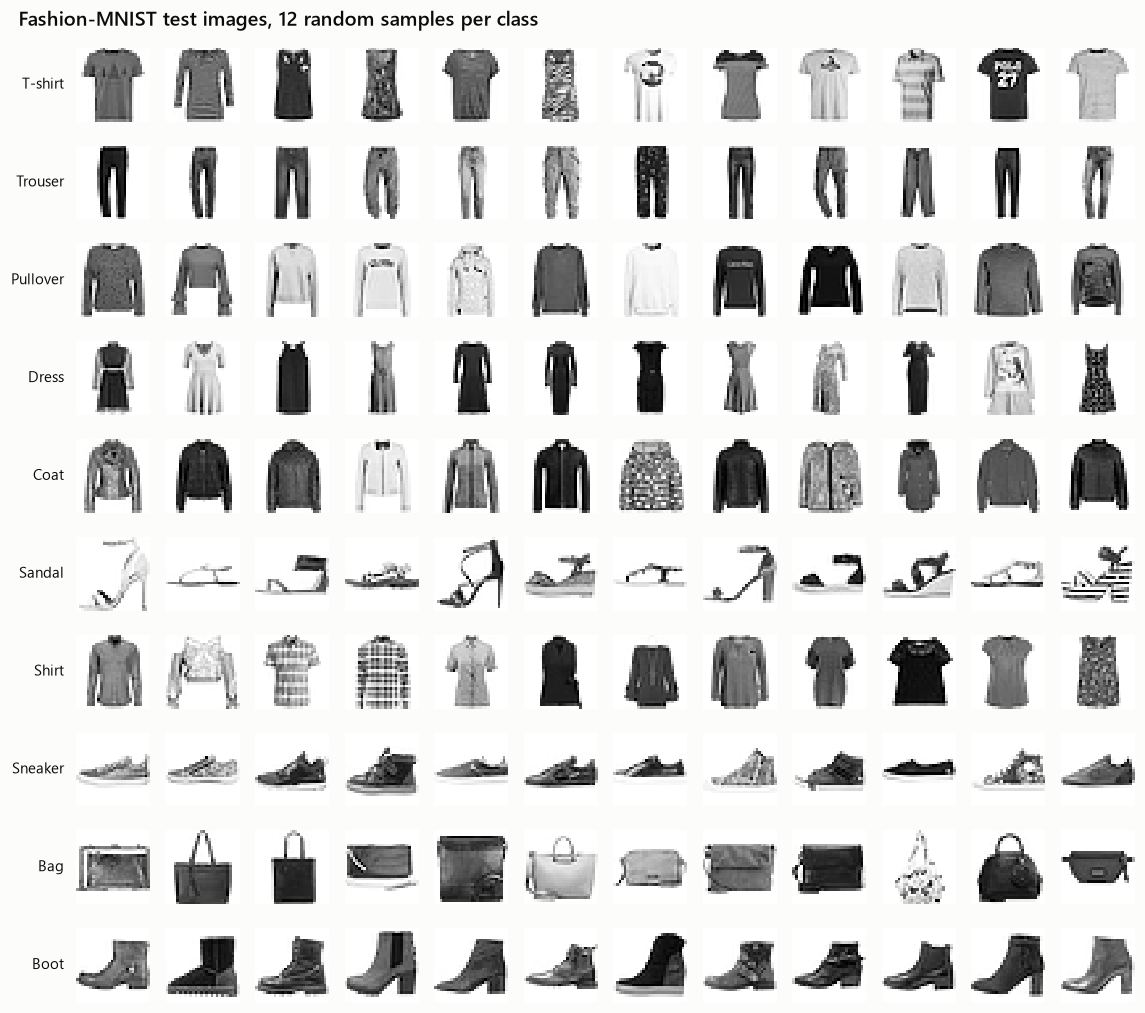

Training images per class: {'T-shirt': np.int64(6000), 'Trouser': np.int64(6000), 'Pullover': np.int64(6000), 'Dress': np.int64(6000), 'Coat': np.int64(6000), 'Sandal': np.int64(6000), 'Shirt': np.int64(6000), 'Sneaker': np.int64(6000), 'Bag': np.int64(6000), 'Boot': np.int64(6000)}
Test images per class:     {'T-shirt': np.int64(1000), 'Trouser': np.int64(1000), 'Pullover': np.int64(1000), 'Dress': np.int64(1000), 'Coat': np.int64(1000), 'Sandal': np.int64(1000), 'Shirt': np.int64(1000), 'Sneaker': np.int64(1000), 'Bag': np.int64(1000), 'Boot': np.int64(1000)}


In [9]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 12, figsize=(10.5, 9.4))
for c in range(10):
    idx = rng.choice(np.where(y_test == c)[0], 12, replace=False)
    for j, i in enumerate(idx):
        show_img(axes[c, j], X_test[i])
    axes[c, 0].set_ylabel(SHORT[c], rotation=0, ha='right', va='center', fontsize=9.5, color=INK, labelpad=8)
fig.suptitle('Fashion-MNIST test images, 12 random samples per class', x=0.02, ha='left')
plt.tight_layout()
plt.show()
print('Training images per class:', dict(zip(SHORT, np.bincount(y_train))))
print('Test images per class:    ', dict(zip(SHORT, np.bincount(y_test))))

---
## A · Where does the model fail, and are the errors "reasonable"?

### V1 · Accuracy and confidence per class

**Question:** Which classes are hard, and how confident is the model when it gets them wrong?
**How to read it:** left, accuracy with a 95% interval (and the error count); right, mean confidence when right (blue) vs. when wrong (red). A short gap on the right means **overconfident errors**.

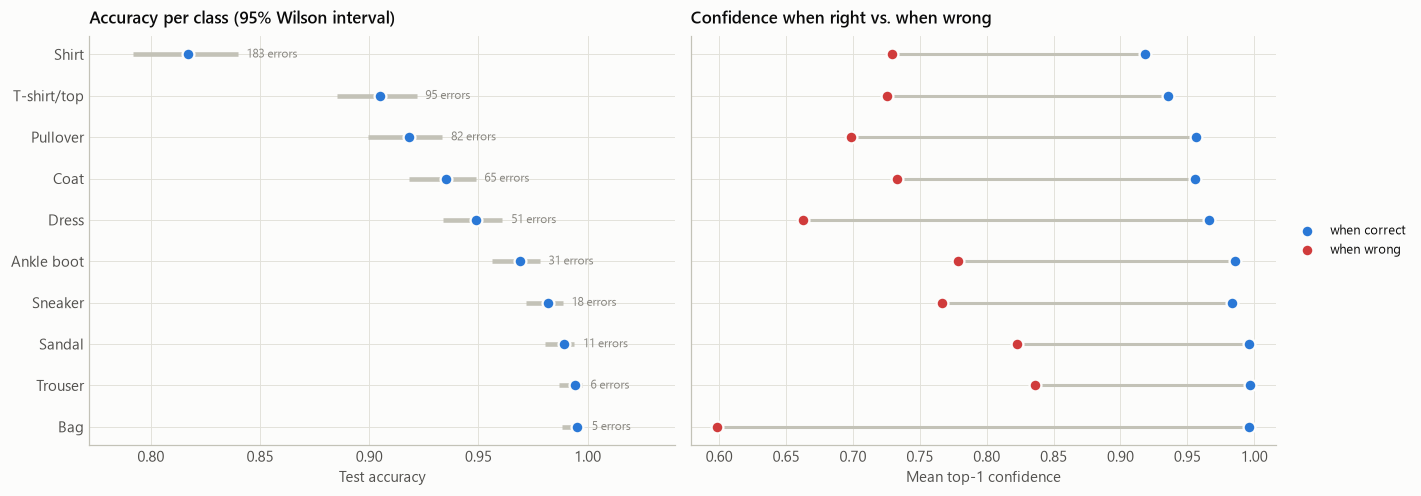

> **V1 · takeaway:** **Shirt** is the hardest class (81.7% accuracy) and alone causes 33.5% of all 547 errors. The three hardest classes are Shirt, T-shirt/top, Pullover - all upper-body garments. When the model is wrong it is still 72.4% confident on average (vs. 97.0% when right).

In [10]:
cls = pd.DataFrame({'class': CLASS_NAMES})
cls['n'] = [(y_test == c).sum() for c in range(10)]
cls['n_err'] = [((y_test == c) & ~correct).sum() for c in range(10)]
cls['acc'] = 1 - cls['n_err'] / cls['n']
cls['conf_correct'] = [conf[(y_test == c) & correct].mean() for c in range(10)]
cls['conf_wrong'] = [conf[(y_test == c) & ~correct].mean() if ((y_test == c) & ~correct).any() else np.nan for c in range(10)]
ci = np.array([wilson(n - e, n) for n, e in zip(cls['n'], cls['n_err'])])
cls['ci_lo'], cls['ci_hi'] = ci[:, 0], ci[:, 1]
ACC_ORDER = cls.sort_values('acc', ascending=False).index.to_numpy()   # best ... worst
y_pos = np.arange(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
ax = axes[0]
for y, c in zip(y_pos, ACC_ORDER):
    ax.hlines(y, cls.loc[c, 'ci_lo'], cls.loc[c, 'ci_hi'], color=AXIS, lw=3)
    ax.scatter(cls.loc[c, 'acc'], y, s=60, color=C_OK, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.text(cls.loc[c, 'ci_hi'] + 0.004, y, f"{cls.loc[c, 'n_err']} errors", va='center', fontsize=8, color=MUTED)
ax.set_xlim(cls['ci_lo'].min() - 0.02, 1.04)
ax.set_yticks(y_pos, [CLASS_NAMES[c] for c in ACC_ORDER])
ax.set_xlabel('Test accuracy')
ax.set_title('Accuracy per class (95% Wilson interval)')

ax = axes[1]
for y, c in zip(y_pos, ACC_ORDER):
    ax.hlines(y, cls.loc[c, 'conf_wrong'], cls.loc[c, 'conf_correct'], color=AXIS, lw=2)
ax.scatter(cls.loc[ACC_ORDER, 'conf_correct'], y_pos, s=60, color=C_OK, label='when correct', zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.scatter(cls.loc[ACC_ORDER, 'conf_wrong'], y_pos, s=60, color=C_ERR, label='when wrong', zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlabel('Mean top-1 confidence')
ax.set_title('Confidence when right vs. when wrong')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

worst = cls.loc[ACC_ORDER[-1]]
top3 = [CLASS_NAMES[c] for c in ACC_ORDER[-3:][::-1]]
all_upper = all(IDX_TO_STRUCTURAL[CLASS_NAMES.index(c)] == 'Upper Body' for c in top3)
takeaway('V1', f"**{worst['class']}** is the hardest class ({pct(worst['acc'])} accuracy) and alone causes "
               f"{pct(worst['n_err'] / cls['n_err'].sum())} of all {cls['n_err'].sum()} errors. The three hardest classes are "
               f"{', '.join(top3)}{' - all upper-body garments' if all_upper else ''}. When the model is wrong it is still "
               f"{pct(conf[~correct].mean())} confident on average (vs. {pct(conf[correct].mean())} when right).")

### V2 · Confusion matrix, reordered by error similarity

**Question:** Do the errors form groups of look-alike classes? Lab 02's advice: reorder rows and columns by error similarity to reveal blocks.
**How to read it:** off-diagonal cells only, on a log colour scale. The grey diagonal holds the correct counts. The dendrogram on top shows which classes the model mixes up with each other, and the framed blocks are the clusters it finds.

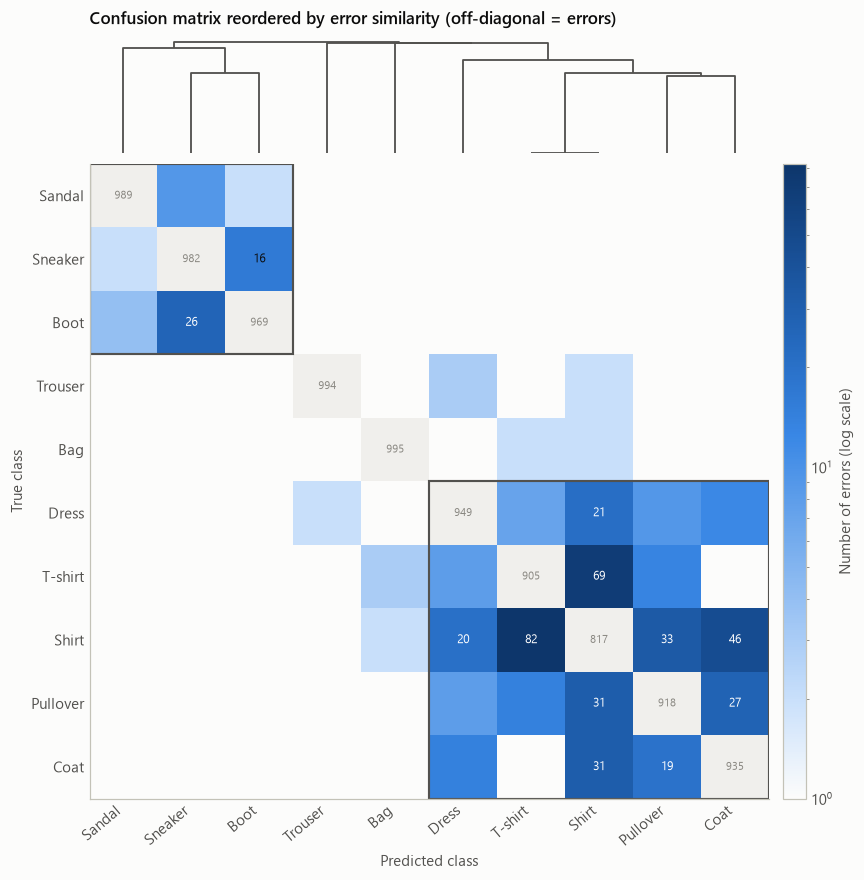

> **V2 · takeaway:** Sorting by error similarity reveals 2 confusion block(s): {T-shirt, Pullover, Dress, Coat, Shirt}; {Sandal, Sneaker, Boot}. 95.8% of all errors happen inside these blocks, and only 3 errors cross between footwear and the rest. The mistakes are look-alike mistakes, not random noise.

In [11]:
C = np.zeros((10, 10), dtype=int)
np.add.at(C, (y_test, preds), 1)
E = C.copy()
np.fill_diagonal(E, 0)
S = E + E.T                                       # symmetric "how often are i and j mixed up"
D = 1 - S / S.max()
np.fill_diagonal(D, 0)
LINK = linkage(squareform(D, checks=False), method='average')
ORDER = leaves_list(LINK)                         # class order reused by later plots
BLOCK = fcluster(LINK, t=4, criterion='maxclust')

fig = plt.figure(figsize=(8.4, 9.0))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 6], width_ratios=[30, 1], hspace=0.03, wspace=0.04)
ax_d, ax, cax = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
with plt.rc_context({'lines.linewidth': 1.2}):
    dendrogram(LINK, ax=ax_d, color_threshold=0, above_threshold_color=INK2, no_labels=True)
ax_d.set_xlim(0, 100)
ax_d.axis('off')
ax_d.set_title('Confusion matrix reordered by error similarity (off-diagonal = errors)')

M = E[np.ix_(ORDER, ORDER)].astype(float)
cmap = BLUES.copy()
cmap.set_bad(SURFACE)
im = ax.imshow(np.ma.masked_where(M == 0, M), cmap=cmap, norm=LogNorm(vmin=1, vmax=M.max()), extent=(0, 100, 100, 0),
               aspect='auto')   # 'auto' keeps the columns aligned with the dendrogram leaves
for k, c in enumerate(ORDER):
    ax.add_patch(Rectangle((10 * k, 10 * k), 10, 10, fc=NEUTRAL, ec='none'))
    ax.text(10 * k + 5, 10 * k + 5, str(C[c, c]), ha='center', va='center', fontsize=7.5, color=MUTED)
thr = 2 * np.sqrt(M.max())          # white text on the darker half of the log scale
for r in range(10):
    for q in range(10):
        if r != q and M[r, q] >= 15:
            ax.text(10 * q + 5, 10 * r + 5, int(M[r, q]), ha='center', va='center', fontsize=8,
                    color='white' if M[r, q] > thr else INK)
for b in np.unique(BLOCK):
    ks = np.where(BLOCK[ORDER] == b)[0]
    if len(ks) > 1:
        ax.add_patch(Rectangle((10 * ks.min(), 10 * ks.min()), 10 * len(ks), 10 * len(ks), fill=False, ec=INK2, lw=1.4))
ax.set_xticks(5 + 10 * np.arange(10), [SHORT[c] for c in ORDER], rotation=40, ha='right')
ax.set_yticks(5 + 10 * np.arange(10), [SHORT[c] for c in ORDER])
ax.grid(False)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
fig.colorbar(im, cax=cax, label='Number of errors (log scale)')
plt.show()

blocks = {}
for c in range(10):
    blocks.setdefault(BLOCK[c], []).append(c)
multi = [b for b in blocks.values() if len(b) > 1]
within = sum(E[i, j] for b in multi for i in b for j in b) / E.sum()
fw = STRUCTURAL_GROUPS['Footwear']
cross_fw = sum(E[i, j] for i in range(10) for j in range(10) if (i in fw) != (j in fw))
takeaway('V2', f"Sorting by error similarity reveals {len(multi)} confusion block(s): "
               + '; '.join('{' + ', '.join(SHORT[c] for c in b) + '}' for b in multi)
               + f". {pct(within)} of all errors happen inside these blocks, and only {cross_fw} errors cross between "
               f"footwear and the rest. The mistakes are look-alike mistakes, not random noise.")

### V3 · Error-flow network

**Question:** Where do the errors *go*? The confusion matrix is symmetric-looking, but errors have a direction.
**How to read it:** each arrow is a flow *true → predicted*. Arrow width = number of errors, and the top-3 flows are red. Node size = how many errors the class produces. Classes sit on the circle in the dendrogram order from V2, so neighbours are look-alikes. Flows below 1% of all errors (minimum 5) are hidden.

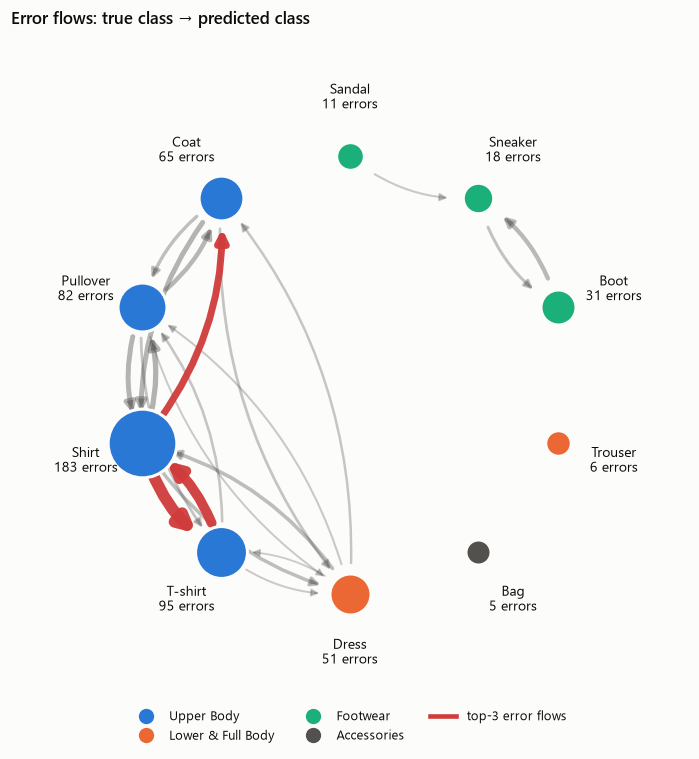

> **V3 · takeaway:** The five strongest flows are Shirt→T-shirt (82), T-shirt→Shirt (69), Shirt→Coat (46), Shirt→Pullover (33), Coat→Shirt (31); together they make up 47.7% of all errors. Asymmetry check: Shirt→T-shirt happens 82× but the reverse only 69×.

In [12]:
fig, ax = plt.subplots(figsize=(8, 8))
theta = np.pi / 2 - 2 * np.pi * np.arange(10) / 10
pos = {c: np.array([np.cos(t), np.sin(t)]) for c, t in zip(ORDER, theta)}
flows = sorted([(E[i, j], i, j) for i in range(10) for j in range(10) if i != j and E[i, j] > 0], reverse=True)
min_n = max(5, int(0.01 * E.sum()))
shown = [f for f in flows if f[0] >= min_n]
nmax = shown[0][0]
for rank, (n, i, j) in enumerate(shown[::-1]):          # draw strongest last (on top)
    top = rank >= len(shown) - 3
    ax.add_patch(FancyArrowPatch(pos[i], pos[j], connectionstyle='arc3,rad=0.2', arrowstyle='-|>',
                                 mutation_scale=9 + 10 * n / nmax, lw=0.6 + 7 * n / nmax,
                                 color=C_ERR if top else INK2, alpha=0.95 if top else 0.25 + 0.45 * n / nmax,
                                 shrinkA=20, shrinkB=20, zorder=2))
out_err = E.sum(1)
for c in range(10):
    x, y = pos[c]
    ax.scatter(x, y, s=220 + 1800 * out_err[c] / out_err.max(), color=GROUP_COLORS[IDX_TO_STRUCTURAL[c]],
               edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.text(1.27 * x, 1.27 * y, f'{SHORT[c]}\n{out_err[c]} errors', ha='center', va='center', fontsize=9, color=INK)
ax.set_xlim(-1.55, 1.55); ax.set_ylim(-1.55, 1.55); ax.set_aspect('equal'); ax.axis('off')
handles = [Line2D([], [], marker='o', ls='', color=col, ms=9, label=g) for g, col in GROUP_COLORS.items()]
handles.append(Line2D([], [], color=C_ERR, lw=3, label='top-3 error flows'))
ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=3)
ax.set_title('Error flows: true class → predicted class')
plt.show()

top5 = flows[:5]
takeaway('V3', 'The five strongest flows are ' + ', '.join(f'{SHORT[i]}→{SHORT[j]} ({n})' for n, i, j in top5)
         + f'; together they make up {pct(sum(f[0] for f in top5) / E.sum())} of all errors. '
         + f"Asymmetry check: {SHORT[top5[0][1]]}→{SHORT[top5[0][2]]} happens {top5[0][0]}× but the reverse only "
           f"{E[top5[0][2], top5[0][1]]}×.")

### V4 · Are the errors semantically plausible? Testing the team's two groupings

**Question:** The team proposed two super-category schemes: *structural* (silhouette and body placement) and *seasonal*. Which one explains the errors?
**How to read it:** left, for each class, the errors that stay inside the structural group (blue) vs. those that leave it (orange). Right, the share of within-group errors observed vs. what we would expect if every class spread its errors evenly over the other 9 classes. Note: *Bag* is alone in its group, so all its errors leave the group.

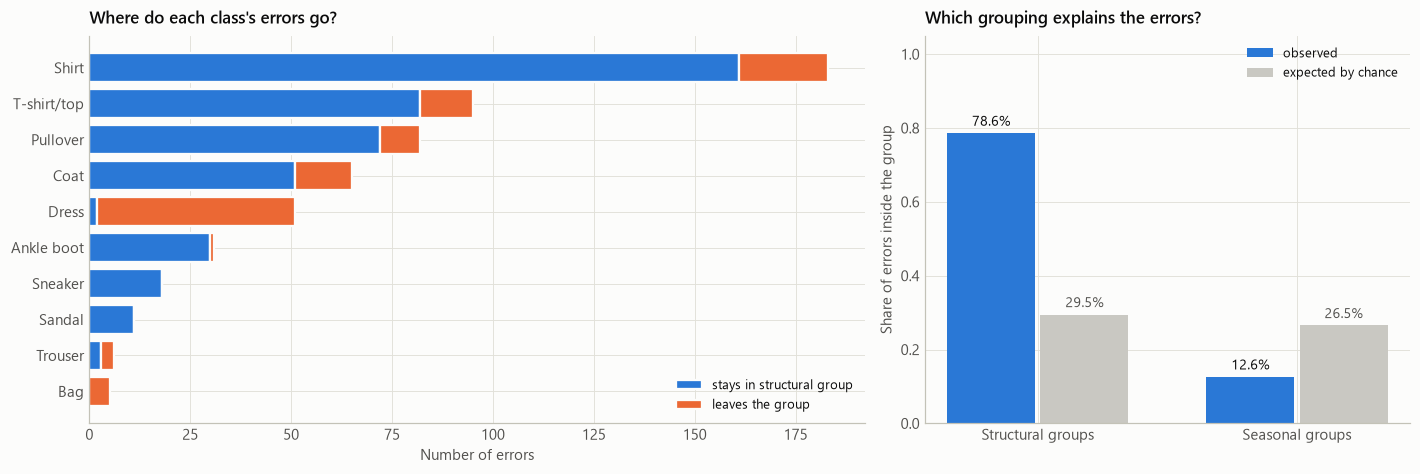

> **V4 · takeaway:** 78.6% of errors stay inside the structural group (chance: 29.5%), but only 12.6% stay inside the seasonal group (chance: 26.5%). The model's confusions follow **shape**, not season or function. The seasonal grouping can be dropped as an explanation.

In [13]:
same_struct = np.array([IDX_TO_STRUCTURAL[t] == IDX_TO_STRUCTURAL[p] for t, p in zip(y_test, preds)])
same_season = np.array([IDX_TO_SEASONAL[t] == IDX_TO_SEASONAL[p] for t, p in zip(y_test, preds)])


def chance_share(group_map):
    exp = sum(E[c].sum() * (sum(group_map[k] == group_map[c] for k in range(10)) - 1) / 9 for c in range(10))
    return exp / E.sum()


obs = {'Structural groups': same_struct[~correct].mean(), 'Seasonal groups': same_season[~correct].mean()}
exp = {'Structural groups': chance_share(IDX_TO_STRUCTURAL), 'Seasonal groups': chance_share(IDX_TO_SEASONAL)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
order = ACC_ORDER
w_in = np.array([((y_test == c) & ~correct & same_struct).sum() for c in order])
w_out = np.array([((y_test == c) & ~correct & ~same_struct).sum() for c in order])
ax.barh(y_pos, w_in, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label='stays in structural group')
ax.barh(y_pos, w_out, left=w_in, color=SERIES[1], edgecolor=SURFACE, linewidth=1.5, label='leaves the group')
ax.set_yticks(y_pos, [CLASS_NAMES[c] for c in order])
ax.set_xlabel('Number of errors')
ax.set_title('Where do each class\'s errors go?')
ax.legend(loc='lower right')

ax = axes[1]
xs = np.arange(2)
ax.bar(xs - 0.18, [obs[k] for k in obs], width=0.34, color=SERIES[0], label='observed')
ax.bar(xs + 0.18, [exp[k] for k in exp], width=0.34, color=C_CONTEXT, label='expected by chance')
for x, k in zip(xs, obs):
    ax.text(x - 0.18, obs[k] + 0.02, pct(obs[k]), ha='center', fontsize=9, color=INK)
    ax.text(x + 0.18, exp[k] + 0.02, pct(exp[k]), ha='center', fontsize=9, color=INK2)
ax.set_xticks(xs, list(obs))
ax.set_ylim(0, 1.05)
ax.set_ylabel('Share of errors inside the group')
ax.set_title('Which grouping explains the errors?')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

takeaway('V4', f"{pct(obs['Structural groups'])} of errors stay inside the structural group (chance: {pct(exp['Structural groups'])}), "
               f"but only {pct(obs['Seasonal groups'])} stay inside the seasonal group (chance: {pct(exp['Seasonal groups'])}). "
               f"The model's confusions follow **shape**, not season or function. The seasonal grouping can be dropped as an explanation.")

---
## B · Does the model know when it is wrong?

### V5 · Confidence distributions and calibration

**Question:** Can confidence separate right from wrong predictions, and is it calibrated?
**How to read it:** (a) confidence histograms for correct and wrong predictions, on a log scale. (b) Reliability diagram: blue bars = accuracy inside each confidence bin, the red part = the gap to the bin's mean confidence. Bars below the diagonal mean **overconfidence**. (c) Expected calibration error (ECE) per class.

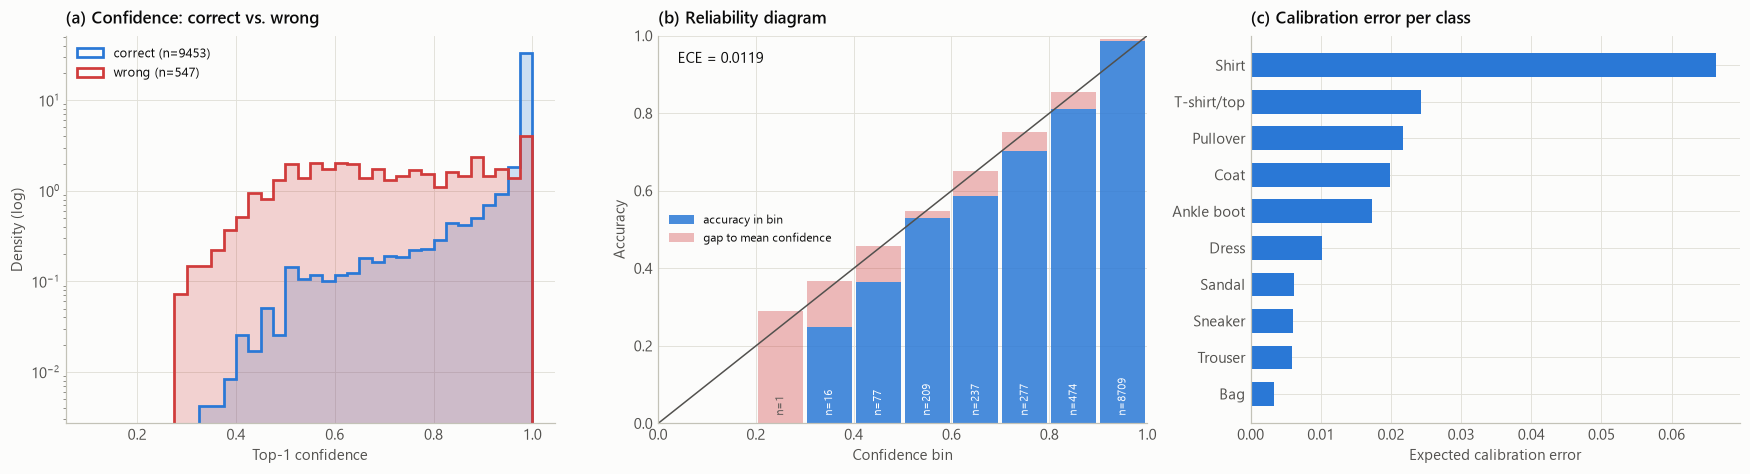

> **V5 · takeaway:** Overall the model is slightly overconfident (mean confidence 95.7% vs. accuracy 94.5%, ECE 0.012). The problem is the tail: **21.6% of all errors are made with ≥90% confidence**, so a confidence threshold alone cannot catch them. The worst-calibrated class is Shirt (ECE 0.066).

In [14]:
def ece_score(cf, ok, n_bins=15):
    edges = np.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (cf > lo) & (cf <= hi)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - cf[m].mean())
    return e


fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]
bins = np.linspace(0.1, 1, 37)
for mask, col, lab in [(correct, C_OK, 'correct'), (~correct, C_ERR, 'wrong')]:
    ax.hist(conf[mask], bins=bins, density=True, histtype='stepfilled', color=col, alpha=0.22)
    ax.hist(conf[mask], bins=bins, density=True, histtype='step', color=col, lw=1.8, label=f'{lab} (n={mask.sum()})')
ax.set_yscale('log')
ax.set_xlabel('Top-1 confidence')
ax.set_ylabel('Density (log)')
ax.set_title('(a) Confidence: correct vs. wrong')
ax.legend(loc='upper left')

ax = axes[1]
edges = np.linspace(0, 1, 11)
centers, accs, confs, ns = [], [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() > 0:
        centers.append((lo + hi) / 2); accs.append(correct[m].mean()); confs.append(conf[m].mean()); ns.append(m.sum())
centers, accs, confs = map(np.array, (centers, accs, confs))
ax.plot([0, 1], [0, 1], color=INK2, lw=1)
ax.bar(centers, accs, width=0.092, color=C_OK, alpha=0.85, label='accuracy in bin')
ax.bar(centers, confs - accs, bottom=accs, width=0.092, color=C_ERR, alpha=0.35, label='gap to mean confidence')
for x, a, n in zip(centers, accs, ns):
    ax.text(x, 0.02, f'n={n}', rotation=90, ha='center', va='bottom', fontsize=7, color='white' if a > 0.15 else INK2)
ece_all = ece_score(conf, correct)
ax.text(0.04, 0.93, f'ECE = {ece_all:.4f}', fontsize=10, color=INK, transform=ax.transAxes)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('Confidence bin'); ax.set_ylabel('Accuracy')
ax.set_title('(b) Reliability diagram')
ax.legend(loc='center left', fontsize=8)

ax = axes[2]
ece_cls = np.array([ece_score(conf[y_test == c], correct[y_test == c]) for c in range(10)])
o = np.argsort(ece_cls)
ax.barh(np.arange(10), ece_cls[o], color=C_OK, height=0.65)
ax.set_yticks(np.arange(10), [CLASS_NAMES[c] for c in o])
ax.set_xlabel('Expected calibration error')
ax.set_title('(c) Calibration error per class')
plt.tight_layout()
plt.show()

hi_conf_err = (conf[~correct] >= 0.9).mean()
direction = 'overconfident' if conf.mean() > correct.mean() else 'underconfident'
takeaway('V5', f"Overall the model is slightly {direction} (mean confidence {pct(conf.mean())} vs. accuracy {pct(correct.mean())}, "
               f"ECE {ece_all:.3f}). The problem is the tail: **{pct(hi_conf_err)} of all errors are made with ≥90% confidence**, "
               f"so a confidence threshold alone cannot catch them. The worst-calibrated class is {CLASS_NAMES[o[-1]]} (ECE {ece_cls[o[-1]]:.3f}).")

### V6 · Confidence of right and wrong answers, per class (split violins)

**Question:** Are some classes confidently wrong more often than others?
**How to read it:** each class has a split violin. The left half (blue) shows the confidence of correct predictions, the right half (red) of wrong ones, with a short line at the median. A tall red half near 1.0 means the class produces **confident mistakes**.

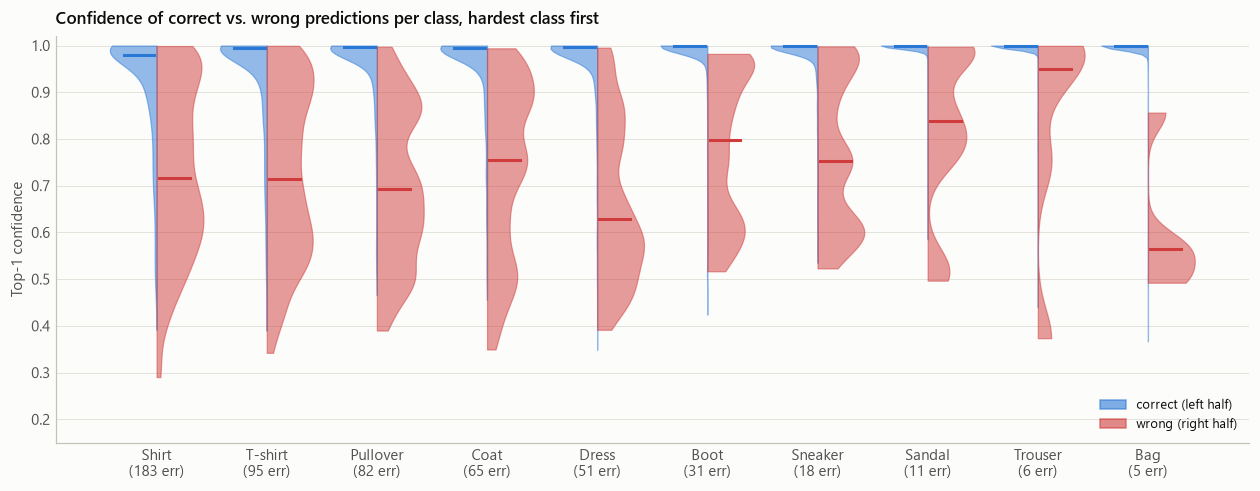

> **V6 · takeaway:** Wrong Sandal predictions have the highest median confidence (83.9%): these are confident, 'silent' errors. Wrong Dress predictions are the most hesitant (median 62.8%).

In [15]:
fig, ax = plt.subplots(figsize=(14, 4.8))
order = ACC_ORDER[::-1]                      # hardest first
for k, c in enumerate(order):
    for mask, side, col in [(correct, -1, C_OK), (~correct, 1, C_ERR)]:
        v = conf[(y_test == c) & mask]
        if len(v) < 3 or np.ptp(v) < 1e-6:
            continue
        try:
            parts = ax.violinplot([v], positions=[k], widths=0.85, showextrema=False, bw_method=0.25)
        except np.linalg.LinAlgError:
            continue
        body = parts['bodies'][0]
        verts = body.get_paths()[0].vertices
        verts[:, 0] = np.clip(verts[:, 0], -np.inf, k) if side < 0 else np.clip(verts[:, 0], k, np.inf)
        verts[:, 1] = np.clip(verts[:, 1], None, 1.0)
        body.set_facecolor(col); body.set_edgecolor(col); body.set_alpha(0.5); body.set_linewidth(0.8)
        med = np.median(v)
        ax.plot([k + side * 0.02, k + side * 0.3], [med, med], color=col, lw=2)
ax.set_xticks(np.arange(10), [f'{SHORT[c]}\n({cls.loc[c, "n_err"]} err)' for c in order])
ax.set_ylabel('Top-1 confidence')
ax.set_ylim(0.15, 1.02)
ax.grid(axis='x', visible=False)
ax.legend(handles=[Patch(color=C_OK, alpha=0.6, label='correct (left half)'), Patch(color=C_ERR, alpha=0.6, label='wrong (right half)')], loc='lower right')
ax.set_title('Confidence of correct vs. wrong predictions per class, hardest class first')
plt.show()

med_wrong = {c: np.median(conf[(y_test == c) & ~correct]) for c in range(10) if ((y_test == c) & ~correct).sum() >= 10}
cmax = max(med_wrong, key=med_wrong.get)
cmin = min(med_wrong, key=med_wrong.get)
takeaway('V6', f"Wrong {CLASS_NAMES[cmax]} predictions have the highest median confidence ({pct(med_wrong[cmax])}): these are confident, "
               f"'silent' errors. Wrong {CLASS_NAMES[cmin]} predictions are the most hesitant (median {pct(med_wrong[cmin])}).")

### V7 · Risk-coverage: what if the model could say "I don't know"?

**Question:** If the model abstains on its least-confident predictions, how much does accuracy improve, and for which garment groups?
**How to read it:** x = share of test images the model still answers (coverage), y = accuracy on those. Steep curves mean confidence is a good error detector for that group.

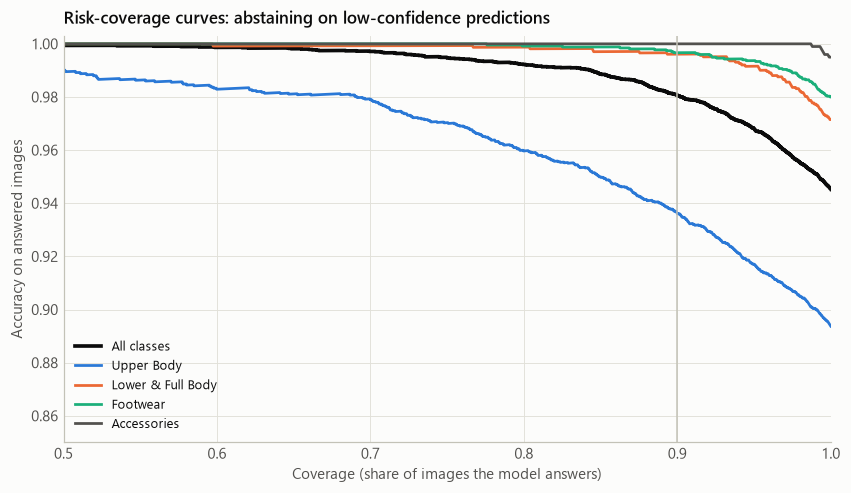

> **V7 · takeaway:** Abstaining on the 10% least-confident images lifts accuracy from 94.5% to 98.1% and removes 68.2% of all errors. At 90% coverage Upper Body reaches only 93.6%, against 99.7% for Footwear: abstention helps least where the errors are.

In [16]:
def risk_coverage(cf, ok):
    o = np.argsort(-cf, kind='stable')
    n = np.arange(1, len(cf) + 1)
    return n / len(cf), np.cumsum(ok[o]) / n


fig, ax = plt.subplots(figsize=(9, 4.8))
cov, acc_c = risk_coverage(conf, correct)
ax.plot(cov, acc_c, color=INK, lw=2.4, label='All classes')
group_at90 = {}
for g, idxs in STRUCTURAL_GROUPS.items():
    m = np.isin(y_test, idxs)
    cv, ac = risk_coverage(conf[m], correct[m])
    ax.plot(cv, ac, color=GROUP_COLORS[g], lw=1.8, label=g)
    group_at90[g] = ac[int(0.9 * len(ac)) - 1]
ax.axvline(0.9, color=AXIS, lw=1)
ax.set_xlim(0.5, 1.0)
ax.set_ylim(min(0.85, acc_c[-1] - 0.05), 1.003)
ax.set_xlabel('Coverage (share of images the model answers)')
ax.set_ylabel('Accuracy on answered images')
ax.set_title('Risk-coverage curves: abstaining on low-confidence predictions')
ax.legend(loc='lower left')
plt.show()

k90 = int(0.9 * len(conf))
kept = correct[np.argsort(-conf, kind='stable')[:k90]]
removed = 1 - (~kept).sum() / (~correct).sum()
takeaway('V7', f"Abstaining on the 10% least-confident images lifts accuracy from {pct(correct.mean())} to {pct(kept.mean())} and removes "
               f"{pct(removed)} of all errors. At 90% coverage Upper Body reaches only {pct(group_at90['Upper Body'])}, against "
               f"{pct(group_at90['Footwear'])} for Footwear: abstention helps least where the errors are.")

### V8 · Near misses: is the right answer usually the runner-up?

**Question:** When the model is wrong, how close was it?
**How to read it:** (a) where the true class ranks among the model's choices when the top-1 prediction is wrong. (b) Top-1 vs. top-2 accuracy per class: a long bar means the right answer is usually the second guess.

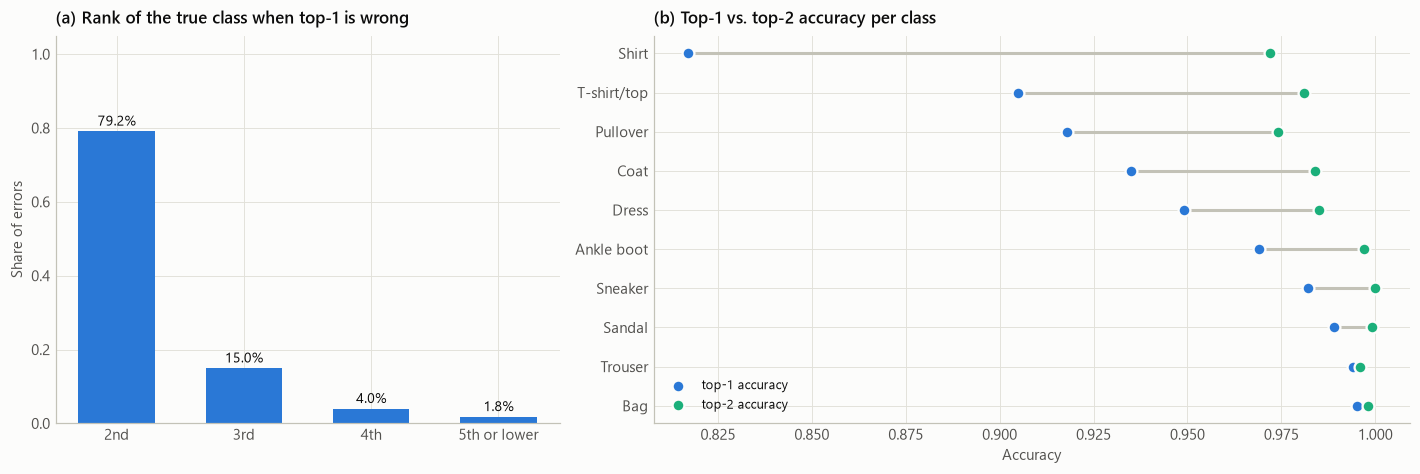

> **V8 · takeaway:** In 79.2% of the errors the true class is the model's **second choice**. Top-2 accuracy is 98.9% overall and 97.2% for Shirt. Most errors are near misses between two candidates, not a complete misreading of the image.

In [17]:
rank_err = true_rank[~correct]
labels_r = ['2nd', '3rd', '4th', '5th or lower']
counts_r = np.array([(rank_err == 2).sum(), (rank_err == 3).sum(), (rank_err == 4).sum(), (rank_err >= 5).sum()])
top2_acc = np.array([(true_rank[y_test == c] <= 2).mean() for c in range(10)])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
ax.bar(labels_r, counts_r / counts_r.sum(), color=C_OK, width=0.6)
for k, v in enumerate(counts_r / counts_r.sum()):
    ax.text(k, v + 0.015, pct(v), ha='center', fontsize=9)
ax.set_ylabel('Share of errors')
ax.set_title('(a) Rank of the true class when top-1 is wrong')
ax.set_ylim(0, 1.05)

ax = axes[1]
for y, c in zip(y_pos, ACC_ORDER):
    ax.hlines(y, cls.loc[c, 'acc'], top2_acc[c], color=AXIS, lw=2)
ax.scatter(cls.loc[ACC_ORDER, 'acc'], y_pos, s=60, color=C_OK, label='top-1 accuracy', zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.scatter(top2_acc[ACC_ORDER], y_pos, s=60, color=SERIES[2], label='top-2 accuracy', zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y_pos, [CLASS_NAMES[c] for c in ACC_ORDER])
ax.set_xlabel('Accuracy')
ax.set_title('(b) Top-1 vs. top-2 accuracy per class')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

takeaway('V8', f"In {pct(counts_r[0] / counts_r.sum())} of the errors the true class is the model's **second choice**. Top-2 accuracy is "
               f"{pct((true_rank <= 2).mean())} overall and {pct(top2_acc[ACC_ORDER[-1]])} for {CLASS_NAMES[ACC_ORDER[-1]]}. Most errors are "
               f"near misses between two candidates, not a complete misreading of the image.")

---
## C · What does the output space look like?

### V9 · RadViz of the probability vectors

**Question:** How do the 10-dimensional probability vectors spread between the classes?
**How to read it:** each class is an anchor on the circle, in the dendrogram order from V2. Each test image is placed at the probability-weighted mean of the anchors. A confident prediction sits on its anchor. A point **on the chord between two anchors** is torn between those two classes, and points near the centre are spread over many. Left: raw probabilities, errors in red. Right: probabilities softened with p^(1/3), so secondary preferences become visible, coloured by output entropy.

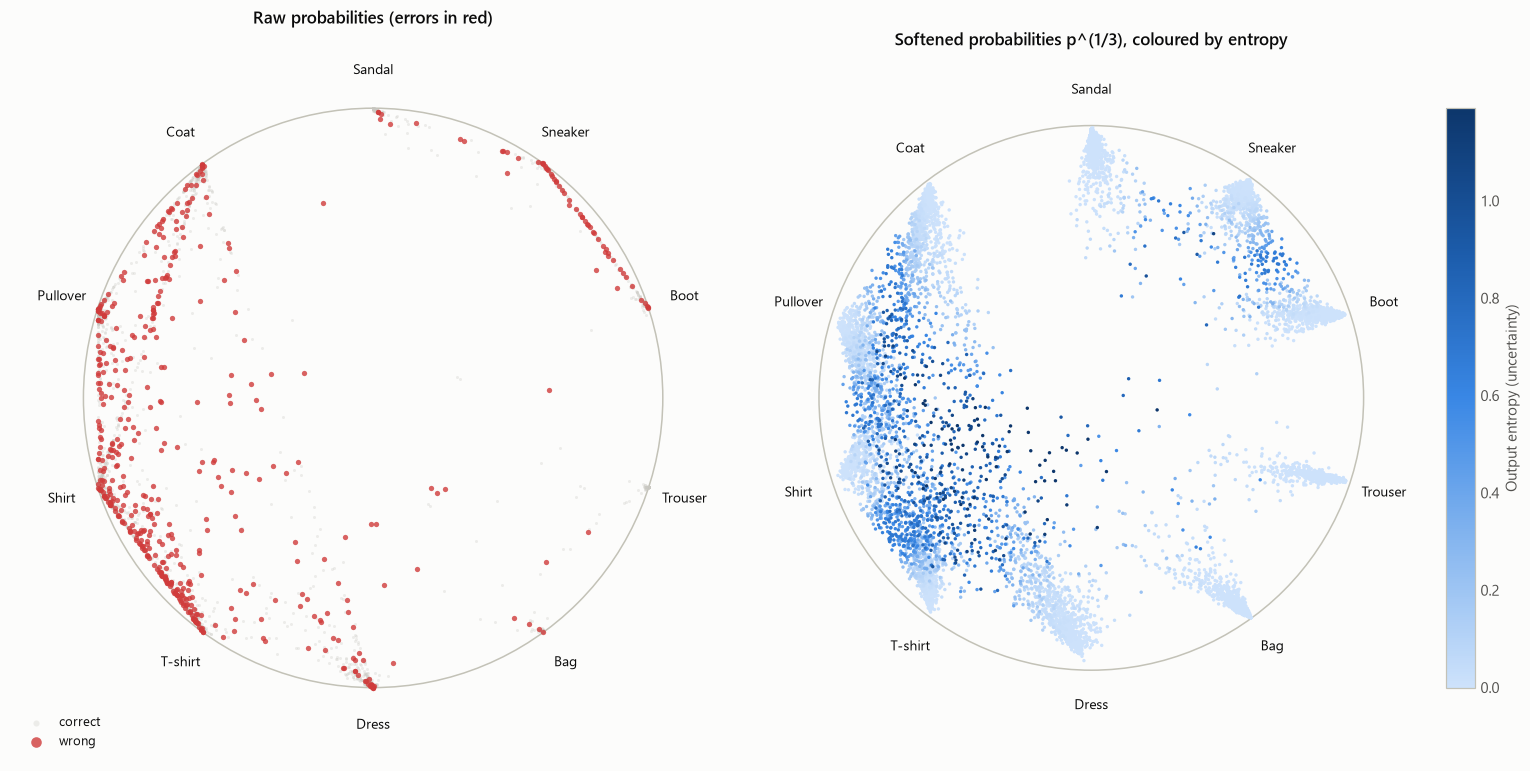

> **V9 · takeaway:** 11.5% of all test images have a runner-up class with >10% probability. The most frequent hesitations are T-shirt/Shirt (360), Coat/Shirt (161), Pullover/Shirt (134), Pullover/Coat (110), Sneaker/Boot (100). These chords are the "fault lines" of the model; the footwear and clothing anchors are almost never connected.

In [18]:
anchors = np.zeros((10, 2))
for k, c in enumerate(ORDER):
    t = np.pi / 2 - 2 * np.pi * k / 10
    anchors[c] = [np.cos(t), np.sin(t)]
R_raw = probs @ anchors
soft = probs ** (1 / 3)
soft /= soft.sum(1, keepdims=True)
R_soft = soft @ anchors

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax in axes:
    ax.add_patch(Circle((0, 0), 1, fill=False, ec=AXIS, lw=1))
    for c in range(10):
        ax.text(*(1.13 * anchors[c]), SHORT[c], ha='center', va='center', fontsize=9, color=INK)
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_aspect('equal'); ax.axis('off')
ax = axes[0]
ax.scatter(*R_raw[correct].T, s=4, color=C_CONTEXT, alpha=0.3, lw=0, label='correct')
ax.scatter(*R_raw[~correct].T, s=12, color=C_ERR, alpha=0.8, lw=0, label='wrong')
ax.legend(loc='lower left', markerscale=2)
ax.set_title('Raw probabilities (errors in red)', loc='center')
ax = axes[1]
o = np.argsort(entropy)
sc = ax.scatter(*R_soft[o].T, c=entropy[o], cmap=BLUES_MARK, s=5, lw=0, vmin=0, vmax=np.quantile(entropy, 0.995))
fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02, label='Output entropy (uncertainty)')
ax.set_title('Softened probabilities p^(1/3), coloured by entropy', loc='center')
plt.tight_layout()
plt.show()

amb = p_second > 0.1
pair_counts = pd.Series([tuple(sorted((a, b))) for a, b in zip(preds[amb], second[amb])]).value_counts()
takeaway('V9', f"{pct(amb.mean())} of all test images have a runner-up class with >10% probability. The most frequent hesitations are "
               + ', '.join(f'{SHORT[a]}/{SHORT[b]} ({n})' for (a, b), n in pair_counts.head(5).items())
               + '. These chords are the "fault lines" of the model; the footwear and clothing anchors are almost never connected.')

### V10 · Map of the output space

**Question:** Which outputs look alike to the model, and where do the errors sit?
**How to read it:** the 10-d log-probability vectors are projected to 2D (UMAP if installed, else t-SNE). Errors that sit **between** clusters are visible uncertainty. Errors that sit **inside** another class's cluster are "camouflaged": from the outputs alone they look exactly like correct predictions of that class. (As Lecture 03 warns, cluster sizes and distances between clusters in t-SNE/UMAP mean little; read neighbourhoods, not distances.)

output-space projection: 14s


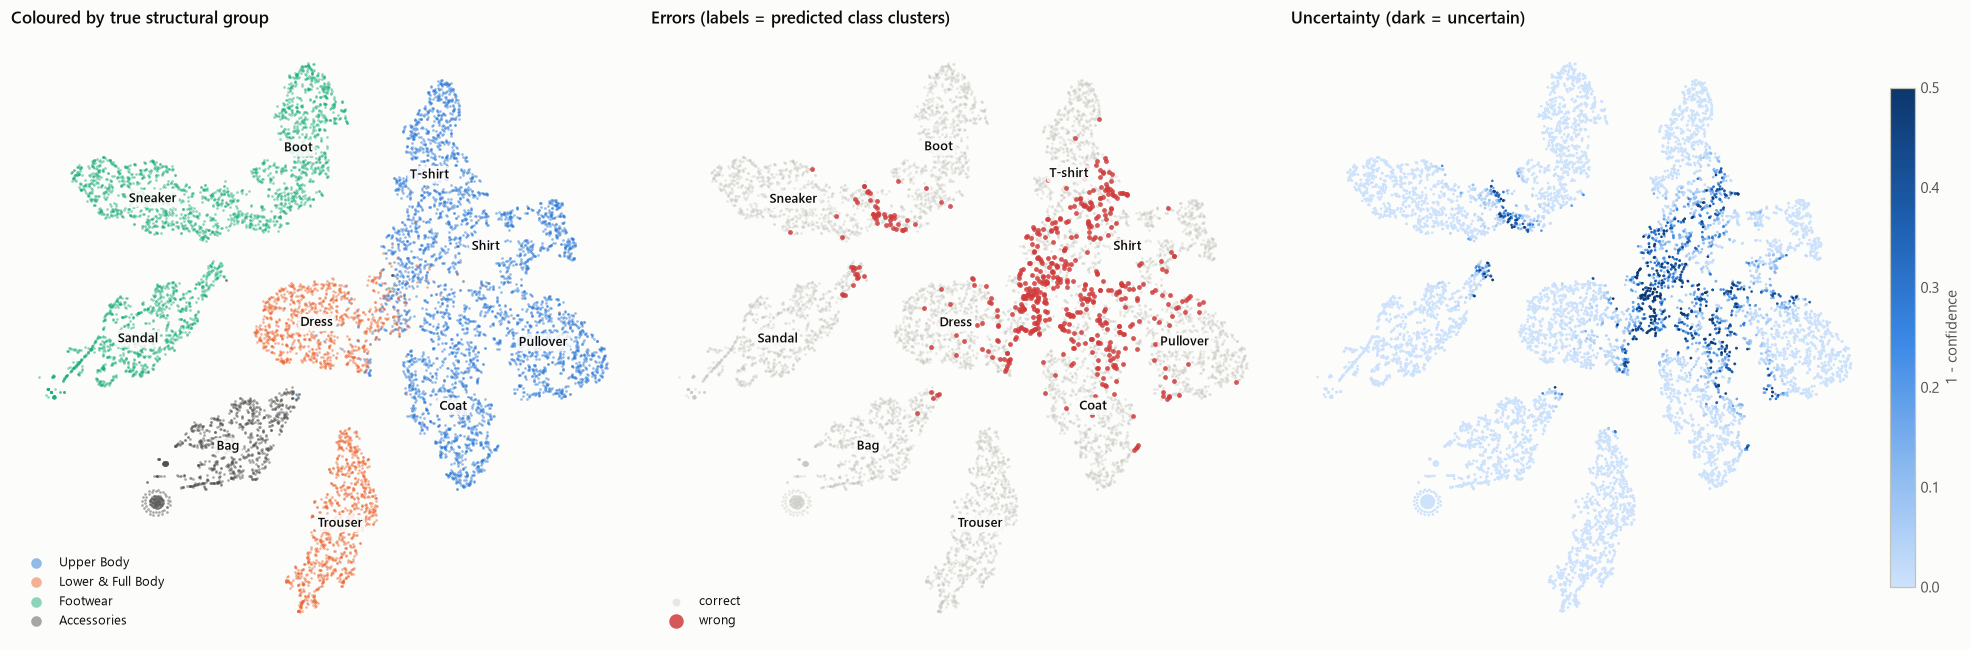

> **V10 · takeaway:** 26.1% of the errors are **camouflaged**: at least 8 of their 10 nearest neighbours in output space are correctly classified images of the predicted class. No output-based check can flag them; only the input view (Sections D-F) can explain them.

In [19]:
def embed_2d(feats, seed=SEED):
    if HAS_UMAP:
        return umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=seed).fit_transform(feats)
    return TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=seed, n_jobs=-1).fit_transform(feats)


F_out = np.log(np.clip(probs, 1e-7, 1.0))
t0 = time.time()
EMB_OUT = embed_2d(F_out)
print(f'output-space projection: {time.time() - t0:.0f}s')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
ax = axes[0]
for g, idxs in STRUCTURAL_GROUPS.items():
    m = np.isin(y_test, idxs)
    ax.scatter(*EMB_OUT[m].T, s=3, color=GROUP_COLORS[g], alpha=0.5, lw=0, label=g)
label_clusters(ax, EMB_OUT, y_test)
ax.legend(loc='lower left', markerscale=4)
ax.set_title('Coloured by true structural group')
ax = axes[1]
ax.scatter(*EMB_OUT[correct].T, s=3, color=C_CONTEXT, alpha=0.4, lw=0, label='correct')
ax.scatter(*EMB_OUT[~correct].T, s=10, color=C_ERR, alpha=0.85, lw=0, label='wrong')
label_clusters(ax, EMB_OUT, preds)
ax.legend(loc='lower left', markerscale=3)
ax.set_title('Errors (labels = predicted class clusters)')
ax = axes[2]
o = np.argsort(-conf)
sc = ax.scatter(*EMB_OUT[o].T, c=1 - conf[o], cmap=BLUES_MARK, s=3, lw=0, vmin=0, vmax=0.5)
fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02, label='1 - confidence')
ax.set_title('Uncertainty (dark = uncertain)')
for ax in axes:
    embed_axes(ax)
plt.tight_layout()
plt.show()

nn_o = NearestNeighbors(n_neighbors=11).fit(F_out)
err_idx = np.where(~correct)[0]
_, ind_o = nn_o.kneighbors(F_out[err_idx])
ind_o = ind_o[:, 1:]
camo = ((preds[ind_o] == preds[err_idx][:, None]) & correct[ind_o]).mean(1) >= 0.8
takeaway('V10', f"{pct(camo.mean())} of the errors are **camouflaged**: at least 8 of their 10 nearest neighbours in output space are "
                f"correctly classified images of the predicted class. No output-based check can flag them; only the input view (Sections D-F) can explain them.")

### V11 · The decision boundary between the most-confused pairs

**Question:** For the three most-confused class pairs, how sharp is the boundary?
**How to read it:** x = log P(A) − log P(B) for every test image of either class. Blue = truly A, orange = truly B. The grey band |x| < 1 contains images where the two probabilities differ by less than a factor of e. Mass on the wrong side of 0 means errors, and the overlap shows how blurry the boundary is.

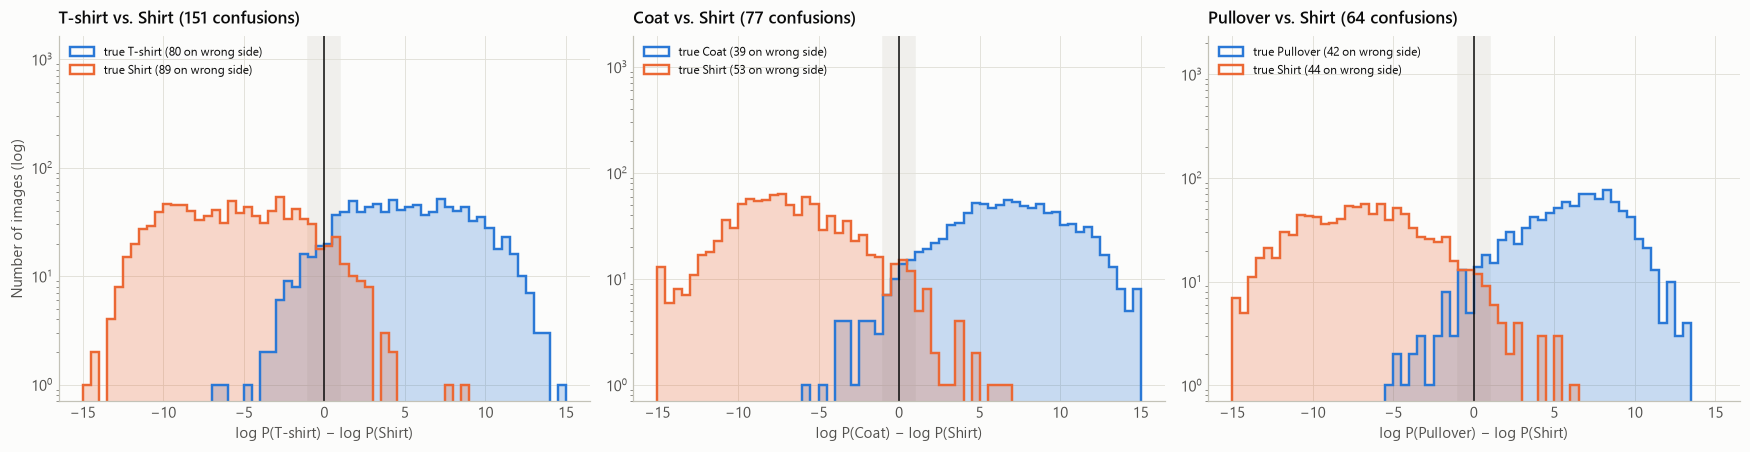

> **V11 · takeaway:** Images "on the fence" (|log-odds| < 1): T-shirt/Shirt: 181, Coat/Shirt: 94, Pullover/Shirt: 97. Of the images on the wrong side of the boundary, 27.2% (T-shirt/Shirt), 30.4% (Coat/Shirt), 30.2% (Pullover/Shirt) are clear votes for the other class (more than 7× more likely, |log-odds| > 2) rather than borderline cases.

In [20]:
sym_pairs = sorted([(S[i, j], i, j) for i in range(10) for j in range(i + 1, 10)], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
fence, clear_wrong = {}, {}
for ax, (n, a, b) in zip(axes, sym_pairs):
    m = np.isin(y_test, [a, b])
    lo = np.clip(np.log(np.clip(probs[m, a], 1e-9, 1)) - np.log(np.clip(probs[m, b], 1e-9, 1)), -15, 15)
    yt = y_test[m]
    bins = np.linspace(-15, 15, 61)
    ax.axvspan(-1, 1, color=NEUTRAL, zorder=0)
    for cl, col, wrong_side in [(a, SERIES[0], lo[yt == a] < 0), (b, SERIES[1], lo[yt == b] > 0)]:
        v = lo[yt == cl]
        ax.hist(v, bins=bins, histtype='stepfilled', color=col, alpha=0.25)
        ax.hist(v, bins=bins, histtype='step', color=col, lw=1.6, label=f'true {SHORT[cl]} ({wrong_side.sum()} on wrong side)')
    ax.axvline(0, color=INK, lw=1)
    ax.set_yscale('log')
    ax.set_ylim(0.7, ax.get_ylim()[1] * 25)          # headroom for the legend
    ax.set_xlabel(f'log P({SHORT[a]}) − log P({SHORT[b]})')
    ax.set_title(f'{SHORT[a]} vs. {SHORT[b]} ({n} confusions)')
    ax.legend(loc='upper left', fontsize=8)
    fence[(a, b)] = int((np.abs(lo) < 1).sum())
    wrong_side = np.r_[lo[yt == a][lo[yt == a] < 0], lo[yt == b][lo[yt == b] > 0]]
    clear_wrong[(a, b)] = (np.abs(wrong_side) > 2).mean() if len(wrong_side) else np.nan
axes[0].set_ylabel('Number of images (log)')
plt.tight_layout()
plt.show()

takeaway('V11', 'Images "on the fence" (|log-odds| < 1): ' + ', '.join(f'{SHORT[a]}/{SHORT[b]}: {n}' for (a, b), n in fence.items())
         + '. Of the images on the wrong side of the boundary, ' + ', '.join(f'{pct(v)} ({SHORT[a]}/{SHORT[b]})' for (a, b), v in clear_wrong.items())
         + ' are clear votes for the other class (more than 7× more likely, |log-odds| > 2) rather than borderline cases.')

---
## D · Which regions of the input space are hard?

### V12 · Map of the input (pixel) space

**Question:** Where do the errors live among the raw images, independent of the model?
**How to read it:** the pixels are reduced to 50 principal components (fitted on the training set) and projected to 2D. (a) True structural group with class labels. (b) Errors. (c) Model uncertainty. Regions where classes overlap in pixel space are hard *for any* model.

PCA-50 keeps 86.3% of the pixel variance
pixel-space projection: 11s


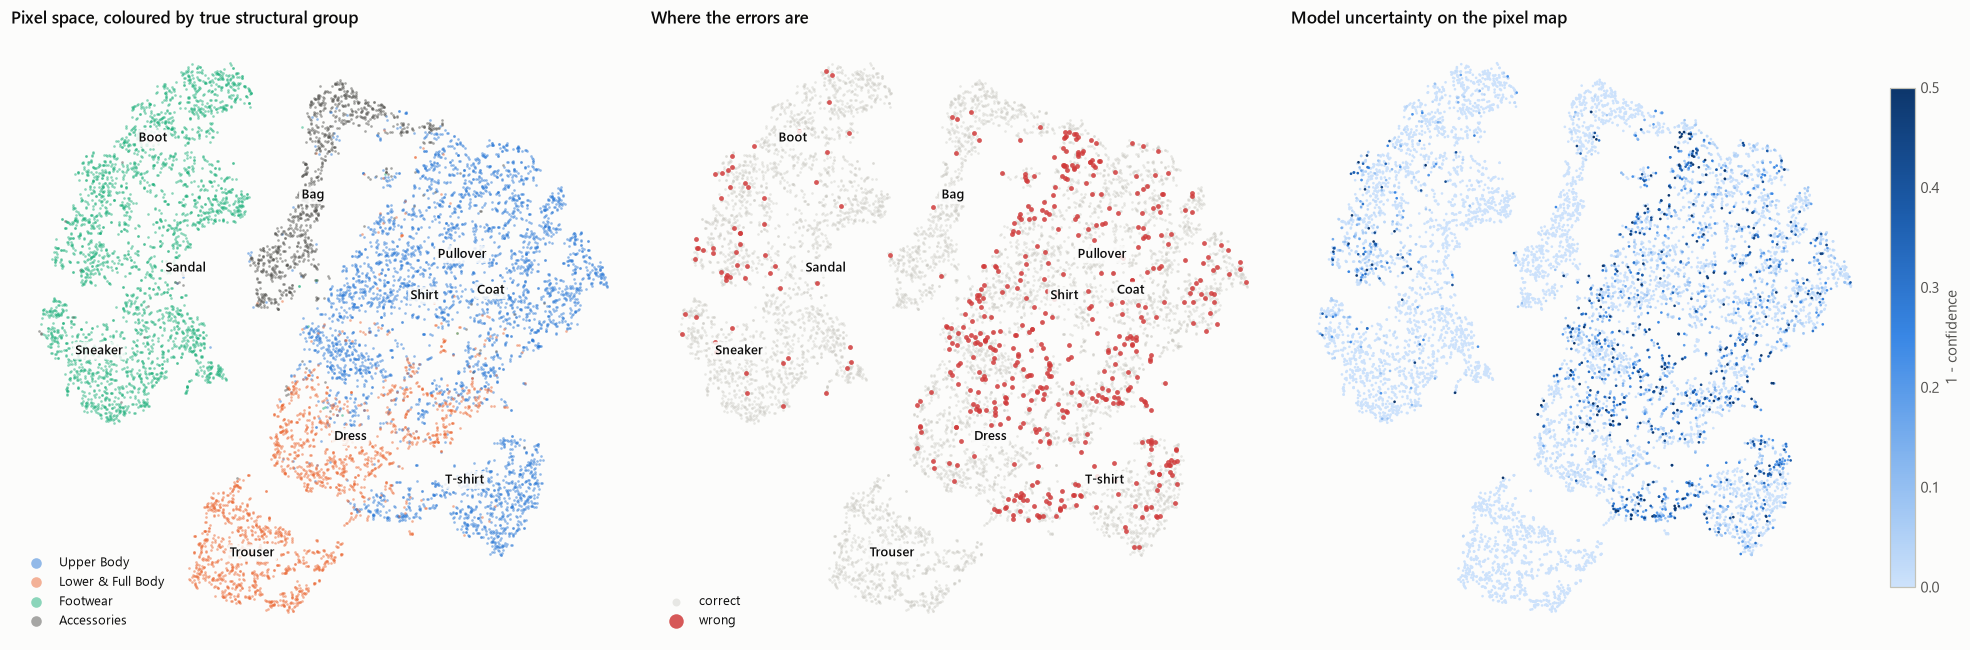

> **V12 · takeaway:** In raw pixel space, upper-body garments have a mean neighbourhood purity of 58.8% (share of the 15 nearest images with the same label), against 86.1% for everything else. The upper-body region produces 77.7% of all errors: the model fails where the classes already overlap in pixel space.

In [21]:
pca = PCA(n_components=50, random_state=SEED).fit(X_train.reshape(len(X_train), -1))
Z_train = pca.transform(X_train.reshape(len(X_train), -1)).astype(np.float32)
Z_test = pca.transform(X_test.reshape(len(X_test), -1)).astype(np.float32)
print(f'PCA-50 keeps {pca.explained_variance_ratio_.sum():.1%} of the pixel variance')
t0 = time.time()
EMB_PIX = embed_2d(Z_test)
print(f'pixel-space projection: {time.time() - t0:.0f}s')

nn_test = NearestNeighbors(n_neighbors=16).fit(Z_test)
_, ind_t = nn_test.kneighbors(Z_test)
purity = (y_test[ind_t[:, 1:]] == y_test[:, None]).mean(1)       # share of 15 pixel-neighbours with the same label

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
ax = axes[0]
for g, idxs in STRUCTURAL_GROUPS.items():
    m = np.isin(y_test, idxs)
    ax.scatter(*EMB_PIX[m].T, s=3, color=GROUP_COLORS[g], alpha=0.5, lw=0, label=g)
label_clusters(ax, EMB_PIX, y_test)
ax.legend(loc='lower left', markerscale=4)
ax.set_title('Pixel space, coloured by true structural group')
ax = axes[1]
ax.scatter(*EMB_PIX[correct].T, s=3, color=C_CONTEXT, alpha=0.4, lw=0, label='correct')
ax.scatter(*EMB_PIX[~correct].T, s=10, color=C_ERR, alpha=0.85, lw=0, label='wrong')
label_clusters(ax, EMB_PIX, y_test)
ax.legend(loc='lower left', markerscale=3)
ax.set_title('Where the errors are')
ax = axes[2]
o = np.argsort(-conf)
sc = ax.scatter(*EMB_PIX[o].T, c=1 - conf[o], cmap=BLUES_MARK, s=3, lw=0, vmin=0, vmax=0.5)
fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02, label='1 - confidence')
ax.set_title('Model uncertainty on the pixel map')
for ax in axes:
    embed_axes(ax)
plt.tight_layout()
plt.show()

ub = np.isin(y_test, STRUCTURAL_GROUPS['Upper Body'])
takeaway('V12', f"In raw pixel space, upper-body garments have a mean neighbourhood purity of {pct(purity[ub].mean())} (share of the 15 nearest "
                f"images with the same label), against {pct(purity[~ub].mean())} for everything else. The upper-body region produces "
                f"{pct(ub[~correct].mean())} of all errors: the model fails where the classes already overlap in pixel space.")

### V13 · Image map: what the regions look like

**Question:** What kinds of garments sit where on the pixel map, and what do the errors look like?
**How to read it:** the V12 map is cut into a grid, and each cell shows the image closest to its centre. Left: all images, with a red frame where that image is misclassified. Right: only the errors, on the same coordinates.

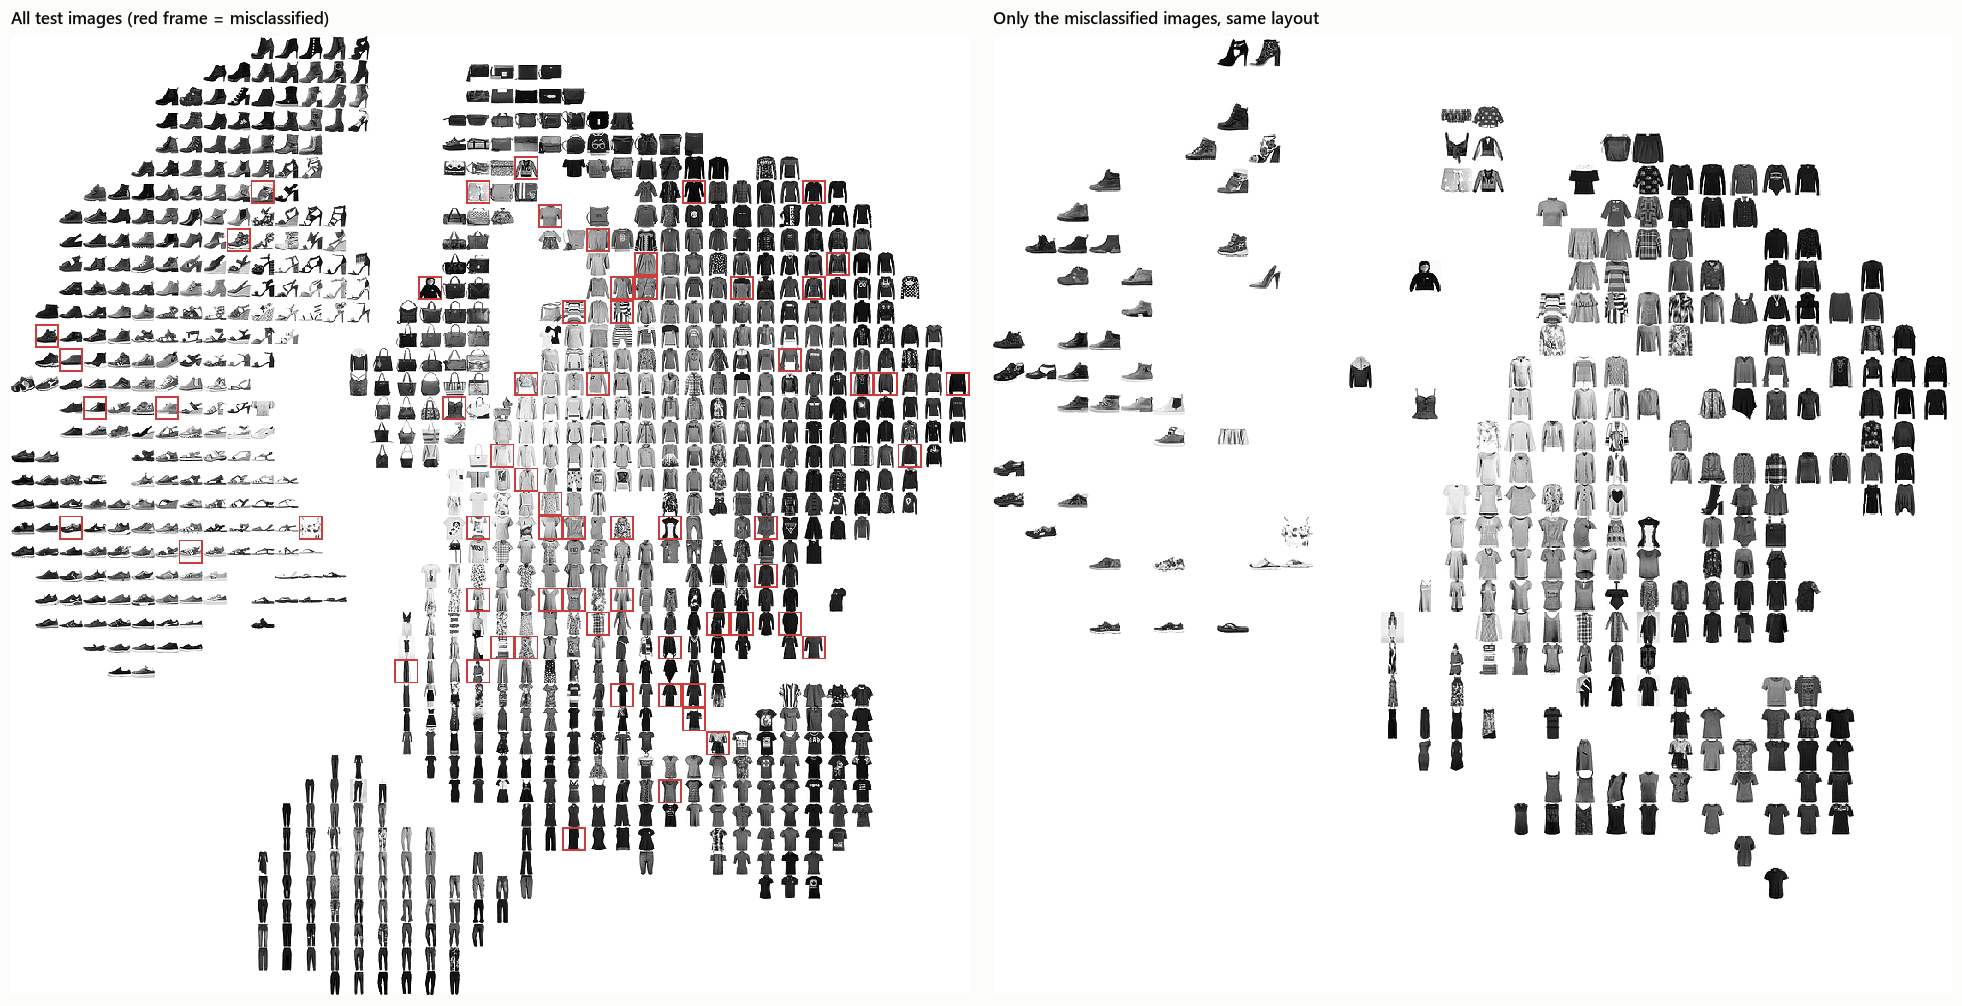

In [22]:
ERR_RGB = mpl.colors.to_rgb(C_ERR)
_lo, _hi = EMB_PIX.min(0), EMB_PIX.max(0)


def thumb_canvas(pool, G, frame_errors=True):
    u = (EMB_PIX[pool] - _lo) / (_hi - _lo + 1e-9)
    gx = np.minimum((u[:, 0] * G).astype(int), G - 1)
    gy = np.minimum((u[:, 1] * G).astype(int), G - 1)
    d = (u[:, 0] - (gx + 0.5) / G) ** 2 + (u[:, 1] - (gy + 0.5) / G) ** 2
    best = {}
    for k in np.argsort(d):
        best.setdefault((gx[k], gy[k]), pool[k])
    canvas = np.ones((G * 28, G * 28, 3))
    for (cx, cy), i in best.items():
        rgb = np.repeat((1 - X_test[i])[:, :, None], 3, axis=2)
        if frame_errors and not correct[i]:
            rgb[:2, :] = rgb[-2:, :] = rgb[:, :2] = rgb[:, -2:] = ERR_RGB
        r0, c0 = (G - 1 - cy) * 28, cx * 28
        canvas[r0:r0 + 28, c0:c0 + 28] = rgb
    return canvas


fig, axes = plt.subplots(1, 2, figsize=(18, 9))
axes[0].imshow(thumb_canvas(np.arange(len(X_test)), 40))
axes[0].set_title('All test images (red frame = misclassified)')
axes[1].imshow(thumb_canvas(np.where(~correct)[0], 30, frame_errors=False))
axes[1].set_title('Only the misclassified images, same layout')
for ax in axes:
    embed_axes(ax)
plt.tight_layout()
plt.show()

### V14 · Error hotspots

**Question:** Are the errors spread out or concentrated in a few places?
**How to read it:** (a) local error rate on the pixel map (hexagons with at least 6 images; darker = more errors). The map is split into regions with k-means, and the four regions with the highest error rate are marked H1-H4. (b) Concentration curve: regions sorted by error rate, x = cumulative share of images, y = cumulative share of errors. The further the curve is above the diagonal, the more concentrated the errors.

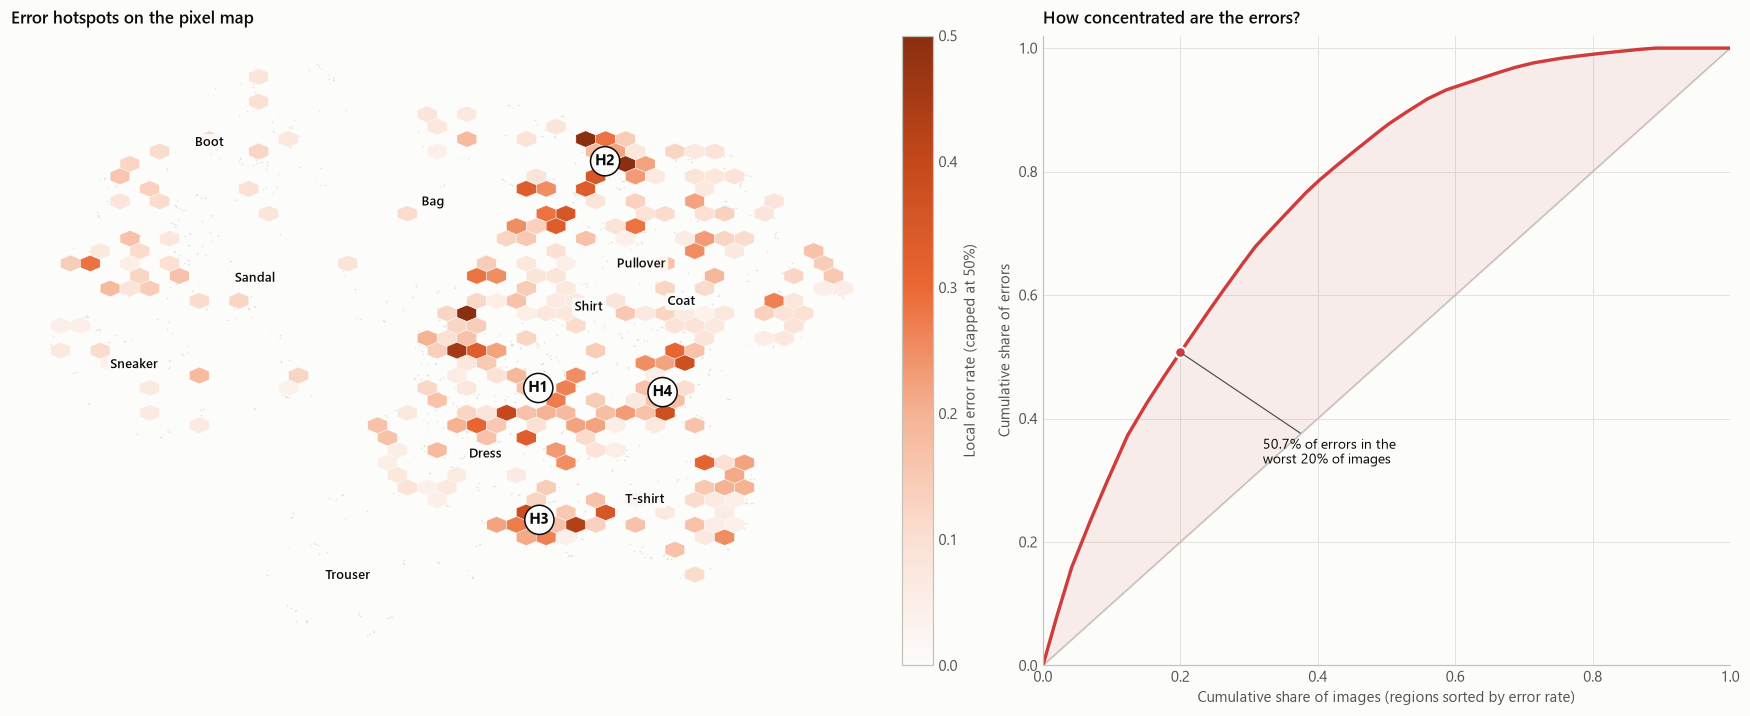

> **V14 · takeaway:** The four hotspots H1-H4 hold 9.4% of the test images but 30.0% of all errors. The worst 20% of the map (by region) holds 50.7% of the errors.

In [23]:
N_REGIONS = 20 if FAST_MODE else 40
km = KMeans(n_clusters=N_REGIONS, n_init=10, random_state=SEED).fit(EMB_PIX)
REGION = km.labels_
reg = (pd.DataFrame({'region': REGION, 'wrong': ~correct}).groupby('region')
       .agg(n=('wrong', 'size'), err_rate=('wrong', 'mean'), n_err=('wrong', 'sum')))
HOT = reg[reg['n'] >= 40].sort_values('err_rate', ascending=False).head(4)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.6), gridspec_kw={'width_ratios': [1.35, 1]})
ax = axes[0]
ax.scatter(*EMB_PIX.T, s=1, color=GRID, lw=0)
hb = ax.hexbin(EMB_PIX[:, 0], EMB_PIX[:, 1], C=(~correct).astype(float), reduce_C_function=np.mean, gridsize=40,
               mincnt=6, cmap=ORANGES, vmin=0, vmax=0.5, linewidths=0.3, edgecolors=SURFACE)
fig.colorbar(hb, ax=ax, fraction=0.04, pad=0.02, label='Local error rate (capped at 50%)')
for k, (rid, row) in enumerate(HOT.iterrows()):
    cx, cy = km.cluster_centers_[rid]
    ax.text(cx, cy, f'H{k + 1}', ha='center', va='center', fontsize=10, fontweight='bold', color=INK,
            bbox=dict(boxstyle='circle,pad=0.3', fc=SURFACE, ec=INK, lw=1))
label_clusters(ax, EMB_PIX, y_test)
embed_axes(ax)
ax.set_title('Error hotspots on the pixel map')

ax = axes[1]
r_sorted = reg.sort_values('err_rate', ascending=False)
x_cum = np.r_[0, np.cumsum(r_sorted['n']) / r_sorted['n'].sum()]
y_cum = np.r_[0, np.cumsum(r_sorted['n_err']) / r_sorted['n_err'].sum()]
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
ax.plot(x_cum, y_cum, color=C_ERR, lw=2.2)
ax.fill_between(x_cum, x_cum, y_cum, color=C_ERR, alpha=0.08)
share20 = np.interp(0.2, x_cum, y_cum)
ax.scatter([0.2], [share20], color=C_ERR, s=50, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.annotate(f'{pct(share20)} of errors in the\nworst 20% of images', (0.2, share20), xytext=(0.32, share20 - 0.18),
            fontsize=9, color=INK, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_xlabel('Cumulative share of images (regions sorted by error rate)')
ax.set_ylabel('Cumulative share of errors')
ax.set_title('How concentrated are the errors?')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

hot_items = np.isin(REGION, HOT.index)
takeaway('V14', f"The four hotspots H1-H4 hold {pct(hot_items.mean())} of the test images but {pct(hot_items[~correct].mean())} of all errors. "
                f"The worst 20% of the map (by region) holds {pct(share20)} of the errors.")

### V15 · Hotspot drill-down: what distinguishes each hotspot?

**Question:** Lab 02 asks us not to stop at "this cluster has many errors". What is inside each hotspot, and how does it differ from the rest of its class?
**How to read it:** per hotspot: the mean image, 8 sample images (red title = misclassified, *true → predicted*), and the class composition (blue = correct, red = wrong). The takeaway compares the hotspot's dominant class with the same class outside the hotspot on the interpretable attributes (z = difference in standard deviations).

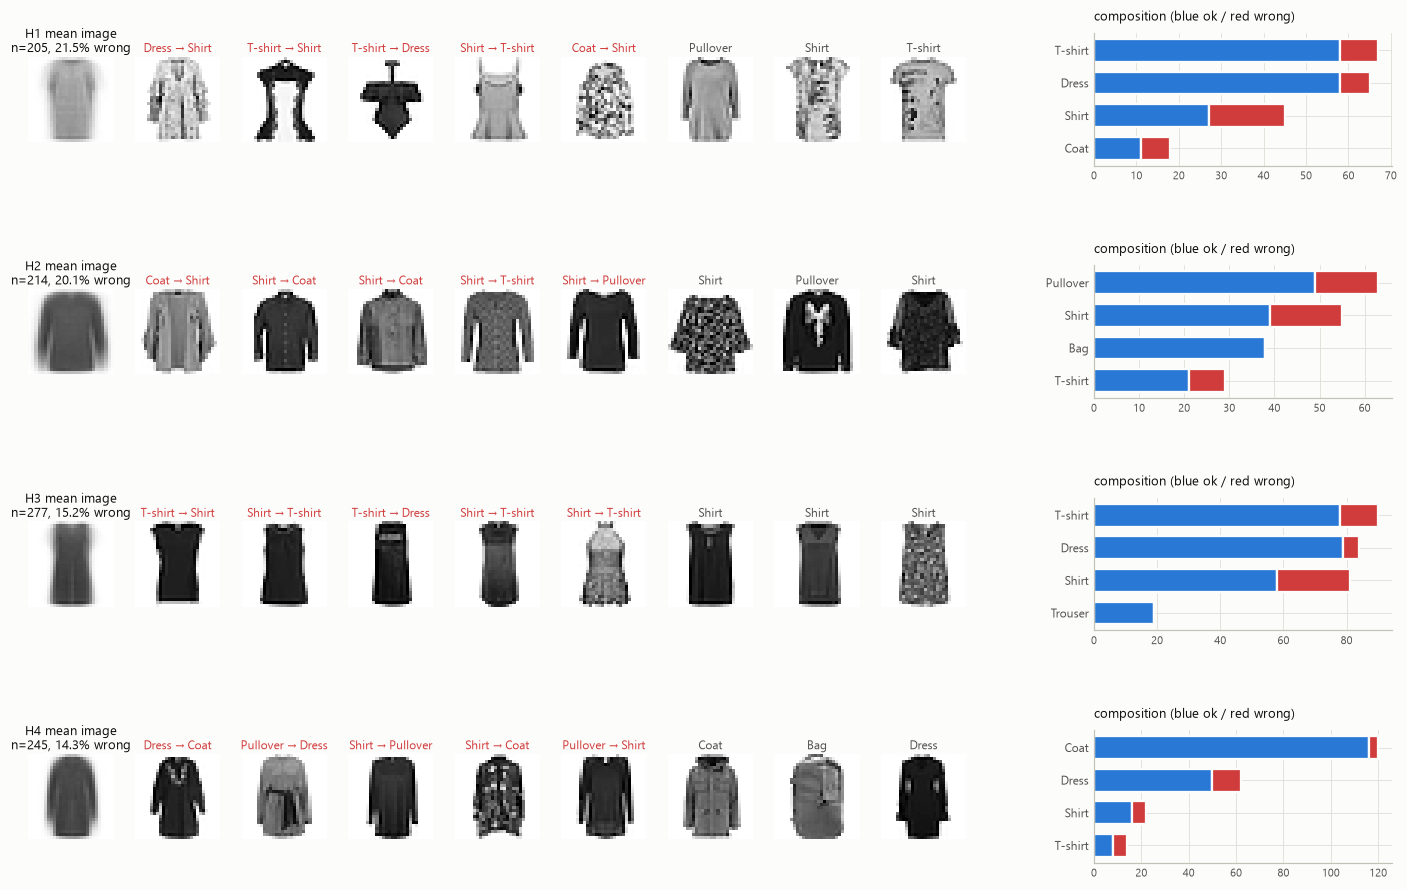

> **V15 · takeaway:** **H1** (205 images, 21.5% wrong): mostly T-shirt (32.7%), main error Shirt→T-shirt (11×). Its T-shirts differ from other T-shirts by lower ink intensity (z=-0.8) and lower l-r symmetry (z=-0.5) · **H2** (214 images, 20.1% wrong): mostly Pullover (29.4%), main error Pullover→Shirt (7×). Its Pullovers differ from other Pullovers by higher width (z=+1.8) and higher ink area (z=+1.8) · **H3** (277 images, 15.2% wrong): mostly T-shirt (32.5%), main error Shirt→T-shirt (18×). Its T-shirts differ from other T-shirts by lower width (z=-1.7) and lower aspect (w/h) (z=-1.5) · **H4** (245 images, 14.3% wrong): mostly Coat (49.0%), main error Dress→Coat (6×). Its Coats differ from other Coats by lower width (z=-1.0) and lower aspect (w/h) (z=-1.0)

In [24]:
rng = np.random.default_rng(SEED)
fig = plt.figure(figsize=(16, 2.45 * len(HOT)))
gs = fig.add_gridspec(len(HOT), 13, wspace=0.25, hspace=0.75)   # column 9 is a spacer before the bar chart
hot_lines = []
for r, (rid, row) in enumerate(HOT.iterrows()):
    members = np.where(REGION == rid)[0]
    errs, oks = members[~correct[members]], members[correct[members]]
    n_e = min(5, len(errs))
    pick = list(rng.choice(errs, n_e, replace=False)) + list(rng.choice(oks, min(8 - n_e, len(oks)), replace=False))
    show_img(fig.add_subplot(gs[r, 0]), X_test[members].mean(0), f'H{r + 1} mean image\nn={len(members)}, {pct(row.err_rate)} wrong', fs=8.5)
    for k, i in enumerate(pick[:8]):
        ok = correct[i]
        show_img(fig.add_subplot(gs[r, 1 + k]), X_test[i], SHORT[y_test[i]] if ok else f'{SHORT[y_test[i]]} → {SHORT[preds[i]]}',
                 color=INK2 if ok else C_ERR)
    ax = fig.add_subplot(gs[r, 10:13])
    comp = pd.DataFrame({'cls': y_test[members], 'ok': correct[members]}).groupby('cls')['ok'].agg(['sum', 'size'])
    comp = comp.sort_values('size', ascending=True).tail(4)
    yy = np.arange(len(comp))
    ax.barh(yy, comp['sum'], color=C_OK, edgecolor=SURFACE, linewidth=1.5, height=0.7)
    ax.barh(yy, comp['size'] - comp['sum'], left=comp['sum'], color=C_ERR, edgecolor=SURFACE, linewidth=1.5, height=0.7)
    ax.set_yticks(yy, [SHORT[c] for c in comp.index], fontsize=8)
    ax.tick_params(axis='x', labelsize=7.5)
    ax.set_title('composition (blue ok / red wrong)', fontsize=8.5, fontweight='normal')
    dom = int(np.bincount(y_test[members], minlength=10).argmax())
    inside = members[y_test[members] == dom]
    outside = np.setdiff1d(np.where(y_test == dom)[0], inside)
    z = {a: (attrs_test[a].to_numpy()[inside].mean() - attrs_test[a].to_numpy()[outside].mean())
            / (attrs_test[a].to_numpy()[y_test == dom].std() + 1e-9) for a in ATTRS}
    za = sorted(z.items(), key=lambda kv: -abs(kv[1]))[:2]
    err_pairs = pd.Series([f'{SHORT[t]}→{SHORT[p]}' for t, p in zip(y_test[errs], preds[errs])]).value_counts()
    main_err = f'{err_pairs.index[0]} ({err_pairs.iloc[0]}×)' if len(err_pairs) else 'none'
    hot_lines.append(f"**H{r + 1}** ({len(members)} images, {pct(row.err_rate)} wrong): mostly {SHORT[dom]} "
                     f"({pct(len(inside) / len(members))}), main error {main_err}. Its {SHORT[dom]}s differ from other {SHORT[dom]}s by "
                     + ' and '.join(f"{'higher' if v > 0 else 'lower'} {ATTR_LABELS[a].lower()} (z={v:+.1f})" for a, v in za))
plt.show()
takeaway('V15', ' · '.join(hot_lines))

### V16 · Sub-types of the hardest class

**Question:** Lab 02 asks whether hard clusters have sub-clusters. Is the hardest class uniformly hard, or are some *kinds* of it the problem?
**How to read it:** the hardest class (from V1) is split into 6 sub-types with k-means on its PCA pixel features. For each sub-type: the mean image, 8 examples, and the error rate with the main wrong destination.

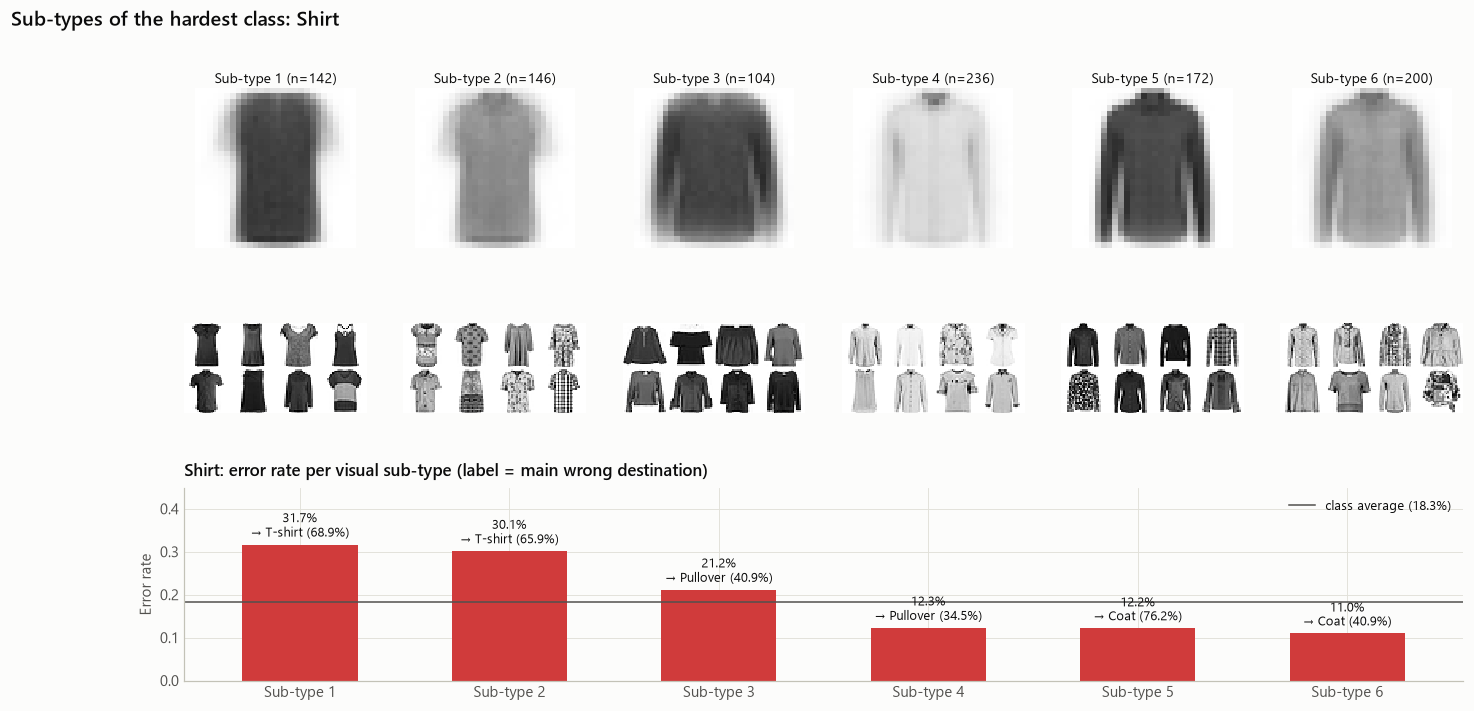

> **V16 · takeaway:** Shirt is not uniformly hard: sub-type 1 has an error rate of 31.7% (errors mostly → T-shirt), sub-type 6 only 11.0%. Compared with the easiest sub-type, the hardest one has higher ink intensity (z=+1.3), lower ink area (z=-0.9), higher l-r symmetry (z=+0.8).

In [25]:
WORST = int(ACC_ORDER[-1])
members_w = np.where(y_test == WORST)[0]
K_SUB = 6
sub = KMeans(n_clusters=K_SUB, n_init=10, random_state=SEED).fit_predict(Z_test[members_w])
sub_stats = []
for k in range(K_SUB):
    m = members_w[sub == k]
    e = m[~correct[m]]
    dest = pd.Series(preds[e]).value_counts()
    sub_stats.append({'n': len(m), 'err': (~correct[m]).mean(), 'members': m,
                      'dest': SHORT[dest.index[0]] if len(dest) else '-', 'dest_share': dest.iloc[0] / len(e) if len(e) else 0.0})
sub_stats = sorted(sub_stats, key=lambda s: -s['err'])

rng = np.random.default_rng(SEED)
fig = plt.figure(figsize=(15, 7.0))
gs = fig.add_gridspec(3, K_SUB, height_ratios=[1, 0.8, 1.2], hspace=0.35)
for col, s in enumerate(sub_stats):
    show_img(fig.add_subplot(gs[0, col]), X_test[s['members']].mean(0), f"Sub-type {col + 1} (n={s['n']})", fs=9)
    ex = rng.choice(s['members'], min(8, len(s['members'])), replace=False)
    show_img(fig.add_subplot(gs[1, col]), montage(X_test[ex], ncols=4))
ax = fig.add_subplot(gs[2, :])
errs_sub = [s['err'] for s in sub_stats]
ax.bar(np.arange(K_SUB), errs_sub, color=C_ERR, width=0.55)
for k, s in enumerate(sub_stats):
    ax.text(k, s['err'] + 0.01, f"{pct(s['err'])}\n→ {s['dest']} ({pct(s['dest_share'])})", ha='center', va='bottom', fontsize=8.5)
ax.axhline((~correct[members_w]).mean(), color=INK2, lw=1, label=f'class average ({pct((~correct[members_w]).mean())})')
ax.legend(loc='upper right')
ax.set_xticks(np.arange(K_SUB), [f'Sub-type {k + 1}' for k in range(K_SUB)])
ax.set_ylabel('Error rate')
ax.set_ylim(0, max(errs_sub) * 1.35 + 0.02)
ax.set_title(f'{CLASS_NAMES[WORST]}: error rate per visual sub-type (label = main wrong destination)')
fig.suptitle(f'Sub-types of the hardest class: {CLASS_NAMES[WORST]}', x=0.02, ha='left')
plt.show()

w_s, b_s = sub_stats[0], sub_stats[-1]
zd = {a: (attrs_test[a].to_numpy()[w_s['members']].mean() - attrs_test[a].to_numpy()[b_s['members']].mean())
         / (attrs_test[a].to_numpy()[members_w].std() + 1e-9) for a in ATTRS}
zd = sorted(zd.items(), key=lambda kv: -abs(kv[1]))[:3]
takeaway('V16', f"{CLASS_NAMES[WORST]} is not uniformly hard: sub-type 1 has an error rate of {pct(w_s['err'])} (errors mostly → {w_s['dest']}), "
                f"sub-type {K_SUB} only {pct(b_s['err'])}. Compared with the easiest sub-type, the hardest one has "
                + ', '.join(f"{'higher' if v > 0 else 'lower'} {ATTR_LABELS[a].lower()} (z={v:+.1f})" for a, v in zd) + '.')
WORST_SUB = {'err': w_s['err'], 'dest': w_s['dest']}

---
## E · Which interpretable image properties go with errors?

### V17 · Effect sizes: how do misclassified images differ from correctly classified ones?

**Question:** Within each class, which attributes separate the wrong images from the correct ones?
**How to read it:** Cohen's d of (wrong − correct) per class and attribute. Red = misclassified images have **higher** values, blue = **lower**. |d| ≥ 0.5 is a medium effect, ≥ 0.8 a large one. Classes with fewer than 15 errors are left empty (too few to say anything).

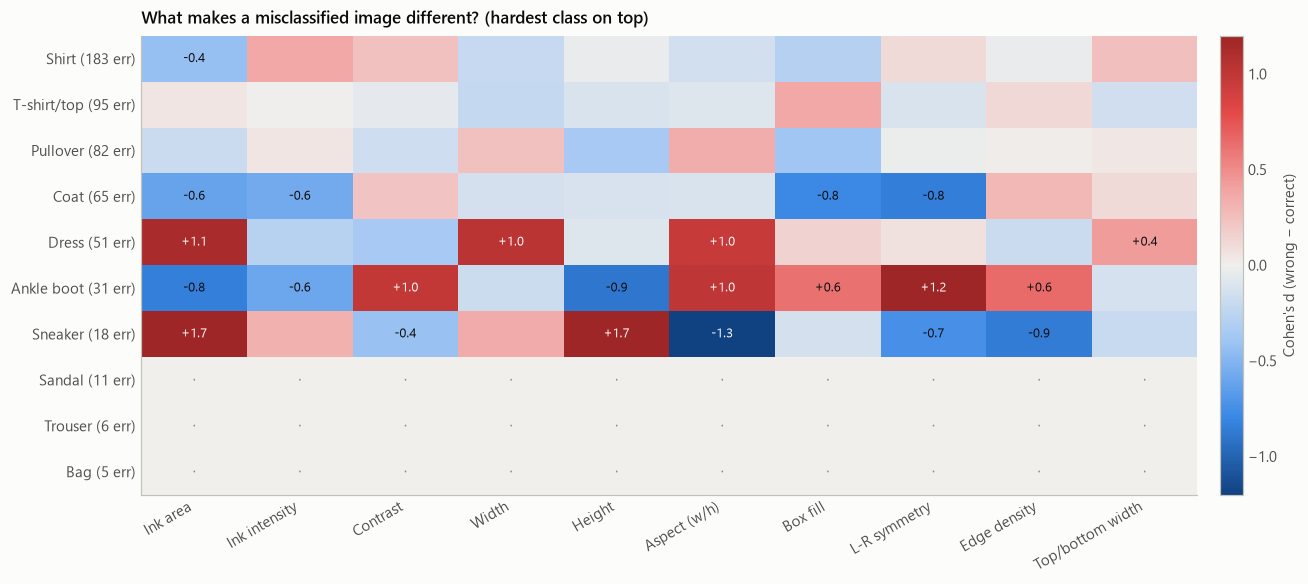

> **V17 · takeaway:** The strongest differences: misclassified Sneakers have higher height (d=+1.70); misclassified Sneakers have higher ink area (d=+1.68); misclassified Sneakers have lower aspect (w/h) (d=-1.34); misclassified Boots have higher l-r symmetry (d=+1.24). These are concrete, testable hypotheses for Phase II.

In [26]:
dmat = np.full((10, len(ATTRS)), np.nan)
for c in range(10):
    w, r_ = (y_test == c) & ~correct, (y_test == c) & correct
    if w.sum() < 15:
        continue
    for j, a in enumerate(ATTRS):
        v = attrs_test[a].to_numpy()
        sp = np.sqrt(((w.sum() - 1) * v[w].var(ddof=1) + (r_.sum() - 1) * v[r_].var(ddof=1)) / (w.sum() + r_.sum() - 2))
        dmat[c, j] = (v[w].mean() - v[r_].mean()) / (sp + 1e-12)

rows = ACC_ORDER[::-1]
Dm = dmat[rows]
fig, ax = plt.subplots(figsize=(12, 5.4))
cmap = DIVERGING.copy()
cmap.set_bad(NEUTRAL)
im = ax.imshow(np.ma.masked_invalid(Dm), cmap=cmap, norm=TwoSlopeNorm(vcenter=0, vmin=-1.2, vmax=1.2), aspect='auto')
for r in range(Dm.shape[0]):
    for j in range(Dm.shape[1]):
        if np.isnan(Dm[r, j]):
            ax.text(j, r, '·', ha='center', va='center', color=MUTED)
        elif abs(Dm[r, j]) >= 0.4:
            ax.text(j, r, f'{Dm[r, j]:+.1f}', ha='center', va='center', fontsize=8.5, color='white' if abs(Dm[r, j]) > 0.9 else INK)
ax.set_xticks(np.arange(len(ATTRS)), [ATTR_LABELS[a] for a in ATTRS], rotation=30, ha='right')
ax.set_yticks(np.arange(10), [f"{CLASS_NAMES[c]} ({cls.loc[c, 'n_err']} err)" for c in rows])
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="Cohen's d (wrong − correct)")
ax.set_title("What makes a misclassified image different? (hardest class on top)")
plt.tight_layout()
plt.show()

flat = [(abs(dmat[c, j]), c, j) for c in range(10) for j in range(len(ATTRS)) if not np.isnan(dmat[c, j])]
flat.sort(reverse=True)
takeaway('V17', 'The strongest differences: ' + '; '.join(
    f"misclassified {SHORT[c]}s have {'higher' if dmat[c, j] > 0 else 'lower'} {ATTR_LABELS[ATTRS[j]].lower()} (d={dmat[c, j]:+.2f})"
    for _, c, j in flat[:4]) + '. These are concrete, testable hypotheses for Phase II.')

### V18 · Error rate along each attribute

**Question:** Does the error rate rise steadily with an attribute, or only at the extremes?
**How to read it:** each panel splits all test images into deciles of one attribute (1 = lowest 10%, 10 = highest) and shows the error rate per decile, separately for each structural group (black = all). Deciles with fewer than 20 images of a group are left out.

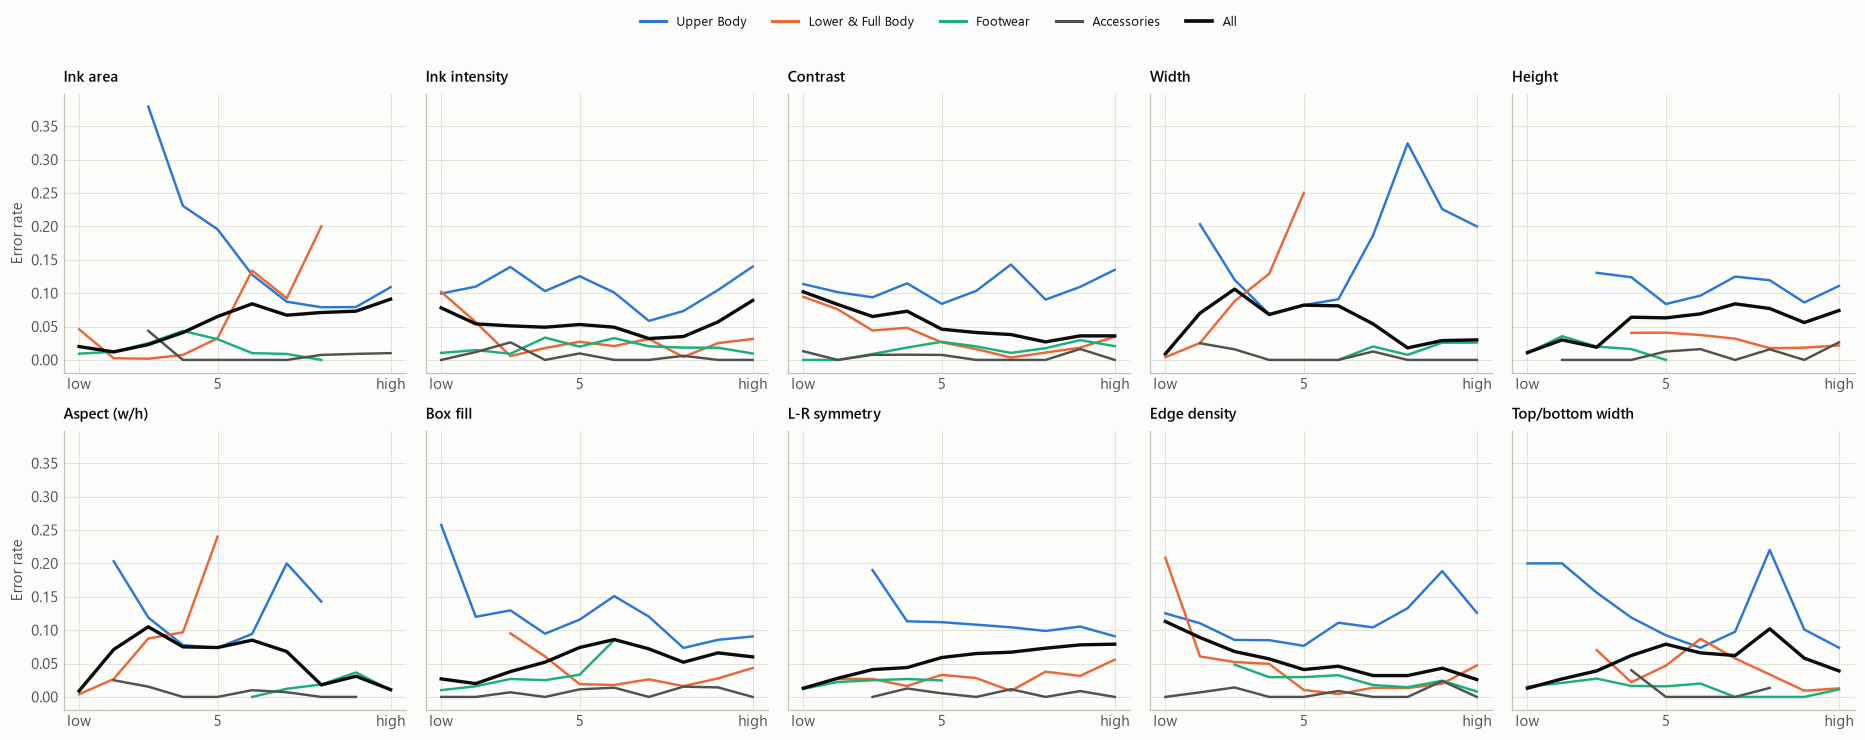

> **V18 · takeaway:** For upper-body garments the error rate depends most on **ink area**: it varies by 30.0 percentage points across deciles and peaks in decile 3 (low values).

In [27]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.6), sharey=True)
def deciles(v):
    """Rank-based deciles 0..9 (ties are split, so every decile holds 10% of the images)."""
    return np.argsort(np.argsort(v, kind='stable'), kind='stable') * 10 // len(v)


spread = {}
for ax, a in zip(axes.flat, ATTRS):
    v = attrs_test[a].to_numpy()
    dec = deciles(v)
    for g, idxs in STRUCTURAL_GROUPS.items():
        m = np.isin(y_test, idxs)
        er = [(~correct[m & (dec == d)]).mean() if (m & (dec == d)).sum() >= 20 else np.nan for d in range(10)]
        ax.plot(np.arange(1, 11), er, color=GROUP_COLORS[g], lw=1.6)
        if g == 'Upper Body':
            spread[a] = (np.nanmax(er) - np.nanmin(er), int(np.nanargmax(er)) + 1)
    er_all = [(~correct[dec == d]).mean() if (dec == d).sum() >= 20 else np.nan for d in range(10)]
    ax.plot(np.arange(1, 11), er_all, color=INK, lw=2.2)
    ax.set_title(ATTR_LABELS[a], fontsize=10)
    ax.set_xticks([1, 5, 10], ['low', '5', 'high'])
for ax in axes[:, 0]:
    ax.set_ylabel('Error rate')
handles = [Line2D([], [], color=col, lw=2, label=g) for g, col in GROUP_COLORS.items()] + [Line2D([], [], color=INK, lw=2.4, label='All')]
fig.legend(handles=handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

best_a = max(spread, key=lambda a: spread[a][0])
takeaway('V18', f"For upper-body garments the error rate depends most on **{ATTR_LABELS[best_a].lower()}**: it varies by "
                f"{spread[best_a][0] * 100:.1f} percentage points across deciles and peaks in decile {spread[best_a][1]} "
                f"({'high' if spread[best_a][1] > 5 else 'low'} values).")

### V19 · Confidence × attribute, per upper-body class

**Question:** This is the penguin-style scatter from Lab 02, applied to our data. For each upper-body class, how do confidence and the most telling attribute (largest |d| in V17) jointly separate the errors?
**How to read it:** one panel per true class. x = confidence, y = attribute. Grey = correct. Coloured = wrong, by the class it was confused with (top 3, the rest dark grey).

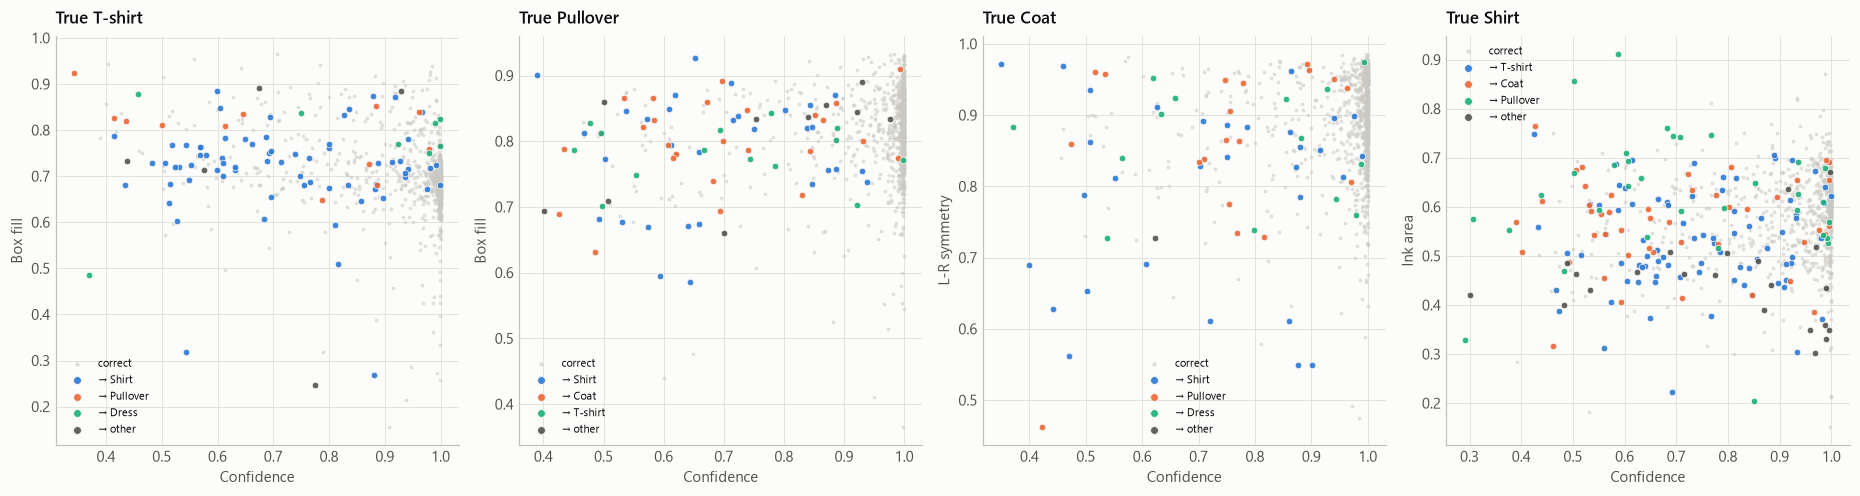

> **V19 · takeaway:** T-shirt: median box fill 0.73 when wrong vs. 0.69 when right; Pullover: median box fill 0.80 when wrong vs. 0.83 when right; Coat: median l-r symmetry 0.86 when wrong vs. 0.90 when right; Shirt: median ink area 0.54 when wrong vs. 0.60 when right.

In [28]:
facets = STRUCTURAL_GROUPS['Upper Body']
fig, axes = plt.subplots(1, len(facets), figsize=(17, 4.6))
facet_notes = []
for ax, c in zip(axes, facets):
    row = dmat[c]
    a = ATTRS[int(np.nanargmax(np.abs(row)))] if np.isfinite(row).any() else 'contrast'
    v = attrs_test[a].to_numpy()
    m = y_test == c
    ok, wrong = m & correct, m & ~correct
    ax.scatter(conf[ok], v[ok], s=6, color=C_CONTEXT, alpha=0.55, lw=0, label='correct')
    dests = pd.Series(preds[wrong]).value_counts().index[:3]
    for k, dc in enumerate(dests):
        mm = wrong & (preds == dc)
        ax.scatter(conf[mm], v[mm], s=18, color=SERIES[k], alpha=0.9, lw=0.5, edgecolor=SURFACE, label=f'→ {SHORT[dc]}')
    other = wrong & ~np.isin(preds, dests)
    if other.any():
        ax.scatter(conf[other], v[other], s=18, color=INK2, alpha=0.9, lw=0.5, edgecolor=SURFACE, label='→ other')
    ax.set_title(f'True {SHORT[c]}')
    ax.set_xlabel('Confidence')
    ax.set_ylabel(ATTR_LABELS[a])
    ax.legend(loc='best', fontsize=7.5, markerscale=1.2)
    facet_notes.append(f"{SHORT[c]}: median {ATTR_LABELS[a].lower()} {np.median(v[wrong]):.2f} when wrong vs. {np.median(v[ok]):.2f} when right")
plt.tight_layout()
plt.show()
takeaway('V19', '; '.join(facet_notes) + '.')

### V20 · Mean-image anatomy of the top confusions

**Question:** What does an *average* error look like compared with the two classes involved?
**How to read it:** per row (one directed confusion A → B): the mean correct A, the mean A-image misclassified as B, the mean correct B, and the difference (errors − correct A). Red = the errors have **more** ink there, blue = **less**.

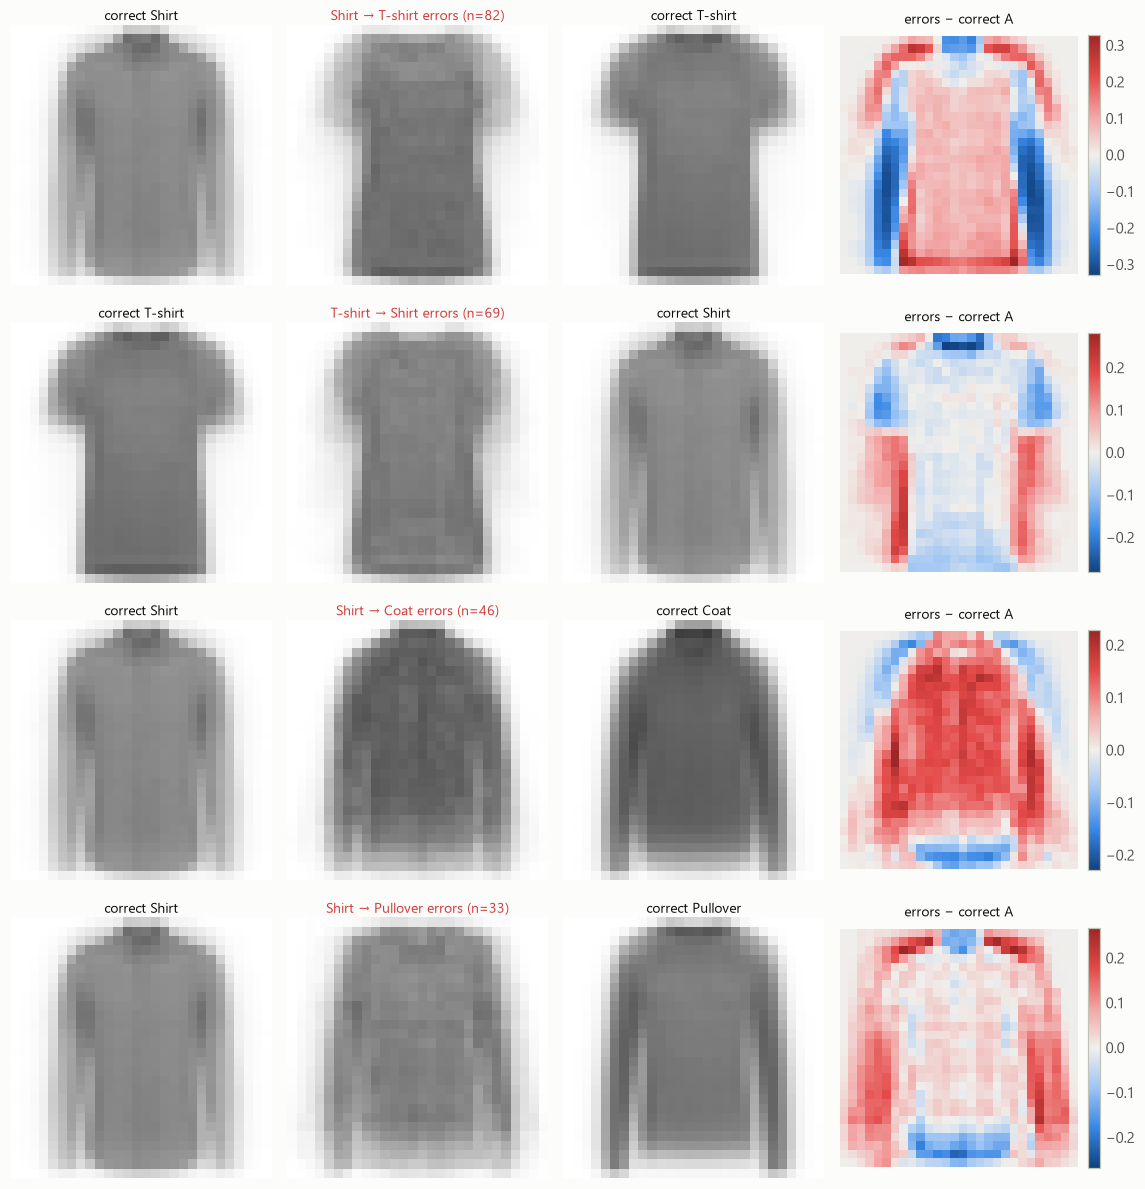

> **V20 · takeaway:** Shirt→T-shirt: more ink bottom-centre, less ink middle-left; the average error image correlates r=0.97 with an average T-shirt and r=0.89 with an average Shirt; T-shirt→Shirt: more ink bottom-left, less ink top-centre; the average error image correlates r=0.90 with an average Shirt and r=0.97 with an average T-shirt; Shirt→Coat: more ink middle-centre, less ink top-left; the average error image correlates r=0.99 with an average Coat and r=0.97 with an average Shirt; Shirt→Pullover: more ink middle-right, less ink bottom-centre; the average error image correlates r=0.98 with an average Pullover and r=0.95 with an average Shirt.

In [29]:
dir_pairs = sorted([(E[i, j], i, j) for i in range(10) for j in range(10) if i != j], reverse=True)[:4]
fig, axes = plt.subplots(len(dir_pairs), 4, figsize=(10.5, 2.75 * len(dir_pairs)))
anat = []
for r, (n, a, b) in enumerate(dir_pairs):
    ok_a = X_test[(y_test == a) & correct].mean(0)
    err_ab = X_test[(y_test == a) & (preds == b)].mean(0)
    ok_b = X_test[(y_test == b) & correct].mean(0)
    diff = err_ab - ok_a
    show_img(axes[r, 0], ok_a, f'correct {SHORT[a]}', fs=9)
    show_img(axes[r, 1], err_ab, f'{SHORT[a]} → {SHORT[b]} errors (n={n})', color=C_ERR, fs=9)
    show_img(axes[r, 2], ok_b, f'correct {SHORT[b]}', fs=9)
    lim = np.abs(diff).max()
    im = axes[r, 3].imshow(diff, cmap=DIVERGING, vmin=-lim, vmax=lim)
    embed_axes(axes[r, 3])
    axes[r, 3].set_title('errors − correct A', fontsize=9, loc='center', fontweight='normal')
    fig.colorbar(im, ax=axes[r, 3], fraction=0.046, pad=0.04)
    more, less = region_extremes(diff)
    r_a, r_b = np.corrcoef(err_ab.ravel(), ok_a.ravel())[0, 1], np.corrcoef(err_ab.ravel(), ok_b.ravel())[0, 1]
    anat.append(f"{SHORT[a]}→{SHORT[b]}: more ink {more}, less ink {less}; the average error image correlates "
                f"r={r_b:.2f} with an average {SHORT[b]} and r={r_a:.2f} with an average {SHORT[a]}")
plt.tight_layout()
plt.show()
takeaway('V20', '; '.join(anat) + '.')

---
## F · Training data as a source of hypotheses

The training images are used to build hypotheses, which are then checked against the model's outputs (as the assignment allows). Neighbours are searched in PCA-50 pixel space, so the model is not involved.

### V21 · Typicality: does the model fail on unusual images?

**Question:** Are errors more frequent on test images that look unlike anything in the training set?
**How to read it:** typicality = mean distance to the 5 nearest training images, with test images split into deciles (1 = most typical). (a) Error rate per decile. (b) Mean confidence per decile for correct and wrong predictions.

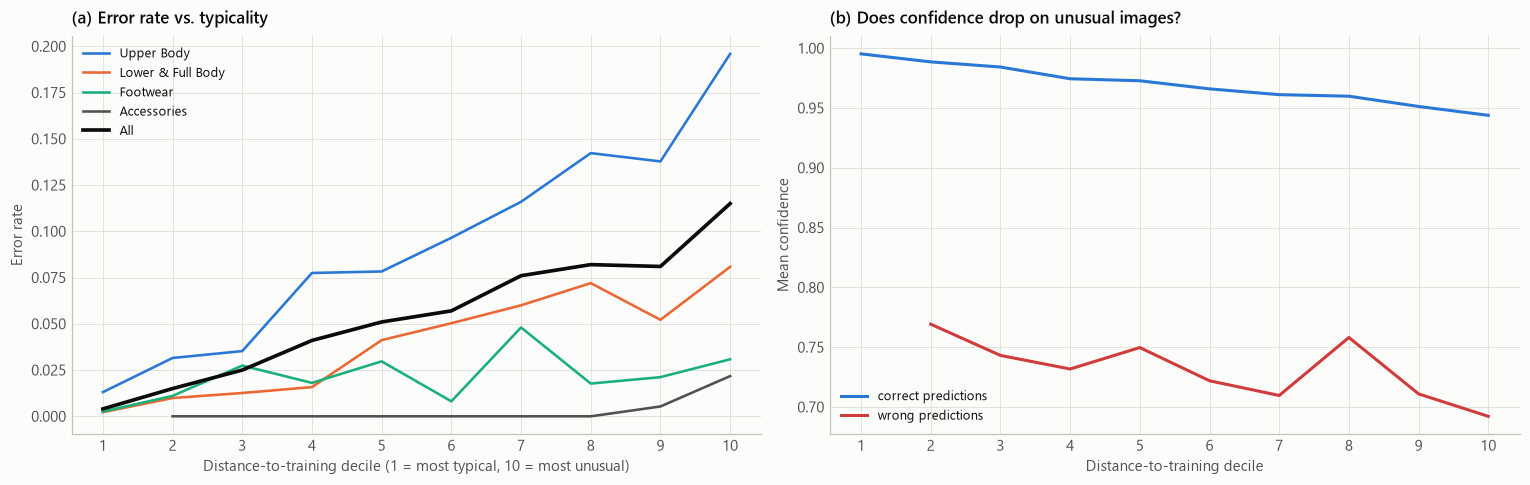

> **V21 · takeaway:** The most unusual 10% of test images have an error rate of 11.5%, against 0.4% for the most typical 10% (×28.8). The model's confidence on its wrong answers stays at 72.0% even for the most unusual images: it does not signal that it is out of its comfort zone. (Pixel distance also grows with ink amount, so read this together with V17.)

In [30]:
nn_tr = NearestNeighbors(n_neighbors=10, algorithm='brute', n_jobs=-1).fit(Z_train)
dist_tr, ind_tr = nn_tr.kneighbors(Z_test)
typ = dist_tr[:, :5].mean(1)
tdec = deciles(typ)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
for g, idxs in STRUCTURAL_GROUPS.items():
    m = np.isin(y_test, idxs)
    er = [(~correct[m & (tdec == d)]).mean() if (m & (tdec == d)).sum() >= 20 else np.nan for d in range(10)]
    ax.plot(np.arange(1, 11), er, color=GROUP_COLORS[g], lw=1.7, label=g)
er_all = np.array([(~correct[tdec == d]).mean() for d in range(10)])
ax.plot(np.arange(1, 11), er_all, color=INK, lw=2.4, label='All')
ax.set_xticks(range(1, 11))
ax.set_xlabel('Distance-to-training decile (1 = most typical, 10 = most unusual)')
ax.set_ylabel('Error rate')
ax.set_title('(a) Error rate vs. typicality')
ax.legend(loc='upper left')
ax = axes[1]
cf_ok = [conf[(tdec == d) & correct].mean() for d in range(10)]
cf_wr = [conf[(tdec == d) & ~correct].mean() if ((tdec == d) & ~correct).sum() >= 5 else np.nan for d in range(10)]
ax.plot(np.arange(1, 11), cf_ok, color=C_OK, lw=2, label='correct predictions')
ax.plot(np.arange(1, 11), cf_wr, color=C_ERR, lw=2, label='wrong predictions')
ax.set_xticks(range(1, 11))
ax.set_xlabel('Distance-to-training decile')
ax.set_ylabel('Mean confidence')
ax.set_title('(b) Does confidence drop on unusual images?')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

ratio = f'×{er_all[-1] / er_all[0]:.1f}' if er_all[0] > 0 else 'no errors at all among the most typical'
takeaway('V21', f"The most unusual 10% of test images have an error rate of {pct(er_all[-1])}, against {pct(er_all[0])} for the most typical 10% "
                f"({ratio}). The model's confidence on its wrong answers stays at "
                f"{pct(np.nanmean(cf_wr[-3:]))} even for the most unusual images: it does not signal that it is out of its comfort zone. "
                f"(Pixel distance also grows with ink amount, so read this together with V17.)")

### V22 · Do the training neighbours agree with the label?

**Question:** Some test images look more like *another* class in the training data. Does the model then follow the neighbours rather than the label?
**How to read it:** agreement = how many of the 10 nearest training images carry the same label as the test image. (a) Distribution of agreement for correct and wrong predictions. (b) Error rate per agreement level (n per bar below the axis).

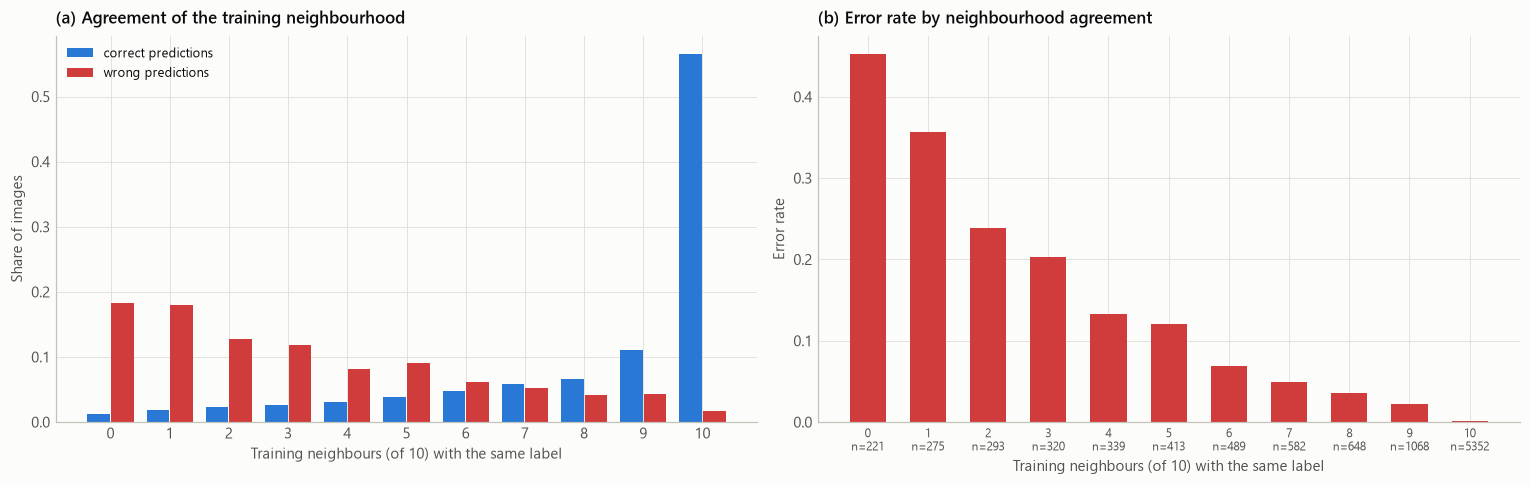

> **V22 · takeaway:** When at most 3 of 10 training neighbours share the label, the error rate is 30.0%; with 8 or more it is 0.8%. In 49.0% of all errors the model predicts exactly the **majority label of the training neighbours**: it behaves like a look-alike matcher, and many errors are images that resemble another class in the training data.

In [31]:
agree = (y_train[ind_tr] == y_test[:, None]).sum(1)
maj = np.array([np.bincount(row, minlength=10).argmax() for row in y_train[ind_tr]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
lv = np.arange(11)
h_ok = np.array([(agree[correct] == k).mean() for k in lv])
h_wr = np.array([(agree[~correct] == k).mean() for k in lv])
ax.bar(lv - 0.2, h_ok, width=0.38, color=C_OK, label='correct predictions')
ax.bar(lv + 0.2, h_wr, width=0.38, color=C_ERR, label='wrong predictions')
ax.set_xticks(lv)
ax.set_xlabel('Training neighbours (of 10) with the same label')
ax.set_ylabel('Share of images')
ax.set_title('(a) Agreement of the training neighbourhood')
ax.legend(loc='upper left')
ax = axes[1]
er_k = np.array([(~correct[agree == k]).mean() if (agree == k).any() else np.nan for k in lv])
n_k = np.array([(agree == k).sum() for k in lv])
ax.bar(lv, er_k, color=C_ERR, width=0.6)
ax.set_xticks(lv, [f'{k}\nn={n}' for k, n in zip(lv, n_k)], fontsize=8)
ax.set_xlabel('Training neighbours (of 10) with the same label')
ax.set_ylabel('Error rate')
ax.set_title('(b) Error rate by neighbourhood agreement')
plt.tight_layout()
plt.show()

low, high = agree <= 3, agree >= 8
follows = (maj[~correct] == preds[~correct]).mean()
takeaway('V22', f"When at most 3 of 10 training neighbours share the label, the error rate is {pct((~correct[low]).mean())}; with 8 or more it is "
                f"{pct((~correct[high]).mean())}. In {pct(follows)} of all errors the model predicts exactly the **majority label of the "
                f"training neighbours**: it behaves like a look-alike matcher, and many errors are images that resemble another class in the training data.")

### V23 · "Is the model wrong or the label?" Suspicious test images

**Question:** Some "errors" could be ambiguous images or mislabels. Which ones?
**How to read it:** each row is a confident error (≥ 90% when possible) whose training neighbourhood **agrees with the model, not with the label**. The first image is the test image (red title: label vs. model), followed by its 5 nearest training images with their labels. Inspect these by hand before counting them as model failures.

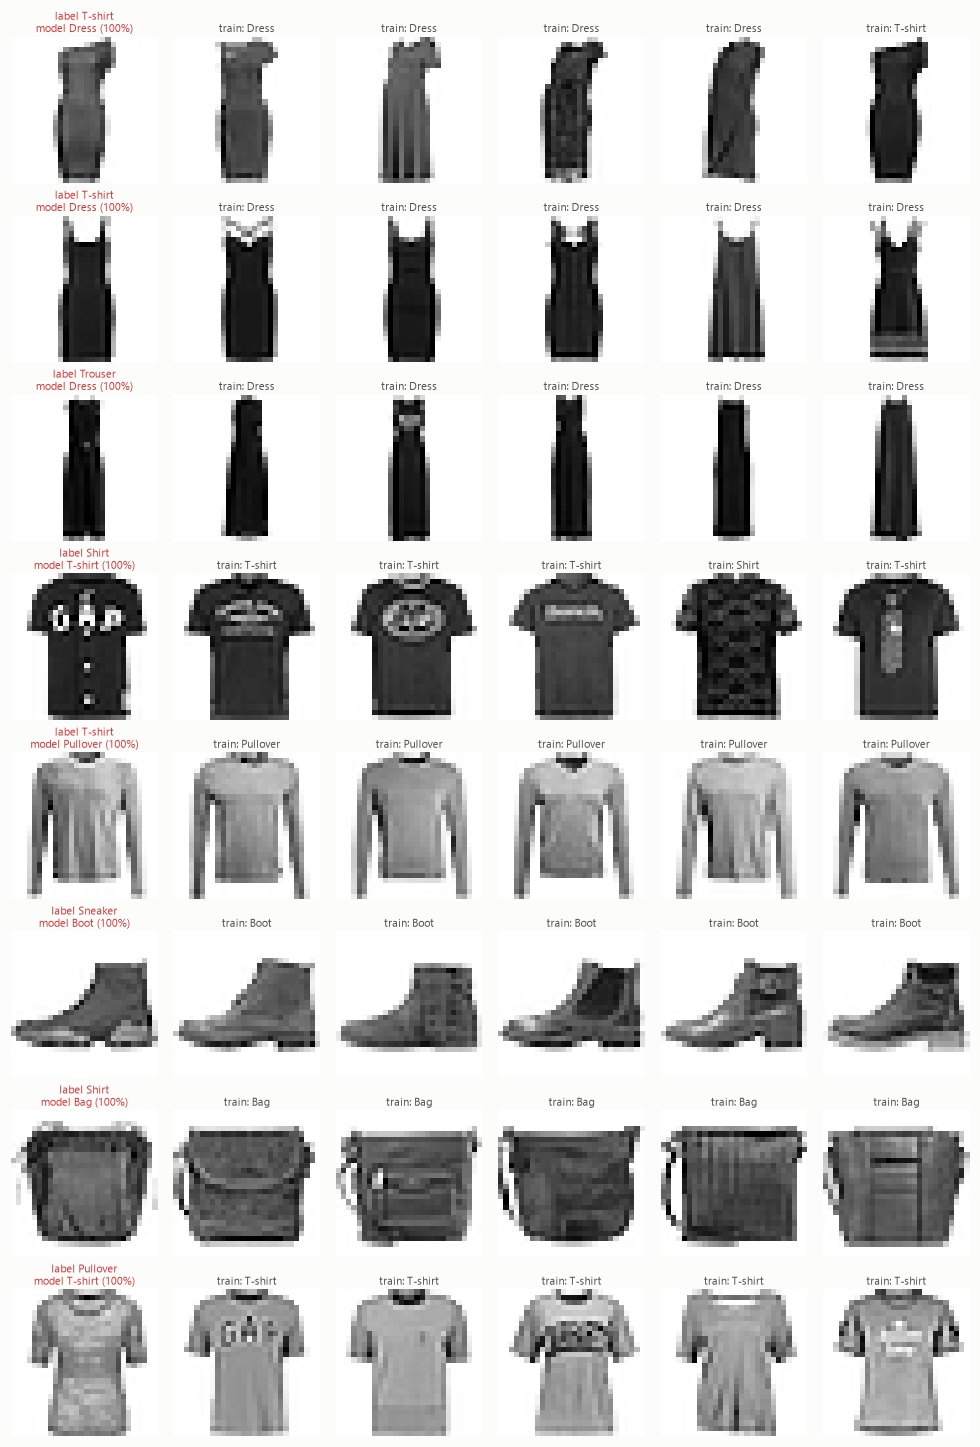

> **V23 · takeaway:** 175 errors (32.0% of all) are images whose training neighbourhood agrees with the model rather than with the label. They are candidates for ambiguous or mislabelled data. Excluding them would raise the accuracy to at most 96.3%.

In [32]:
cand = np.where(~correct & (conf >= 0.9) & (agree <= 2) & (maj == preds))[0]
if len(cand) < 8:
    cand = np.where(~correct & (agree <= 2) & (maj == preds))[0]
cand = cand[np.argsort(-conf[cand])][:8]
if len(cand) == 0:
    print('No suspicious items found.')
else:
    fig, axes = plt.subplots(len(cand), 6, figsize=(9, 1.65 * len(cand)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(cand):
        show_img(axes[r, 0], X_test[i], f'label {SHORT[y_test[i]]}\nmodel {SHORT[preds[i]]} ({conf[i]:.0%})', color=C_ERR, fs=7.5)
        for k in range(5):
            j = ind_tr[i, k]
            show_img(axes[r, 1 + k], X_train[j], f'train: {SHORT[y_train[j]]}', color=INK2, fs=7.5)
    plt.tight_layout()
    plt.show()
n_susp = int((~correct & (agree <= 2) & (maj == preds)).sum())
takeaway('V23', f"{n_susp} errors ({pct(n_susp / (~correct).sum())} of all) are images whose training neighbourhood agrees with the model "
                f"rather than with the label. They are candidates for ambiguous or mislabelled data. Excluding them would raise the accuracy to "
                f"at most {pct((correct.sum() + n_susp) / len(correct))}.")

---
## G · Synthetic inputs: perturbations, occlusion and morphing

The assignment allows synthetic datasets for edge cases and counterfactuals. All of them are fed through `predict_proba` only. A stratified sample of test images is used, the same for every perturbation.

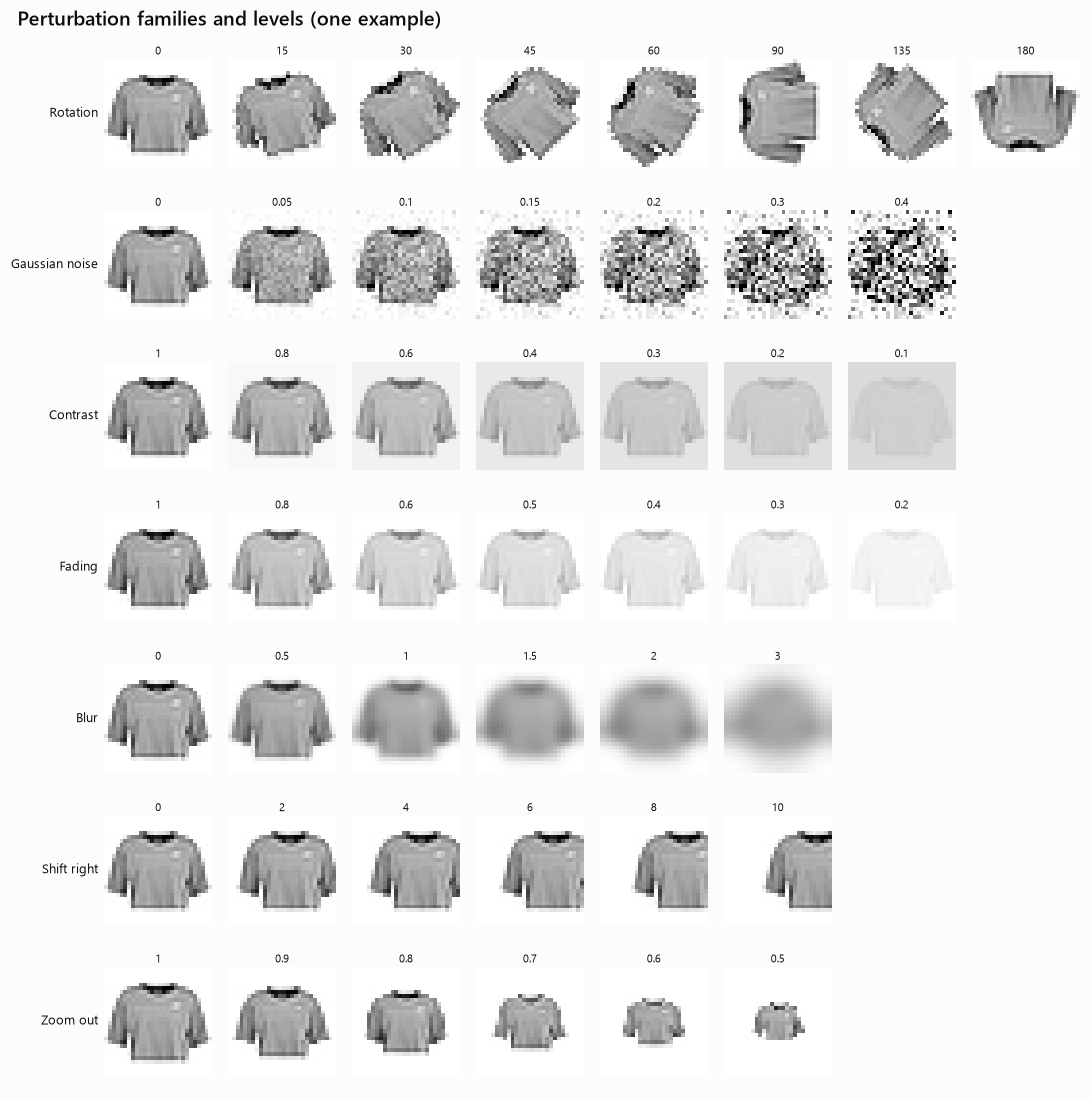

51 perturbed versions × 3000 images evaluated


In [33]:
rng = np.random.default_rng(SEED)
N_PER_CLASS = 100 if FAST_MODE else 300
pert_idx = np.concatenate([rng.choice(np.where(y_test == c)[0], N_PER_CLASS, replace=False) for c in range(10)])
X_p = torch.tensor(X_test[pert_idx], device=device).unsqueeze(1)
y_p = y_test[pert_idx]


def blur(x, s):
    if s == 0:
        return x
    k = 2 * math.ceil(3 * s) + 1
    return TF.gaussian_blur(x, kernel_size=[k, k], sigma=[s, s])


def shift_right(x, px):
    return x if px == 0 else F.pad(x, (px, 0, 0, 0))[..., :28]


def zoom_out(x, s):
    return TF.affine(x, angle=0.0, translate=[0, 0], scale=s, shear=[0.0, 0.0])


def add_noise(x, s):
    g = torch.Generator(device=x.device).manual_seed(SEED)
    return (x + torch.randn(x.shape, generator=g, device=x.device) * s).clamp(0, 1)


PERTURBATIONS = {
    'Rotation (deg)': ([0, 15, 30, 45, 60, 90, 135, 180], lambda x, v: TF.rotate(x, float(v))),
    'Gaussian noise (sigma)': ([0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4], add_noise),
    'Contrast (factor)': ([1, 0.8, 0.6, 0.4, 0.3, 0.2, 0.1], lambda x, v: TF.adjust_contrast(x, v)),
    'Fading (factor)': ([1, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2], lambda x, v: x * v),   # lower pixel values = paler garment
    'Blur (sigma)': ([0, 0.5, 1, 1.5, 2, 3], blur),
    'Shift right (px)': ([0, 2, 4, 6, 8, 10], shift_right),
    'Zoom out (scale)': ([1, 0.9, 0.8, 0.7, 0.6, 0.5], zoom_out),
}
BINARY_PERTURBATIONS = {'Horizontal flip': lambda x: x.flip(3), 'Vertical flip': lambda x: x.flip(2), 'Invert (1 − x)': lambda x: 1 - x}

pert_probs = {('Clean', 0): blackbox.predict_proba(X_p)}
for name, (levels, fn) in PERTURBATIONS.items():
    for lv in levels:
        pert_probs[(name, lv)] = blackbox.predict_proba(fn(X_p, lv))
for name, fn in BINARY_PERTURBATIONS.items():
    pert_probs[(name, 1)] = blackbox.predict_proba(fn(X_p))

pert_rows = []
for (name, lv), P in pert_probs.items():
    pr = P.argmax(1)
    row = {'perturbation': name, 'level': lv, 'acc': (pr == y_p).mean(), 'conf': P.max(1).mean()}
    for c in range(10):
        row[f'acc_{c}'] = (pr[y_p == c] == c).mean()
        row[f'share_{c}'] = (pr == c).mean()
    for g, idxs in STRUCTURAL_GROUPS.items():
        m = np.isin(y_p, idxs)
        row[f'acc_{g}'] = (pr[m] == y_p[m]).mean()
    pert_rows.append(row)
pert = pd.DataFrame(pert_rows)


def pert_value(name, lv, col):
    return pert.loc[(pert['perturbation'] == name) & (pert['level'] == lv), col].item()


# what the perturbations look like
demo = X_p[[0]]
fig, axes = plt.subplots(len(PERTURBATIONS), 8, figsize=(10, 1.45 * len(PERTURBATIONS)))
for r, (name, (levels, fn)) in enumerate(PERTURBATIONS.items()):
    for k in range(8):
        if k < len(levels):
            show_img(axes[r, k], fn(demo, levels[k])[0, 0].cpu().numpy(), f'{levels[k]}', fs=7.5)
        else:
            axes[r, k].axis('off')
    axes[r, 0].set_ylabel(name.split(' (')[0], rotation=0, ha='right', va='center', fontsize=8.5, color=INK)
fig.suptitle('Perturbation families and levels (one example)', x=0.02, ha='left')
plt.tight_layout()
plt.show()
print(f'{len(pert_probs)} perturbed versions × {len(pert_idx)} images evaluated')

### V24 · Robustness map: which class breaks under which perturbation?

**Question:** Which perturbations hurt which classes?
**How to read it:** (a) accuracy per class (rows, in the V2 order) for the clean images, the strongest level of each perturbation, and the three binary transforms. Cells below 60% are labelled. (b) Accuracy vs. perturbation strength per structural group.

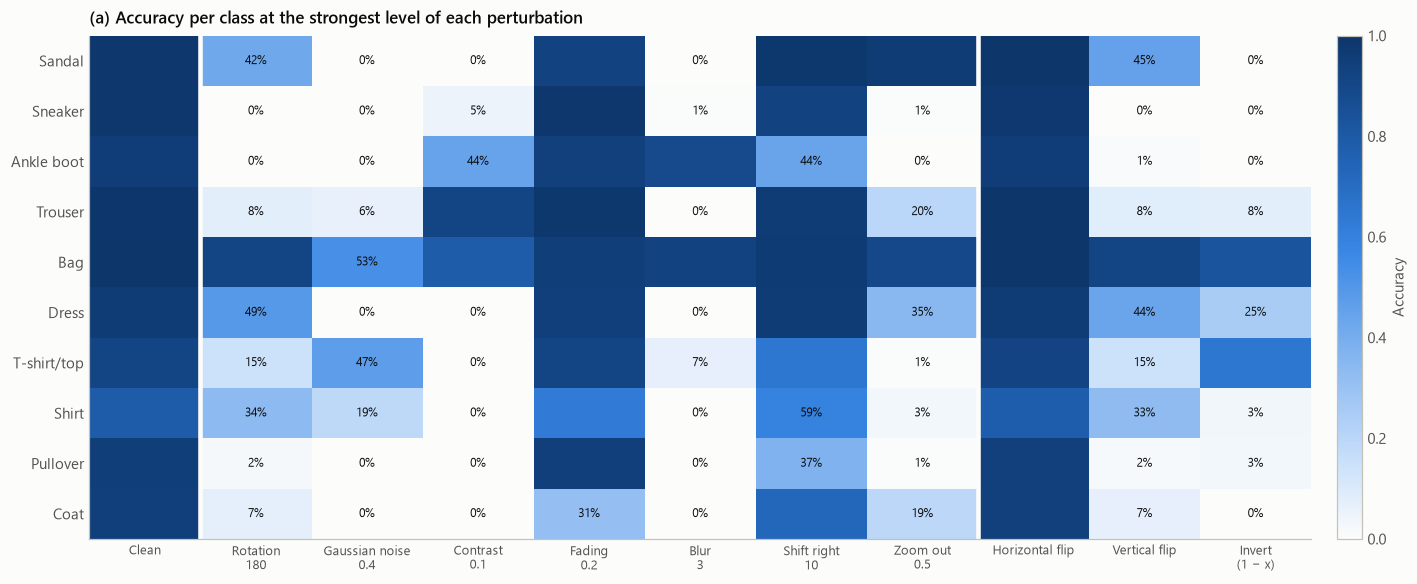

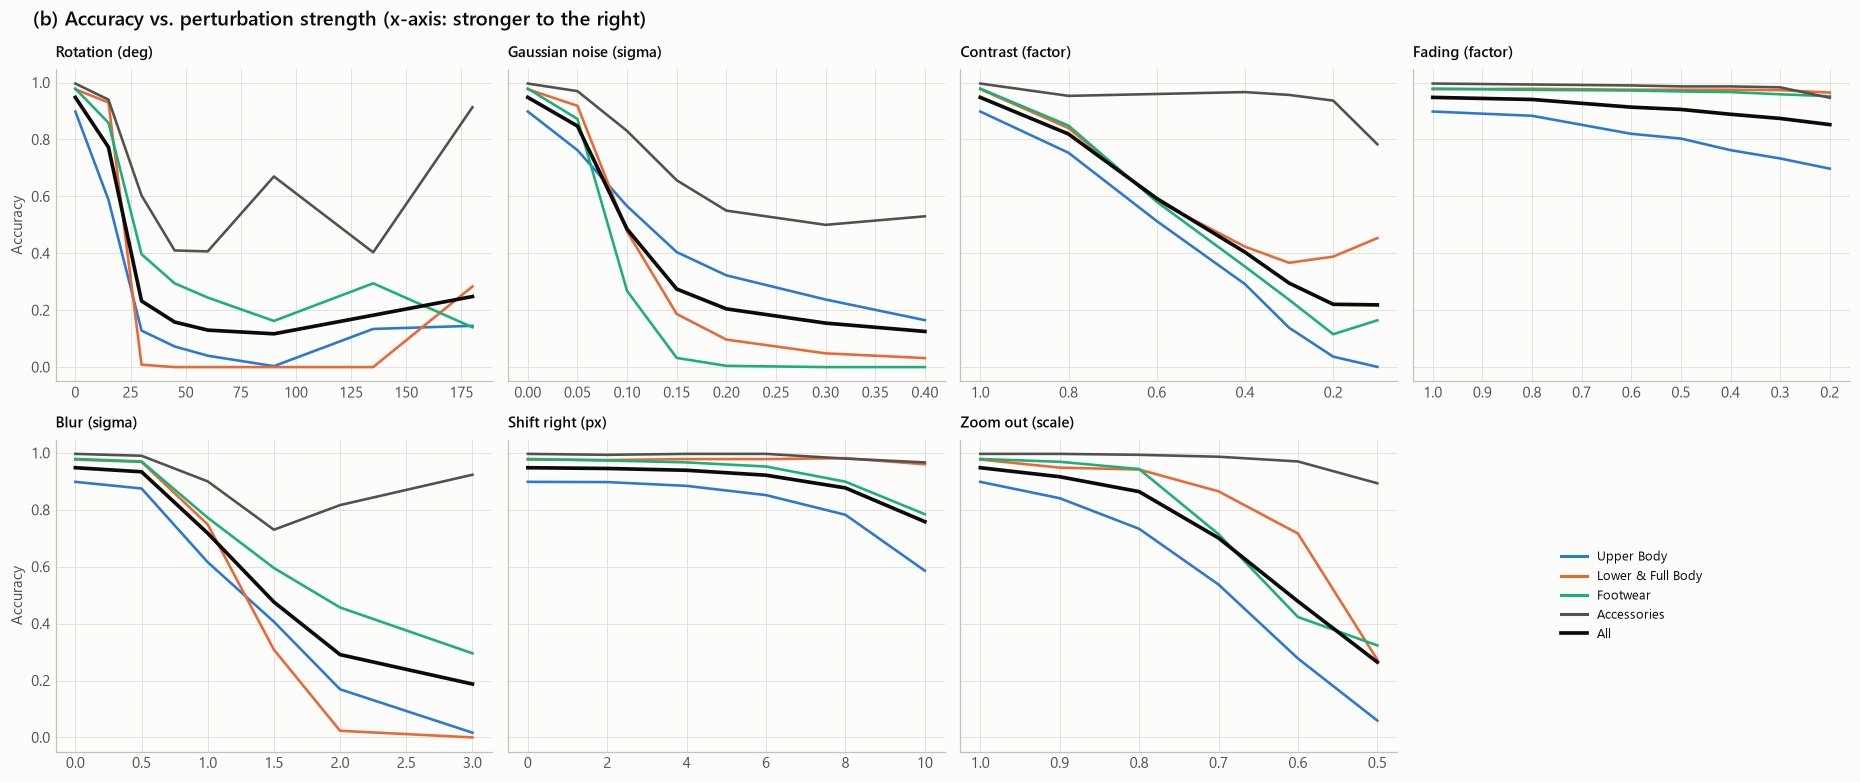

> **V24 · takeaway:** The most damaging perturbation is **gaussian noise** (accuracy 12.5% at the strongest level, clean 94.8%). Sanity check: horizontal flips barely matter (94.6%, the model was trained with flips), but vertical flips drop accuracy to 24.5%, so the model relies on garments being upright. The most fragile class per perturbation: rotation → Sneaker, gaussian noise → Sandal, contrast → Sandal, fading → Coat, blur → Sandal, shift right → Pullover, zoom out → Ankle boot.

In [34]:
cols = [('Clean', 0)] + [(n, lv[-1]) for n, (lv, _) in PERTURBATIONS.items()] + [(n, 1) for n in BINARY_PERTURBATIONS]
H = np.array([[pert_value(n, l, f'acc_{c}') for (n, l) in cols] for c in ORDER])
fig, ax = plt.subplots(figsize=(13, 5.4))
im = ax.imshow(H, cmap=BLUES, vmin=0, vmax=1, aspect='auto')
for r in range(H.shape[0]):
    for j in range(H.shape[1]):
        if H[r, j] < 0.6:
            ax.text(j, r, f'{H[r, j]:.0%}', ha='center', va='center', fontsize=8, color=INK)
ax.set_xticks(np.arange(len(cols)), ['Clean'] + [f"{n.split(' (')[0]}\n{l}" for n, l in cols[1:len(PERTURBATIONS) + 1]]
              + [n.replace(' (', '\n(') for n in BINARY_PERTURBATIONS], fontsize=8.5)
ax.set_yticks(np.arange(10), [CLASS_NAMES[c] for c in ORDER])
ax.grid(False)
ax.axvline(0.5, color=SURFACE, lw=3)
ax.axvline(len(PERTURBATIONS) + 0.5, color=SURFACE, lw=3)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label='Accuracy')
ax.set_title('(a) Accuracy per class at the strongest level of each perturbation')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 7.2), sharey=True)
for ax, (name, (levels, _)) in zip(axes.flat, PERTURBATIONS.items()):
    for g in STRUCTURAL_GROUPS:
        ax.plot(levels, [pert_value(name, lv, f'acc_{g}') for lv in levels], color=GROUP_COLORS[g], lw=1.7)
    ax.plot(levels, [pert_value(name, lv, 'acc') for lv in levels], color=INK, lw=2.4)
    ax.set_title(name, fontsize=10)
    if levels[0] > levels[-1]:
        ax.invert_xaxis()
for ax in axes[:, 0]:
    ax.set_ylabel('Accuracy')
axes.flat[-1].axis('off')
axes.flat[-1].legend(handles=[Line2D([], [], color=col, lw=2, label=g) for g, col in GROUP_COLORS.items()]
                     + [Line2D([], [], color=INK, lw=2.4, label='All')], loc='center')
fig.suptitle('(b) Accuracy vs. perturbation strength (x-axis: stronger to the right)', x=0.02, ha='left')
plt.tight_layout()
plt.show()

strong = {n: pert_value(n, lv[-1], 'acc') for n, (lv, _) in PERTURBATIONS.items()}
worst_p = min(strong, key=strong.get)
hflip, vflip = pert_value('Horizontal flip', 1, 'acc'), pert_value('Vertical flip', 1, 'acc')
clean_acc = pert_value('Clean', 0, 'acc')
fragile = {n: CLASS_NAMES[ORDER[int(np.argmin(H[:, j + 1]))]] for j, n in enumerate(PERTURBATIONS)}
takeaway('V24', f"The most damaging perturbation is **{worst_p.split(' (')[0].lower()}** (accuracy {pct(strong[worst_p])} at the strongest level, clean {pct(clean_acc)}). "
                f"Sanity check: horizontal flips barely matter ({pct(hflip)}, the model was trained with flips), but vertical flips drop accuracy to {pct(vflip)}, "
                f"so the model relies on garments being upright. The most fragile class per perturbation: "
                + ', '.join(f"{n.split(' (')[0].lower()} → {c}" for n, c in fragile.items()) + '.')

### V25 · Where do the predictions drift? Attractor classes

**Question:** When the images are perturbed, which class do the predictions collapse into?
**How to read it:** for four perturbation families: rows = predicted class, columns = strength, colour = share of all predictions (the clean distribution is 10% each). A row that darkens to the right is an **attractor**, the model's default answer for unfamiliar inputs.

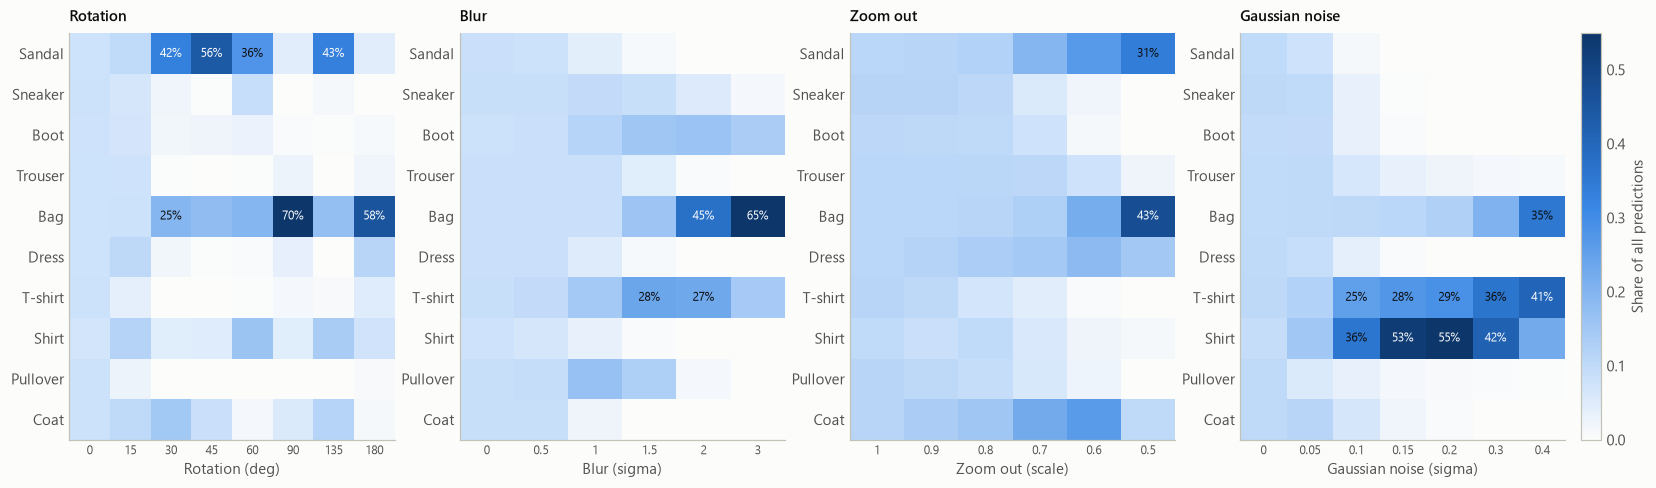

> **V25 · takeaway:** At the strongest level, predictions collapse into: rotation → **Bag** (58.2% of all predictions); blur → **Bag** (65.4% of all predictions); zoom out → **Bag** (43.1% of all predictions); gaussian noise → **T-shirt** (40.7% of all predictions). Unfamiliar inputs are not spread evenly over the classes; the model has default answers.

In [35]:
drift_perts = ['Rotation (deg)', 'Blur (sigma)', 'Zoom out (scale)', 'Gaussian noise (sigma)']
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
attractors = {}
for ax, name in zip(axes, drift_perts):
    levels = PERTURBATIONS[name][0]
    Mshare = np.array([[pert_value(name, lv, f'share_{c}') for lv in levels] for c in ORDER])
    im = ax.imshow(Mshare, cmap=BLUES, vmin=0, vmax=max(0.5, Mshare.max()), aspect='auto')
    for r in range(Mshare.shape[0]):
        for j in range(Mshare.shape[1]):
            if Mshare[r, j] >= 0.25:
                ax.text(j, r, f'{Mshare[r, j]:.0%}', ha='center', va='center', fontsize=8, color='white' if Mshare[r, j] > 0.4 else INK)
    ax.set_xticks(np.arange(len(levels)), levels, fontsize=8)
    ax.set_yticks(np.arange(10), [SHORT[c] for c in ORDER])
    ax.grid(False)
    ax.set_xlabel(name)
    ax.set_title(name.split(' (')[0], fontsize=10)
    last = Mshare[:, -1]
    attractors[name] = (SHORT[ORDER[int(np.argmax(last))]], float(last.max()))
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01, label='Share of all predictions')
plt.show()
collapsing = {n: v for n, v in attractors.items() if v[1] >= 0.25}
spread_out = [n for n in attractors if n not in collapsing]
takeaway('V25', ('At the strongest level, predictions collapse into: ' + '; '.join(
    f"{n.split(' (')[0].lower()} → **{c}** ({pct(s)} of all predictions)" for n, (c, s) in collapsing.items())
    + '. Unfamiliar inputs are not spread evenly over the classes; the model has default answers.' if collapsing else
    'No single class absorbs the perturbed images.')
    + (f" Under {', '.join(n.split(' (')[0].lower() for n in spread_out)} the predictions stay spread out (no class above 25%)." if spread_out else ''))

### V26 · Does confidence fall along with accuracy under shift?

**Question:** When accuracy collapses under a perturbation, does the model notice?
**How to read it:** for each perturbation: accuracy (blue) and mean confidence (red) against strength. The red-shaded area is the **overconfidence gap**. The last panel shows the binary transforms.

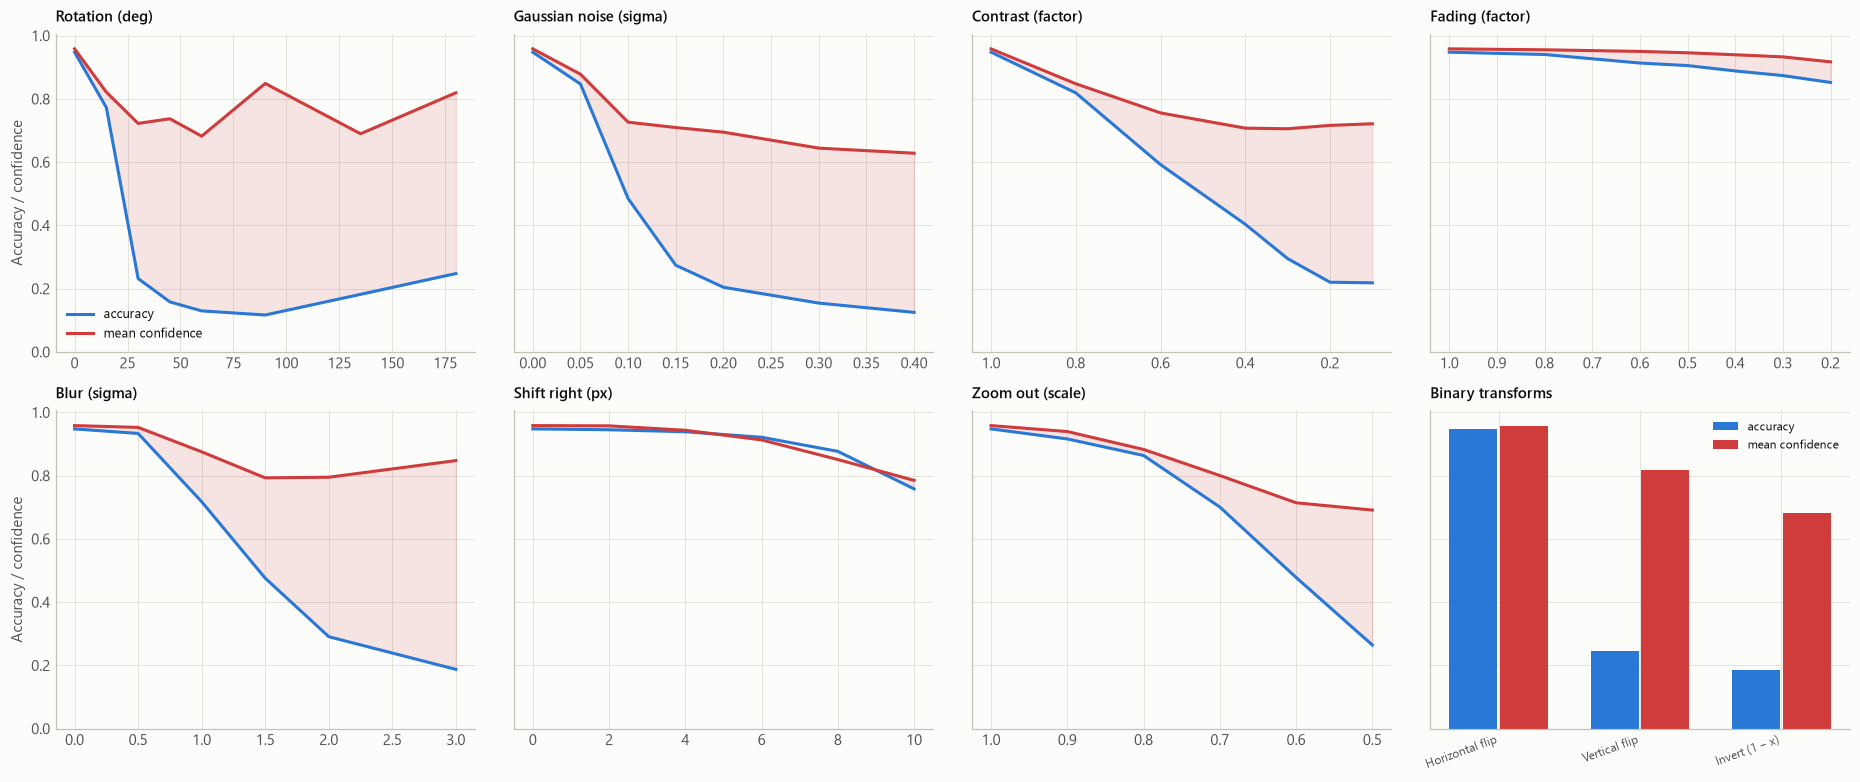

> **V26 · takeaway:** The largest overconfidence gap appears under **rotation**: confidence exceeds accuracy by up to 73 percentage points. On inverted images the model is 18.6% accurate but still 68.3% confident. Under distribution shift, confidence is not a reliable warning signal.

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2), sharey=True)
gaps = {}
for ax, (name, (levels, _)) in zip(axes.flat, PERTURBATIONS.items()):
    a_ = np.array([pert_value(name, lv, 'acc') for lv in levels])
    c_ = np.array([pert_value(name, lv, 'conf') for lv in levels])
    ax.plot(levels, a_, color=C_OK, lw=2, label='accuracy')
    ax.plot(levels, c_, color=C_ERR, lw=2, label='mean confidence')
    ax.fill_between(levels, a_, c_, where=c_ > a_, color=C_ERR, alpha=0.12, interpolate=True)
    ax.set_title(name, fontsize=10)
    if levels[0] > levels[-1]:
        ax.invert_xaxis()
    gaps[name] = (c_ - a_).max()
ax = axes.flat[-1]
names = list(BINARY_PERTURBATIONS)
xs = np.arange(len(names))
ax.bar(xs - 0.18, [pert_value(n, 1, 'acc') for n in names], width=0.34, color=C_OK, label='accuracy')
ax.bar(xs + 0.18, [pert_value(n, 1, 'conf') for n in names], width=0.34, color=C_ERR, label='mean confidence')
ax.set_xticks(xs, names, rotation=20, ha='right', fontsize=8)
ax.set_title('Binary transforms', fontsize=10)
ax.legend(loc='upper right', fontsize=8)
axes[0, 0].legend(loc='lower left')
for ax in axes[:, 0]:
    ax.set_ylabel('Accuracy / confidence')
plt.tight_layout()
plt.show()

gp = max(gaps, key=gaps.get)
inv = 'Invert (1 − x)'
takeaway('V26', f"The largest overconfidence gap appears under **{gp.split(' (')[0].lower()}**: confidence exceeds accuracy by up to "
                f"{gaps[gp] * 100:.0f} percentage points. On inverted images the model is {pct(pert_value(inv, 1, 'acc'))} accurate but still "
                f"{pct(pert_value(inv, 1, 'conf'))} confident. Under distribution shift, confidence is not a reliable warning signal.")

### V27 · Occlusion: which image regions does the decision depend on?

This is a black-box method: each 6×6 patch is erased (set to background) in turn, and the change in output probability is recorded. It needs no gradients or weights. The difference from the team notebook is that the maps are **averaged over many images** instead of shown for one cherry-picked example.

**Question:** Which regions does each class need, and which regions *cause* the top confusions?
**How to read it:** (a) per class, the mean drop in P(true class) when a region is erased (darker = more important), with the class's mean silhouette as an outline. (b) Per top confusion A → B: the mean error image; the regions that *support the wrong class* (erasing them lowers P(B)); and the regions that *hide the true class* (erasing them raises P(A)).

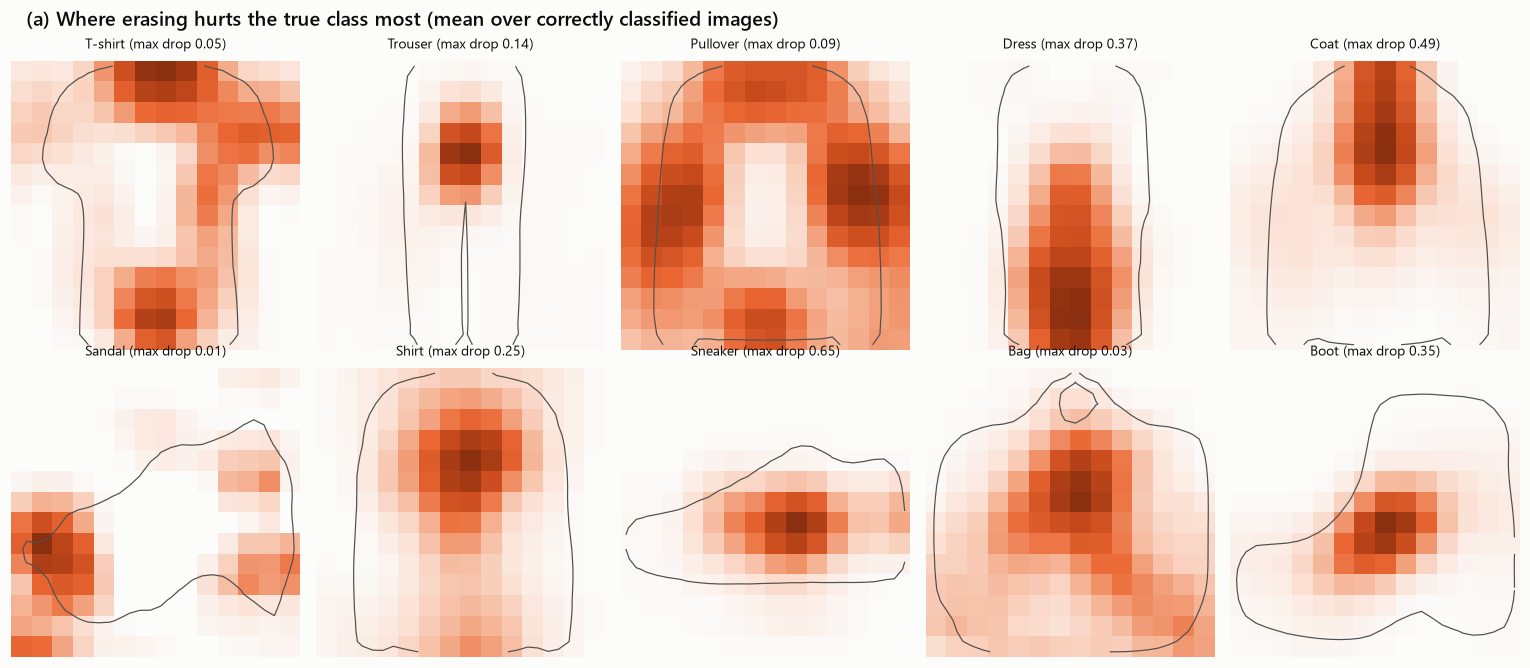

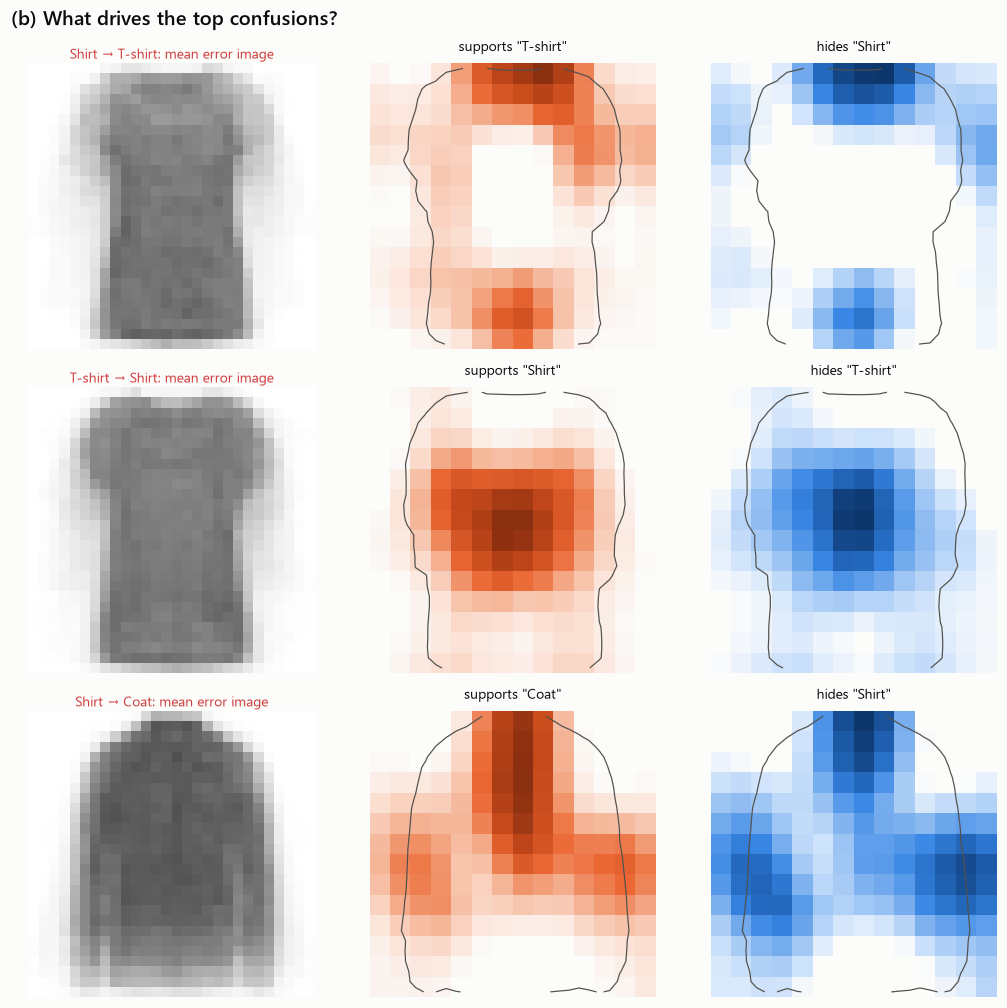

> **V27 · takeaway:** Shirt→T-shirt: erasing a single 6×6 patch flips 75.0% of these errors back to the correct class (evidence for the wrong class sits mainly in the **top-centre** region, the true class is hidden mainly in the **top-centre** region); T-shirt→Shirt: erasing a single 6×6 patch flips 92.5% of these errors back to the correct class (evidence for the wrong class sits mainly in the **middle-centre** region, the true class is hidden mainly in the **middle-centre** region); Shirt→Coat: erasing a single 6×6 patch flips 92.5% of these errors back to the correct class (evidence for the wrong class sits mainly in the **top-centre** region, the true class is hidden mainly in the **top-centre** region). Most of these errors hinge on a small local region (e.g. collar or sleeves), so they are fragile, borderline decisions.

In [37]:
PATCH, STRIDE = 6, 2
_pos = [(r, c) for r in range(0, 28 - PATCH + 1, STRIDE) for c in range(0, 28 - PATCH + 1, STRIDE)]
OCC_MASKS = torch.ones(len(_pos), 1, 28, 28, device=device)
for k, (r, c) in enumerate(_pos):
    OCC_MASKS[k, :, r:r + PATCH, c:c + PATCH] = 0
OCC_COVER = (1 - OCC_MASKS)[:, 0]
OCC_COUNT = OCC_COVER.sum(0)


def occlusion(img, target):
    """Erase every 6x6 patch once; return the per-pixel mean drop of P(target) and all occluded probabilities."""
    x = torch.as_tensor(img, device=device)[None, None]
    base = blackbox.predict_proba(x)[0]
    P = blackbox.predict_proba(x * OCC_MASKS)
    delta = torch.as_tensor(base[target] - P[:, target], device=device, dtype=torch.float32)
    return ((delta[:, None, None] * OCC_COVER).sum(0) / OCC_COUNT).cpu().numpy(), P


N_OCC = 15 if FAST_MODE else 60
rng = np.random.default_rng(SEED)
class_maps = []
for c in range(10):
    pool = np.where((y_test == c) & correct & (conf > 0.9))[0]
    items = rng.choice(pool, min(N_OCC, len(pool)), replace=False)
    class_maps.append(np.mean([occlusion(X_test[i], c)[0] for i in items], axis=0))

fig, axes = plt.subplots(2, 5, figsize=(14, 6.2))
for ax, c in zip(axes.flat, range(10)):
    ax.imshow(class_maps[c], cmap=ORANGES, vmin=0, vmax=max(class_maps[c].max(), 1e-6))
    ax.contour(X_test[(y_test == c) & correct].mean(0), levels=[0.15], colors=INK2, linewidths=0.8)
    embed_axes(ax)
    ax.set_title(f'{SHORT[c]} (max drop {class_maps[c].max():.2f})', fontsize=9, loc='center', fontweight='normal')
fig.suptitle('(a) Where erasing hurts the true class most (mean over correctly classified images)', x=0.02, ha='left')
plt.tight_layout()
plt.show()

occ_pairs = dir_pairs[:3]
fig, axes = plt.subplots(len(occ_pairs), 3, figsize=(9.5, 3.1 * len(occ_pairs)))
occ_summary = {}
for r, (n, a, b) in enumerate(occ_pairs):
    items = np.where((y_test == a) & (preds == b))[0]
    items = rng.choice(items, min(40, len(items)), replace=False)
    sup, hide, fixed = [], [], []
    for i in items:
        m_b, P = occlusion(X_test[i], b)
        m_a, _ = occlusion(X_test[i], a)
        sup.append(m_b); hide.append(-m_a); fixed.append((P.argmax(1) == a).any())
    sup, hide = np.mean(sup, 0), np.mean(hide, 0)
    show_img(axes[r, 0], X_test[items].mean(0), f'{SHORT[a]} → {SHORT[b]}: mean error image', color=C_ERR, fs=9)
    axes[r, 1].imshow(np.clip(sup, 0, None), cmap=ORANGES)
    axes[r, 1].set_title(f'supports "{SHORT[b]}"', fontsize=9, loc='center', fontweight='normal')
    axes[r, 2].imshow(np.clip(hide, 0, None), cmap=BLUES)
    axes[r, 2].set_title(f'hides "{SHORT[a]}"', fontsize=9, loc='center', fontweight='normal')
    for ax in axes[r, 1:]:
        ax.contour(X_test[items].mean(0), levels=[0.15], colors=INK2, linewidths=0.8)
        embed_axes(ax)
    occ_summary[(a, b)] = (np.mean(fixed), region_extremes(sup)[0], region_extremes(hide)[0])
fig.suptitle('(b) What drives the top confusions?', x=0.02, ha='left')
plt.tight_layout()
plt.show()

takeaway('V27', '; '.join(f"{SHORT[a]}→{SHORT[b]}: erasing a single 6×6 patch flips {pct(f)} of these errors back to the correct class "
                          f"(evidence for the wrong class sits mainly in the **{s}** region, the true class is hidden mainly in the **{h}** region)"
                          for (a, b), (f, s, h) in occ_summary.items())
         + '. Most of these errors hinge on a small local region (e.g. collar or sleeves), so they are fragile, borderline decisions.')

### V28 · Morphing counterfactuals: where exactly does the decision flip?

**Question:** If an image of A is gradually blended into a similar-looking image of B, where does the prediction switch, and is the switch symmetric?
**How to read it:** for the three most-confused pairs, confidently classified images of A are paired with their nearest confidently classified B in pixel space and blended in 21 steps (α = 0 pure A, α = 1 pure B). Lines = median P(A) (blue) and P(B) (orange), bands = 25-75% range, black line = mean switch point. A switch before α = 0.5 means the model is **biased towards B**. Below each plot is one example morph.

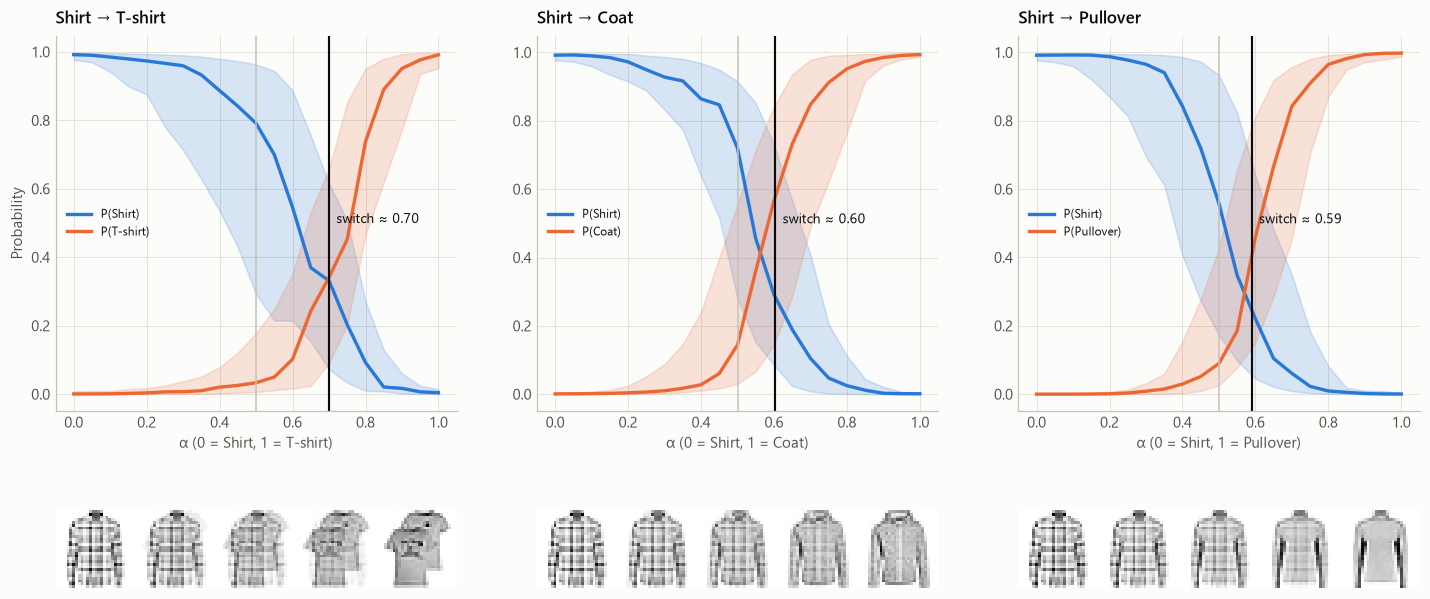

> **V28 · takeaway:** Shirt→T-shirt switches at α≈0.70 (holds on to Shirt); Shirt→Coat switches at α≈0.60 (holds on to Shirt); Shirt→Pullover switches at α≈0.59 (holds on to Shirt). A confidently classified Shirt has to be blended well past the halfway point before the decision flips, so there is no general bias towards the other class. The errors come from specific images that already look like the other class (see V16, V20 and V23).

In [38]:
alphas = np.linspace(0, 1, 21)
N_MORPH = 15 if FAST_MODE else 40
fig = plt.figure(figsize=(16, 6.8))
gs = fig.add_gridspec(2, 3, height_ratios=[3, 1], hspace=0.3)
morph_notes, switches = [], []
for col, (n, a, b) in enumerate(sym_pairs):
    if E[a, b] < E[b, a]:
        a, b = b, a                                   # start from the class that errs more towards the other
    idx_a = np.where((y_test == a) & correct & (conf > 0.9))[0][:N_MORPH]
    pool_b = np.where((y_test == b) & correct & (conf > 0.9))[0]
    _, j = NearestNeighbors(n_neighbors=1).fit(Z_test[pool_b]).kneighbors(Z_test[idx_a])
    idx_b = pool_b[j[:, 0]]
    blends = (1 - alphas)[None, :, None, None] * X_test[idx_a][:, None] + alphas[None, :, None, None] * X_test[idx_b][:, None]
    P = blackbox.predict_proba(blends.reshape(-1, 28, 28)).reshape(len(idx_a), len(alphas), 10)
    pa, pb = P[:, :, a], P[:, :, b]
    switch = np.where((pb > pa).any(1), alphas[(pb > pa).argmax(1)], 1.0)
    ax = fig.add_subplot(gs[0, col])
    for arr, colr, lab in [(pa, SERIES[0], f'P({SHORT[a]})'), (pb, SERIES[1], f'P({SHORT[b]})')]:
        ax.fill_between(alphas, np.quantile(arr, 0.25, axis=0), np.quantile(arr, 0.75, axis=0), color=colr, alpha=0.18)
        ax.plot(alphas, np.median(arr, axis=0), color=colr, lw=2.2, label=lab)
    ax.axvline(0.5, color=AXIS, lw=1)
    ax.axvline(switch.mean(), color=INK, lw=1.4)
    ax.text(switch.mean() + 0.02, 0.5, f'switch ≈ {switch.mean():.2f}', fontsize=9, color=INK)
    ax.set_xlabel(f'α (0 = {SHORT[a]}, 1 = {SHORT[b]})')
    ax.set_title(f'{SHORT[a]} → {SHORT[b]}')
    ax.legend(loc='center left', fontsize=8)
    if col == 0:
        ax.set_ylabel('Probability')
    show_img(fig.add_subplot(gs[1, col]), montage(blends[0, ::5], ncols=5))
    bias = (f'biased towards {SHORT[b]}' if switch.mean() < 0.45 else f'holds on to {SHORT[a]}' if switch.mean() > 0.55 else 'roughly balanced')
    morph_notes.append(f'{SHORT[a]}→{SHORT[b]} switches at α≈{switch.mean():.2f} ({bias})')
    switches.append((SHORT[a], SHORT[b], switch.mean()))
plt.show()
if all(s > 0.55 for _, _, s in switches):
    morph_end = (f' A confidently classified {switches[0][0]} has to be blended well past the halfway point before the decision flips, so there is no general '
                 f'bias towards the other class. The errors come from specific images that already look like the other class (see V16, V20 and V23).')
elif all(s < 0.45 for _, _, s in switches):
    morph_end = ' A little of the other class is enough to tip the decision, which matches the error asymmetry in V3.'
else:
    morph_end = ' The boundaries are not equally placed: the model needs more evidence to switch for some pairs than for others.'
takeaway('V28', '; '.join(morph_notes) + '.' + morph_end)

---
## H · Training dynamics, seen only through the outputs

The per-epoch test predictions were logged during training (outputs only), so the course's ConfusionFlow / Projection Path Explorer ideas can be applied without opening the model.

### V29 · How does each class learn over the epochs?

**Question:** Do all classes improve together, or are some learned late or never?
**How to read it:** (a) train and test accuracy per epoch. (b) Test accuracy per class and epoch, hardest class on top.

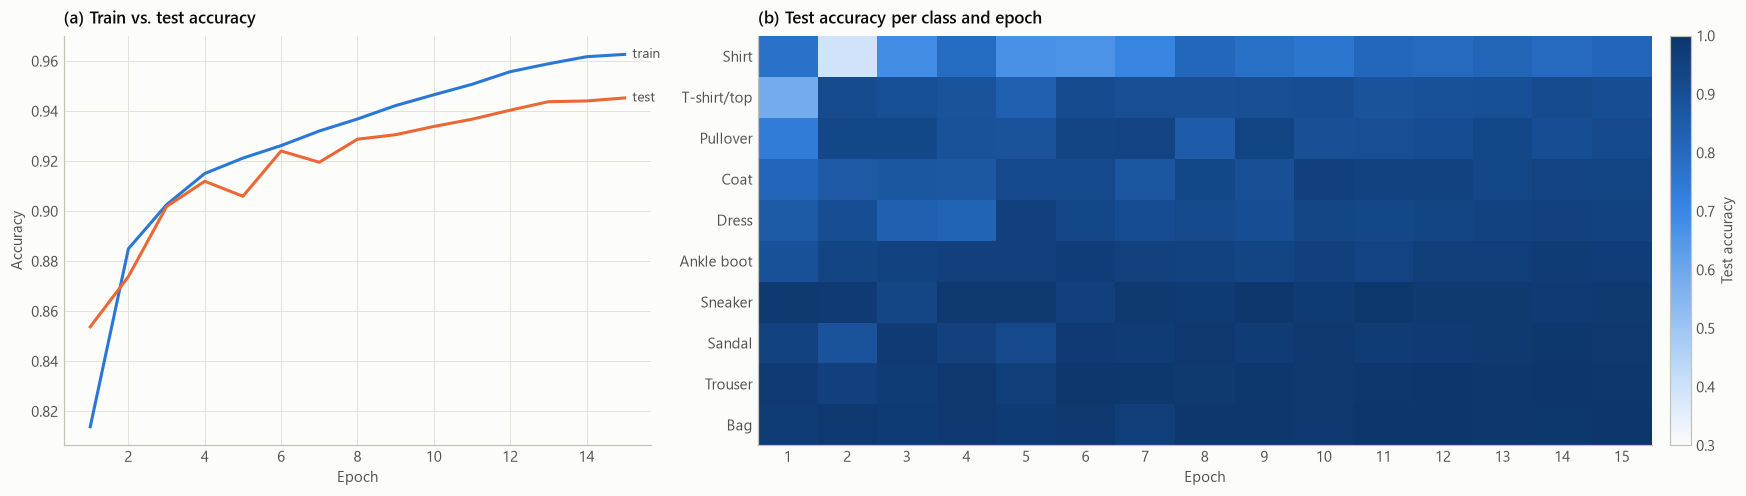

> **V29 · takeaway:** Most classes reach their final accuracy (±2 pp) within the first epochs; **Shirt** settles last (epoch 8). Shirt improves from 77.1% (epoch 1) to 81.7%. Final train-test gap: 1.7 pp (train accuracy is measured on augmented images).

In [39]:
E_N = len(epoch_probs)
epoch_preds = epoch_probs.argmax(2)
epoch_correct = epoch_preds == y_test[None]
cls_acc_epoch = np.array([[epoch_correct[e, y_test == c].mean() for e in range(E_N)] for c in range(10)])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1, 1.6]})
ax = axes[0]
ax.plot(history['epoch'], history['train_acc'], color=SERIES[0], lw=2)
ax.plot(history['epoch'], history['test_acc'], color=SERIES[1], lw=2)
ax.text(history['epoch'].iloc[-1] + 0.2, history['train_acc'].iloc[-1], 'train', color=INK2, va='center', fontsize=9)
ax.text(history['epoch'].iloc[-1] + 0.2, history['test_acc'].iloc[-1], 'test', color=INK2, va='center', fontsize=9)
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.set_title('(a) Train vs. test accuracy')
ax = axes[1]
rows = ACC_ORDER[::-1]
im = ax.imshow(cls_acc_epoch[rows], cmap=BLUES, vmin=np.floor(cls_acc_epoch.min() * 10) / 10, vmax=1, aspect='auto')
ax.set_yticks(np.arange(10), [CLASS_NAMES[c] for c in rows])
ax.set_xticks(np.arange(E_N), np.arange(1, E_N + 1))
ax.set_xlabel('Epoch')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label='Test accuracy')
ax.set_title('(b) Test accuracy per class and epoch')
plt.tight_layout()
plt.show()

settle = {c: int(np.argmax(cls_acc_epoch[c] >= cls_acc_epoch[c, -1] - 0.02)) + 1 for c in range(10)}
late = max(settle, key=settle.get)
gap = history['train_acc'].iloc[-1] - history['test_acc'].iloc[-1]
takeaway('V29', f"Most classes reach their final accuracy (±2 pp) within the first epochs; **{CLASS_NAMES[late]}** settles last (epoch {settle[late]}). "
                f"{CLASS_NAMES[WORST]} improves from {pct(cls_acc_epoch[WORST, 0])} (epoch 1) to {pct(cls_acc_epoch[WORST, -1])}. "
                f"Final train-test gap: {gap * 100:.1f} pp (train accuracy is measured on augmented images).")

### V30 · Projection paths of the confusion matrix (Projection Path Explorer style)

**Question:** How does the model's confusion pattern move towards a perfect classifier during training?
**How to read it:** (a) each dot is the whole (row-normalised) confusion matrix after one epoch, projected with PCA. Darker = later epoch, and the star is the perfect (identity) matrix. (b) Per class: the *error profile* (that class's confusion row minus its perfect row) over the epochs. All perfect rows map to the same point (the star), so every path would end there for a perfect model. The direction a path approaches from shows which classes absorb its errors. The three hardest classes are coloured.

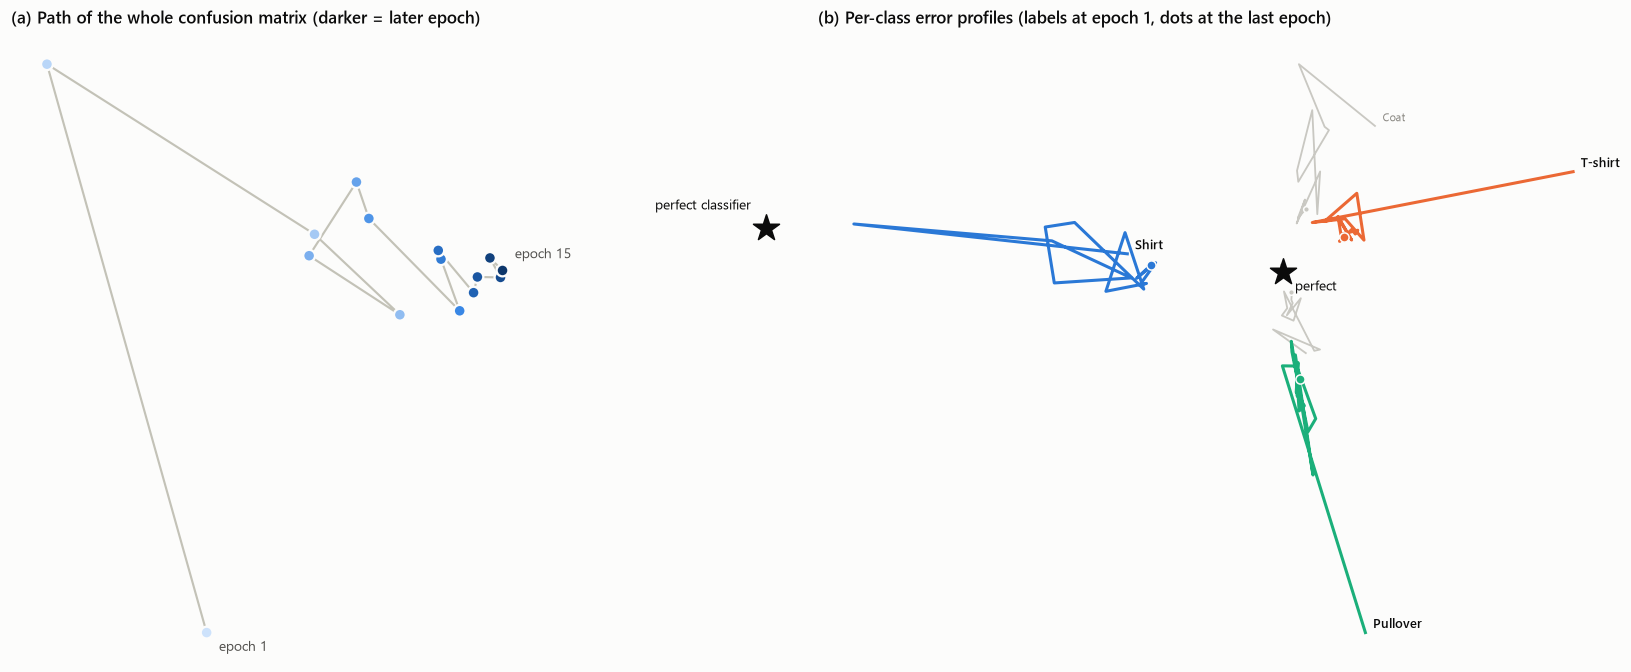

> **V30 · takeaway:** 56.5% of the improvement between epoch 1 and epoch 15 happens by epoch 3; after that the path only creeps towards the star. The per-class error profiles furthest from perfect at the end: Shirt, T-shirt, Pullover. Over the last 5 epochs Shirt's distance to perfect shrinks by 25.9%: it is still improving slowly, but it stays by far the furthest from perfect.

In [40]:
def norm_cm(pred):
    M = np.zeros((10, 10))
    np.add.at(M, (y_test, pred), 1)
    return M / M.sum(1, keepdims=True)


CMs = np.stack([norm_cm(epoch_preds[e]) for e in range(E_N)])
flat = np.concatenate([CMs.reshape(E_N, -1), np.eye(10).reshape(1, -1)])
P2 = PCA(n_components=2).fit_transform(flat)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
ax = axes[0]
ax.plot(P2[:-1, 0], P2[:-1, 1], color=AXIS, lw=1.4, zorder=1)
ax.scatter(P2[:-1, 0], P2[:-1, 1], c=np.arange(1, E_N + 1), cmap=BLUES_MARK, s=60, zorder=2, edgecolor=SURFACE, linewidth=1.5)
ax.scatter(*P2[-1], marker='*', s=320, color=INK, zorder=3)
ax.annotate('perfect classifier', P2[-1], xytext=(-10, 12), textcoords='offset points', fontsize=9, ha='right')
ax.annotate('epoch 1', P2[0], xytext=(8, -12), textcoords='offset points', fontsize=9, color=INK2)
ax.annotate(f'epoch {E_N}', P2[-2], xytext=(8, 8), textcoords='offset points', fontsize=9, color=INK2)
embed_axes(ax)
ax.set_title('(a) Path of the whole confusion matrix (darker = later epoch)')

ax = axes[1]
err_prof = np.concatenate([CMs[:, c, :] - np.eye(10)[c] for c in range(10)])     # [10 * E_N, 10]
pca_b = PCA(n_components=2).fit(np.vstack([err_prof, np.zeros((1, 10))]))
Q = pca_b.transform(err_prof)
origin = pca_b.transform(np.zeros((1, 10)))[0]
hard3 = list(ACC_ORDER[-3:][::-1])
start_dist = np.linalg.norm(Q[::E_N] - origin, axis=1)        # distance of each class's epoch-1 point from the star
for c in range(10):
    path = Q[c * E_N:(c + 1) * E_N]
    hi = c in hard3
    col = SERIES[hard3.index(c)] if hi else C_CONTEXT
    ax.plot(path[:, 0], path[:, 1], color=col, lw=2 if hi else 1.2, zorder=3 if hi else 1)
    ax.scatter(*path[-1], color=col, s=36 if hi else 14, zorder=3 if hi else 1, edgecolor=SURFACE, linewidth=1)
    if hi or start_dist[c] > 0.25 * start_dist.max():          # skip labels of short paths that pile up at the star
        ax.annotate(SHORT[c], path[0], xytext=(5, 3), textcoords='offset points', fontsize=8.5 if hi else 7.5,
                    color=INK if hi else MUTED, fontweight='semibold' if hi else 'normal')
ax.scatter(*origin, marker='*', s=320, color=INK, zorder=4)
ax.annotate('perfect', origin, xytext=(8, -12), textcoords='offset points', fontsize=9)
embed_axes(ax)
ax.set_title('(b) Per-class error profiles (labels at epoch 1, dots at the last epoch)')
plt.tight_layout()
plt.show()

dist = np.linalg.norm(CMs - np.eye(10)[None], axis=(1, 2))
early = min(3, E_N) - 1
share_early = (dist[0] - dist[early]) / max(dist[0] - dist[-1], 1e-9)
row_dist = np.array([[np.linalg.norm(CMs[e, c] - np.eye(10)[c]) for e in range(E_N)] for c in range(10)])
far = list(np.argsort(-row_dist[:, -1])[:3])
back = max(0, E_N - 6)
late_gain = 1 - row_dist[far[0], -1] / max(row_dist[far[0], back], 1e-9)
takeaway('V30', f"{pct(min(share_early, 1.0))} of the improvement between epoch 1 and epoch {E_N} happens by epoch {early + 1}; after that the path only creeps "
                f"towards the star. The per-class error profiles furthest from perfect at the end: " + ', '.join(SHORT[c] for c in far)
                + f". Over the last {E_N - 1 - back} epochs {SHORT[far[0]]}'s distance to perfect shrinks by {pct(late_gain)}"
                + (", so more of the same training is unlikely to close this gap." if late_gain < 0.15 else
                   ": it is still improving slowly, but it stays by far the furthest from perfect."))

### V31 · Instance-level stability over training (InstanceFlow style)

**Question:** Are the final errors images the model never got right, or images it got right at some point and lost again?
**How to read it:** every test image is assigned one category: *always correct*, *learned later* (wrong early, then correct), *unstable* (≥ 3 flips, ends correct), *forgotten* (correct at some epoch, wrong at the end), *never learned*. The bars show everything except *always correct*, whose share is printed on the right.

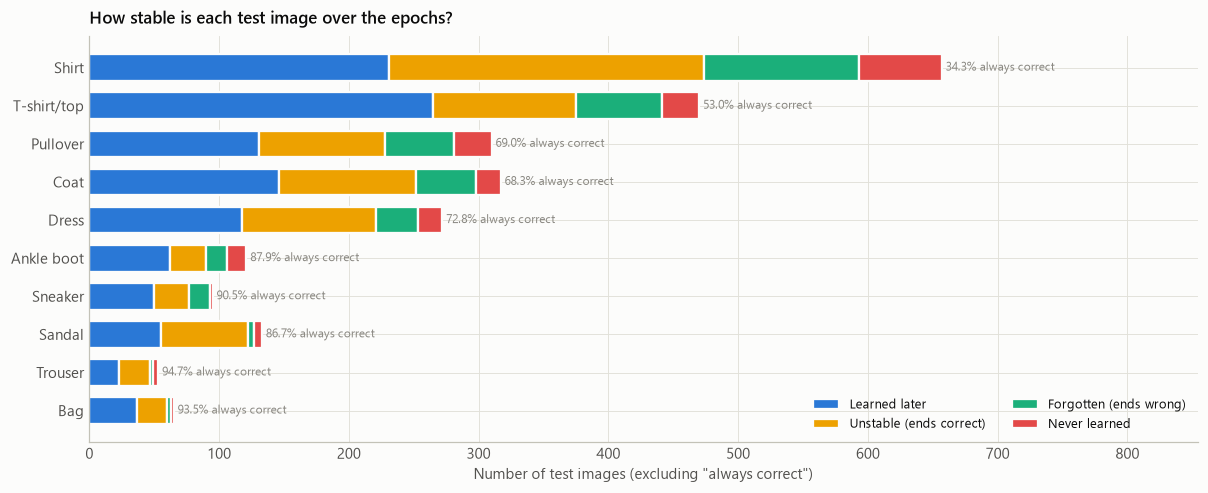

> **V31 · takeaway:** 65.4% of the final errors were **correct at some earlier epoch** ("forgotten"); the other 34.6% were never learned. 828 images flip at least three times. Mean final confidence: forgotten 67.4%, never learned 81.7%, always correct 99.2%. Forgotten images sit on the decision boundary, while never-learned images are confidently placed in the wrong class.

In [41]:
flips = (epoch_correct[1:] != epoch_correct[:-1]).sum(0)
final_ok, ever_ok, always_ok = epoch_correct[-1], epoch_correct.any(0), epoch_correct.all(0)
CATS = ['Learned later', 'Unstable (ends correct)', 'Forgotten (ends wrong)', 'Never learned']
CAT_COLORS = ['#2a78d6', '#eda100', '#1baf7a', '#e34948']
cat = np.full(len(y_test), 'Always correct', dtype=object)
cat[final_ok & ~always_ok & (flips < 3)] = CATS[0]
cat[final_ok & ~always_ok & (flips >= 3)] = CATS[1]
cat[~final_ok & ever_ok] = CATS[2]
cat[~final_ok & ~ever_ok] = CATS[3]

fig, ax = plt.subplots(figsize=(13, 4.8))
rows = ACC_ORDER                       # best at the bottom, hardest on top
left = np.zeros(10)
for k, cname in enumerate(CATS):
    vals = np.array([((y_test == c) & (cat == cname)).sum() for c in rows])
    ax.barh(np.arange(10), vals, left=left, color=CAT_COLORS[k], edgecolor=SURFACE, linewidth=1.5, label=cname, height=0.7)
    left += vals
for y, c in enumerate(rows):
    ax.text(left[y] + 3, y, f"{pct(((y_test == c) & (cat == 'Always correct')).sum() / (y_test == c).sum())} always correct",
            va='center', fontsize=8, color=MUTED)
ax.set_yticks(np.arange(10), [CLASS_NAMES[c] for c in rows])
ax.set_xlabel('Number of test images (excluding "always correct")')
ax.set_xlim(0, left.max() * 1.3)
ax.legend(loc='lower right', ncol=2)
ax.set_title('How stable is each test image over the epochs?')
plt.show()

forgot = (cat == CATS[2]).sum() / (~final_ok).sum()
takeaway('V31', f"{pct(forgot)} of the final errors were **correct at some earlier epoch** (\"forgotten\"); the other {pct(1 - forgot)} were never learned. "
                f"{(cat == CATS[1]).sum()} images flip at least three times. Mean final confidence: forgotten {pct(conf[cat == CATS[2]].mean())}, "
                f"never learned {pct(conf[cat == CATS[3]].mean())}, always correct {pct(conf[cat == 'Always correct'].mean())}. "
                f"Forgotten images sit on the decision boundary, while never-learned images are confidently placed in the wrong class.")

---
## Interactive explorer (works when the notebook runs live)

Pick a true class, a predicted class and a confidence range to browse the matching test images. This is useful for drilling into any finding above. It needs `ipywidgets` (pre-installed on Colab). In a static view of the notebook it shows nothing.

In [42]:
try:
    import ipywidgets as widgets

    def explore(true_class, predicted_class, min_conf, max_conf):
        t = CLASS_NAMES.index(true_class)
        m = (y_test == t) & (conf >= min_conf) & (conf <= max_conf)
        if predicted_class != 'any':
            m &= preds == CLASS_NAMES.index(predicted_class)
        idx = np.where(m)[0][:40]
        print(f'{m.sum()} matching test images (showing {len(idx)})')
        if len(idx) == 0:
            return
        fig, axes = plt.subplots(4, 10, figsize=(13, 6))
        for ax in axes.flat:
            ax.axis('off')
        for ax, i in zip(axes.flat, idx):
            show_img(ax, X_test[i], f'{SHORT[preds[i]]} {conf[i]:.0%}', color=INK2 if correct[i] else C_ERR, fs=7.5)
        plt.tight_layout()
        plt.show()

    widgets.interact(explore,
                     true_class=widgets.Dropdown(options=CLASS_NAMES, value=CLASS_NAMES[WORST], description='true'),
                     predicted_class=widgets.Dropdown(options=['any'] + CLASS_NAMES, value='any', description='predicted'),
                     min_conf=widgets.FloatSlider(value=0.0, min=0, max=1, step=0.05, description='min conf'),
                     max_conf=widgets.FloatSlider(value=1.0, min=0, max=1, step=0.05, description='max conf'))
except ImportError:
    print('ipywidgets is not installed - skipping the interactive explorer.')

interactive(children=(Dropdown(description='true', index=6, options=('T-shirt/top', 'Trouser', 'Pullover', 'Dr…

---
## Findings summary (generated from this run)

In [43]:
display(Markdown('\n'.join(f'{k + 1}. **{tag}** - {text}' for k, (tag, text) in enumerate(FINDINGS))))

1. **V1** - **Shirt** is the hardest class (81.7% accuracy) and alone causes 33.5% of all 547 errors. The three hardest classes are Shirt, T-shirt/top, Pullover - all upper-body garments. When the model is wrong it is still 72.4% confident on average (vs. 97.0% when right).
2. **V2** - Sorting by error similarity reveals 2 confusion block(s): {T-shirt, Pullover, Dress, Coat, Shirt}; {Sandal, Sneaker, Boot}. 95.8% of all errors happen inside these blocks, and only 3 errors cross between footwear and the rest. The mistakes are look-alike mistakes, not random noise.
3. **V3** - The five strongest flows are Shirt→T-shirt (82), T-shirt→Shirt (69), Shirt→Coat (46), Shirt→Pullover (33), Coat→Shirt (31); together they make up 47.7% of all errors. Asymmetry check: Shirt→T-shirt happens 82× but the reverse only 69×.
4. **V4** - 78.6% of errors stay inside the structural group (chance: 29.5%), but only 12.6% stay inside the seasonal group (chance: 26.5%). The model's confusions follow **shape**, not season or function. The seasonal grouping can be dropped as an explanation.
5. **V5** - Overall the model is slightly overconfident (mean confidence 95.7% vs. accuracy 94.5%, ECE 0.012). The problem is the tail: **21.6% of all errors are made with ≥90% confidence**, so a confidence threshold alone cannot catch them. The worst-calibrated class is Shirt (ECE 0.066).
6. **V6** - Wrong Sandal predictions have the highest median confidence (83.9%): these are confident, 'silent' errors. Wrong Dress predictions are the most hesitant (median 62.8%).
7. **V7** - Abstaining on the 10% least-confident images lifts accuracy from 94.5% to 98.1% and removes 68.2% of all errors. At 90% coverage Upper Body reaches only 93.6%, against 99.7% for Footwear: abstention helps least where the errors are.
8. **V8** - In 79.2% of the errors the true class is the model's **second choice**. Top-2 accuracy is 98.9% overall and 97.2% for Shirt. Most errors are near misses between two candidates, not a complete misreading of the image.
9. **V9** - 11.5% of all test images have a runner-up class with >10% probability. The most frequent hesitations are T-shirt/Shirt (360), Coat/Shirt (161), Pullover/Shirt (134), Pullover/Coat (110), Sneaker/Boot (100). These chords are the "fault lines" of the model; the footwear and clothing anchors are almost never connected.
10. **V10** - 26.1% of the errors are **camouflaged**: at least 8 of their 10 nearest neighbours in output space are correctly classified images of the predicted class. No output-based check can flag them; only the input view (Sections D-F) can explain them.
11. **V11** - Images "on the fence" (|log-odds| < 1): T-shirt/Shirt: 181, Coat/Shirt: 94, Pullover/Shirt: 97. Of the images on the wrong side of the boundary, 27.2% (T-shirt/Shirt), 30.4% (Coat/Shirt), 30.2% (Pullover/Shirt) are clear votes for the other class (more than 7× more likely, |log-odds| > 2) rather than borderline cases.
12. **V12** - In raw pixel space, upper-body garments have a mean neighbourhood purity of 58.8% (share of the 15 nearest images with the same label), against 86.1% for everything else. The upper-body region produces 77.7% of all errors: the model fails where the classes already overlap in pixel space.
13. **V14** - The four hotspots H1-H4 hold 9.4% of the test images but 30.0% of all errors. The worst 20% of the map (by region) holds 50.7% of the errors.
14. **V15** - **H1** (205 images, 21.5% wrong): mostly T-shirt (32.7%), main error Shirt→T-shirt (11×). Its T-shirts differ from other T-shirts by lower ink intensity (z=-0.8) and lower l-r symmetry (z=-0.5) · **H2** (214 images, 20.1% wrong): mostly Pullover (29.4%), main error Pullover→Shirt (7×). Its Pullovers differ from other Pullovers by higher width (z=+1.8) and higher ink area (z=+1.8) · **H3** (277 images, 15.2% wrong): mostly T-shirt (32.5%), main error Shirt→T-shirt (18×). Its T-shirts differ from other T-shirts by lower width (z=-1.7) and lower aspect (w/h) (z=-1.5) · **H4** (245 images, 14.3% wrong): mostly Coat (49.0%), main error Dress→Coat (6×). Its Coats differ from other Coats by lower width (z=-1.0) and lower aspect (w/h) (z=-1.0)
15. **V16** - Shirt is not uniformly hard: sub-type 1 has an error rate of 31.7% (errors mostly → T-shirt), sub-type 6 only 11.0%. Compared with the easiest sub-type, the hardest one has higher ink intensity (z=+1.3), lower ink area (z=-0.9), higher l-r symmetry (z=+0.8).
16. **V17** - The strongest differences: misclassified Sneakers have higher height (d=+1.70); misclassified Sneakers have higher ink area (d=+1.68); misclassified Sneakers have lower aspect (w/h) (d=-1.34); misclassified Boots have higher l-r symmetry (d=+1.24). These are concrete, testable hypotheses for Phase II.
17. **V18** - For upper-body garments the error rate depends most on **ink area**: it varies by 30.0 percentage points across deciles and peaks in decile 3 (low values).
18. **V19** - T-shirt: median box fill 0.73 when wrong vs. 0.69 when right; Pullover: median box fill 0.80 when wrong vs. 0.83 when right; Coat: median l-r symmetry 0.86 when wrong vs. 0.90 when right; Shirt: median ink area 0.54 when wrong vs. 0.60 when right.
19. **V20** - Shirt→T-shirt: more ink bottom-centre, less ink middle-left; the average error image correlates r=0.97 with an average T-shirt and r=0.89 with an average Shirt; T-shirt→Shirt: more ink bottom-left, less ink top-centre; the average error image correlates r=0.90 with an average Shirt and r=0.97 with an average T-shirt; Shirt→Coat: more ink middle-centre, less ink top-left; the average error image correlates r=0.99 with an average Coat and r=0.97 with an average Shirt; Shirt→Pullover: more ink middle-right, less ink bottom-centre; the average error image correlates r=0.98 with an average Pullover and r=0.95 with an average Shirt.
20. **V21** - The most unusual 10% of test images have an error rate of 11.5%, against 0.4% for the most typical 10% (×28.8). The model's confidence on its wrong answers stays at 72.0% even for the most unusual images: it does not signal that it is out of its comfort zone. (Pixel distance also grows with ink amount, so read this together with V17.)
21. **V22** - When at most 3 of 10 training neighbours share the label, the error rate is 30.0%; with 8 or more it is 0.8%. In 49.0% of all errors the model predicts exactly the **majority label of the training neighbours**: it behaves like a look-alike matcher, and many errors are images that resemble another class in the training data.
22. **V23** - 175 errors (32.0% of all) are images whose training neighbourhood agrees with the model rather than with the label. They are candidates for ambiguous or mislabelled data. Excluding them would raise the accuracy to at most 96.3%.
23. **V24** - The most damaging perturbation is **gaussian noise** (accuracy 12.5% at the strongest level, clean 94.8%). Sanity check: horizontal flips barely matter (94.6%, the model was trained with flips), but vertical flips drop accuracy to 24.5%, so the model relies on garments being upright. The most fragile class per perturbation: rotation → Sneaker, gaussian noise → Sandal, contrast → Sandal, fading → Coat, blur → Sandal, shift right → Pullover, zoom out → Ankle boot.
24. **V25** - At the strongest level, predictions collapse into: rotation → **Bag** (58.2% of all predictions); blur → **Bag** (65.4% of all predictions); zoom out → **Bag** (43.1% of all predictions); gaussian noise → **T-shirt** (40.7% of all predictions). Unfamiliar inputs are not spread evenly over the classes; the model has default answers.
25. **V26** - The largest overconfidence gap appears under **rotation**: confidence exceeds accuracy by up to 73 percentage points. On inverted images the model is 18.6% accurate but still 68.3% confident. Under distribution shift, confidence is not a reliable warning signal.
26. **V27** - Shirt→T-shirt: erasing a single 6×6 patch flips 75.0% of these errors back to the correct class (evidence for the wrong class sits mainly in the **top-centre** region, the true class is hidden mainly in the **top-centre** region); T-shirt→Shirt: erasing a single 6×6 patch flips 92.5% of these errors back to the correct class (evidence for the wrong class sits mainly in the **middle-centre** region, the true class is hidden mainly in the **middle-centre** region); Shirt→Coat: erasing a single 6×6 patch flips 92.5% of these errors back to the correct class (evidence for the wrong class sits mainly in the **top-centre** region, the true class is hidden mainly in the **top-centre** region). Most of these errors hinge on a small local region (e.g. collar or sleeves), so they are fragile, borderline decisions.
27. **V28** - Shirt→T-shirt switches at α≈0.70 (holds on to Shirt); Shirt→Coat switches at α≈0.60 (holds on to Shirt); Shirt→Pullover switches at α≈0.59 (holds on to Shirt). A confidently classified Shirt has to be blended well past the halfway point before the decision flips, so there is no general bias towards the other class. The errors come from specific images that already look like the other class (see V16, V20 and V23).
28. **V29** - Most classes reach their final accuracy (±2 pp) within the first epochs; **Shirt** settles last (epoch 8). Shirt improves from 77.1% (epoch 1) to 81.7%. Final train-test gap: 1.7 pp (train accuracy is measured on augmented images).
29. **V30** - 56.5% of the improvement between epoch 1 and epoch 15 happens by epoch 3; after that the path only creeps towards the star. The per-class error profiles furthest from perfect at the end: Shirt, T-shirt, Pullover. Over the last 5 epochs Shirt's distance to perfect shrinks by 25.9%: it is still improving slowly, but it stays by far the furthest from perfect.
30. **V31** - 65.4% of the final errors were **correct at some earlier epoch** ("forgotten"); the other 34.6% were never learned. 828 images flip at least three times. Mean final confidence: forgotten 67.4%, never learned 81.7%, always correct 99.2%. Forgotten images sit on the decision boundary, while never-learned images are confidently placed in the wrong class.